# Cross-disease comparison of drug rankings, p-value-filtered rankings

Cross-disease agreement of the drug rankings after the p-value filter, for asthma (GSE152004), IPF, ALS (NYGC) and three TCGA cancers (BRCA, LIHC, COAD). For a fixed scoring method, the drug rankings that the method returns for different diseases are compared with each other.
The same analysis as for the unfiltered rankings is run on the filtered ranking tables (`<case>_drug_rankings_pvalue_filtered.tsv` for the case studies, `tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv` for the cancers), with three additions: the Jaccard index of the significant sets, a side-by-side comparison with the unfiltered rankings of the same diseases and models, and a sensitivity analysis on the offset assignment.

**Filter.** Per connectivity-score run, a drug-signature instance is kept if its p-value, p' = (k + 1) / 1001 with k the number of null scores at least as extreme (two-sided), has Benjamini-Hochberg adjusted value <= 0.05 within that run; the per-drug scores (sRGES, wsRGES, best; TSR) are then recomputed from the surviving instances, with the dose/time offsets rebuilt from the surviving instances. A drug with no surviving instance is absent from the ranking.

**Diseases (6).** Asthma, IPF, ALS and BRCA, LIHC, COAD, as in the unfiltered analysis. The per-instance models cover the six diseases (6 x 6 disease pairs); the TSR models cover asthma, IPF and ALS (no TSR run on the LMM library exists for the cancers). The filter is applied to every CS run of a disease (one run = one configuration x one LINCS cell line) with the same code route for the case studies and the cancers.
**Methods (models).** Each (configuration, score type) is a separate model. The input ranking table is a parameter of the first code cell.


## Definitions

Terms as computed in this notebook; the score of every drug is a connectivity score (CS), most negative = strongest predicted reversal of the disease signature.

| Term | What it is | Where computed |
|---|---|---|
| **Model** | One drug ranking of one method: representation (`DEG`, `DEG_LM`, `mith`, `mith_LM`, `mith_pw`) + drug collapse method (`TSR`, `sRGES`, `wsRGES`, `best`), e.g. `DEG_sRGES`. Each model has one score per drug and disease. | section 1 |
| **Per-instance route** | Score types `sRGES`, `wsRGES`, `best`: the CS of each LINCS instance (drug, cell line, dose, time) is computed first, then summarised per drug: `sRGES` = unweighted sRGES over lines, `wsRGES` = sRGES weighted by cell-line similarity to the disease, `best` = most negative CS. | `src/case_study/per_drug_scores.py`, `src/validations/chembl/wsRGES_IC50_correlations.py` |
| **TSR route** | Score type `TSR` (transcriptome signature reversion): the drug signature is summarised across instances before the CS (LMM, `tsr/`); pooled 6 h + 24 h score. | `src/case_study/known_drugs.py` |
| **Drug key** | Compound name in lower case, alphanumerics only; drugs are joined across diseases on this key; duplicated keys take the mean score. | `src/case_study/known_drugs.py::key` |
| **Universe** | The set of drugs scored in a model and disease. | section 1 |
| **Percentile** | `rank(score) / n x 100` within the model and disease (average rank of ties); 0-100, low = strong reversal. Recomputed here from the score. | section 1 |
| **Shared drugs** | Drugs scored in both diseases of a pair (and in the variant's subset); `n` is their count. | section 2 |
| **Spearman rho** | Rank correlation of the two CS vectors over the shared drugs, in [-1, 1]. | section 2 |
| **Top-k set** | The k shared drugs with the most negative CS in a disease (ranked after restricting to the shared drugs); k = 50, 100 and 5% of the shared drugs. | section 2 |
| **Jaccard J** | J = abs(A intersect B) / abs(A union B) of two top-k sets; with overlap x = abs(A intersect B), J = x / (2k - x). 0 = disjoint, 1 = identical. | section 2 |
| **Null Jaccard** | Expected J for two random top-k sets drawn from the same N shared drugs: x is hypergeometric(N, k, k), null = E[x / (2k - x)]; `p_overlap` = P(X >= x observed). | section 2 |
| **n_instances** | Number of LINCS instances (dose > 0, 6 h or 24 h) a per-instance score averages; undefined for TSR. | per-instance tables |
| **ge3inst variant** | Shared drugs with n_instances >= 3 in both diseases (per-instance models only). | section 3 |
| **no_cortico variant** | Corticosteroids (list in section 3) removed. | section 3 |
| **Fisher-z mean** | Mean of atanh(rho) over models, back-transformed with tanh. | section 2.1 |
| **J / J_expected** | Jaccard index of a model divided by its hypergeometric null Jaccard for the same pair; 1 = chance; averaged over models in place of the raw J. | section 2.1 |
| **DEG family / MITHrIL family** | Models with configuration `DEG`, `DEG_LM` / `mith`, `mith_LM`, `mith_pw`. | section 2.3 |
| **Flagged (model)** | A drug whose mean percentile across the diseases is <= `MEAN_MAX` and whose SD of percentile across the diseases is <= `SD_MAX`, in one model. | section 4 |
| **Flagged drug** | A drug flagged in at least a fraction `FLAG_FRAC` of the models of a family (thresholds in the parameter cell). The label is descriptive: it implies no drug-specific property beyond the threshold. | section 4 |

In [1]:
import sys, os
from pathlib import Path
from itertools import combinations
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import spearmanr, hypergeom
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path(os.getcwd()).resolve(), *Path(os.getcwd()).resolve().parents] if (p / 'src' / 'conf.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import conf
from loader import load_cs_run
import lfs_style
lfs_style.apply()
from case_study.known_drugs import key, split_pert_id, add_ranks, per_instance_rankings, TSR_CONFIGS

# ----------------------------- parameters -----------------------------
SLUG = 'cross_disease'
RANKINGS_NAME = 'drug_rankings_pvalue_filtered'         # reads <case>/<case>_<RANKINGS_NAME>.tsv
TAG = '_pvalue_filtered_bh05'           # suffix of every output file name
CASES = {'asthma': 'asthma_GSE152004', 'IPF': 'ipf', 'ALS': 'als_NYGC'}
TCGA_TABLE = conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv'   # None = no TCGA diseases
TCGA_TABLE_UNF = conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_per_drug_corrected.tsv'              # unfiltered counterpart
TCGA_TABLE_FROZEN = conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_per_drug_corrected_pvalue_filtered_frozen_offsets.tsv'
TCGA_COLLAPSES = {'sRGES_all': 'sRGES', 'wsRGES': 'wsRGES', 'best_all': 'best'}
SCORE_TYPES = ['sRGES', 'wsRGES', 'best', 'TSR']
DISEASES = ['asthma', 'IPF', 'ALS', 'BRCA', 'LIHC', 'COAD']
CANCERS = {'BRCA', 'LIHC', 'COAD'}
DIFF_MODE = {'case study': 'corrected', 'TCGA': 'corrected'}   # srges_diff_mode of the per-instance scores
TOP_K = [50, 100]                       # plus TOP_FRAC of the shared drugs
TOP_FRAC = 0.05
MIN_INSTANCES = 3
MEAN_MAX, SD_MAX = 10.0, 10.0           # per model: mean and SD of percentile across diseases
FLAG_FRAC = 0.25                        # a drug is listed as flagged if flagged in at least this fraction of the models of a family
N_PERM = 1000
MIN_SHARED = 3                          # minimum shared drugs for a Spearman rho; every cell with at least this many enters every summary
N_MARK = 100                            # cells with fewer shared drugs are marked (hatched) in the grid figures and listed in section 5; not excluded
SEED = 0

OUT_IMG = conf.IMG_DIR / 'case_studies' / SLUG
OUT_TAB = conf.OOUT_DIR / 'case_studies' / SLUG
OUT_IMG.mkdir(parents=True, exist_ok=True); OUT_TAB.mkdir(parents=True, exist_ok=True)
REL_IMG = f'../../../imgs/case_studies/{SLUG}'   # image links of the exported report
_tn = [0]; _fn = [0]

def md_table(df, fmt='{:.3f}', index=False):
    df = df.reset_index() if index else df
    cols = list(df.columns)
    def f(v):
        if isinstance(v, (float, np.floating)):
            return '' if np.isnan(v) else (fmt.format(v) if not float(v).is_integer() or abs(v) < 1 else f'{v:.0f}')
        return str(v)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    lines += ['| ' + ' | '.join(f(v) for v in r) + ' |' for r in df.itertuples(index=False)]
    return '\n'.join(lines)

def show_table(df, caption, fmt='{:.3f}', index=False):
    _tn[0] += 1
    display(Markdown(f'**Table {_tn[0]}.** {caption}\n\n' + md_table(df, fmt, index)))

def show_fig(fig, name, caption):
    _fn[0] += 1
    fn = f'{SLUG}_{name}{TAG}.png'
    fig.savefig(OUT_IMG / fn, dpi=200, bbox_inches='tight'); plt.close(fig)
    display(Image(filename=str(OUT_IMG / fn)))   # inline in the notebook; the Markdown link below serves the exported report
    display(Markdown(f'![Figure {_fn[0]}]({REL_IMG}/{fn})\n\n**Figure {_fn[0]}.** {caption}'))

def save(df, name):
    df.to_csv(OUT_TAB / f'{SLUG}_{name}{TAG}.tsv', sep='\t', index=False)


## 1. Input rankings

Each case-study ranking table (`<case>_<RANKINGS_NAME>.tsv`) has one row per (ranking, drug) of the drugs that survive the filter. Models kept: per-instance score types `sRGES`, `wsRGES`, `best` and the pooled `TSR`; the top-line collapses (`*_topMed`, `*_topQ3`) exist for some diseases only and are left out.
The TCGA diseases enter through `tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv` (per-instance CS on all LINCS lines with a run, collapses `sRGES_all`, `wsRGES`, `best_all` renamed `sRGES`, `wsRGES`, `best`; TCGA / DepMap cell-line weights; offsets `corrected`, rebuilt from the surviving instances; `best` uses no offsets, so it is identical in the unfiltered and filtered-with-frozen-offsets tables). The drug-level percentile is recomputed from the score within each model and disease, i.e. within the surviving drugs. Universes are strongly reduced in several models (Table 2 and section 5); a model can be empty for a disease.


In [2]:
USE = ['ranking', 'config', 'collapse', 'drug_key', 'score', 'n_instances', 'cs_run_id']
COLL = {'pooled': 'TSR', 'sRGES': 'sRGES', 'wsRGES': 'wsRGES', 'best': 'best'}

def build_case(slug):
    # reconstruct the unfiltered ranking of a case study without <slug>_drug_rankings.tsv
    # (same recipe as src/case_study/known_drugs.py)
    d = conf.OOUT_DIR / 'case_studies' / slug
    pi, meta = per_instance_rankings(SimpleNamespace(oout_dir=d, slug=slug))
    rows = [r.assign(ranking=n, config=meta[n][0], collapse=meta[n][1]) for n, r in pi.items()]
    for label, (m, lm, pw) in TSR_CONFIGS.items():
        try:
            df, path, run_id = load_cs_run(disease=slug, landmark_disease=False, drug_run_id='all', mith=m, cs_on_LM=lm,
                                           CS_ON_PATHWAYS=pw, CS_METHOD='bin_chen', verbose=False)
        except FileNotFoundError:
            continue
        dt = df['pert_id'].astype(str).map(split_pert_id)
        df = df.assign(drug=dt.str[0], tp=dt.str[1])
        df['drug_key'] = key(df['drug'])
        g = df[df['tp'] == '6h_24h'].groupby('drug_key')['connectivity_score'].mean().rename('score').reset_index()
        rows.append(g.assign(ranking=f'{label}_TSR', config=label, collapse='pooled', cs_run_id=run_id))
    return pd.concat(rows, ignore_index=True).reindex(columns=USE)

parts, sources = [], []
for dis, slug in CASES.items():
    p = conf.OOUT_DIR / 'case_studies' / slug / f'{slug}_{RANKINGS_NAME}.tsv'
    if p.exists():
        d = pd.read_csv(p, sep='\t', usecols=USE, low_memory=False); src = p.name
    elif RANKINGS_NAME == 'drug_rankings':
        d = build_case(slug); src = f'{slug}_srges_per_drug.tsv + drug-collapsed CS runs (reconstructed, {slug}_drug_rankings.tsv absent)'
    else:
        print('missing', p); continue
    parts.append(d.assign(disease=dis)); sources.append((dis, src))
def tcga_rankings(path):
    t = pd.read_csv(path, sep='\t')
    t = t[t['collapse'].isin(TCGA_COLLAPSES)].copy()
    t['drug_key'] = key(t['pert_iname'])
    t = t.groupby(['cancer', 'config', 'collapse', 'drug_key']).agg(score=('score', 'mean'), n_instances=('n_instances', 'sum')).reset_index()
    t['cs_run_id'] = np.nan
    t['collapse'] = t['collapse'].map(TCGA_COLLAPSES)
    t['ranking'] = t['config'] + '_' + t['collapse']
    return t.rename(columns={'cancer': 'disease'})[USE + ['disease']]

if TCGA_TABLE is not None and Path(TCGA_TABLE).exists():
    for c, d in tcga_rankings(TCGA_TABLE).groupby('disease'):
        parts.append(d); sources.append((c, Path(TCGA_TABLE).name))
R = pd.concat(parts, ignore_index=True)
R = R[R['collapse'].isin(COLL)].copy()
R['score_type'] = R['collapse'].map(COLL)
R['family'] = np.where(R['score_type'] == 'TSR', 'TSR', 'per-instance')
R = R.rename(columns={'ranking': 'model'})
dup = R.duplicated(['disease', 'model', 'drug_key']).sum()
assert dup == 0, dup
R['pct'] = R.groupby(['disease', 'model'])['score'].rank(pct=True) * 100
R['disease'] = pd.Categorical(R['disease'], DISEASES, ordered=True)
dis_present = [d for d in DISEASES if d in set(R['disease'])]

def _dates(ids):
    d = pd.to_datetime(pd.Series(list(ids)).astype(str).str.extract(r'^(\d{2}_\d{2}_\d{4})')[0], format='%d_%m_%Y').dropna()
    if d.empty: return ''
    return d.min().strftime('%d/%m/%Y') + ('' if d.min() == d.max() else ' - ' + d.max().strftime('%d/%m/%Y'))
rows = []
for (dis, src) in sources:
    if dis in CASES:
        ru = pd.read_csv(conf.OOUT_DIR / 'case_studies' / CASES[dis] / f'{CASES[dis]}_srges_cs_runs_used.tsv', sep='\t')
        mode, wsrc = DIFF_MODE['case study'], 'similarity of the LINCS lines to the disease samples (own signature)'
    else:
        ru = pd.read_csv(conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_cs_runs_used.tsv', sep='\t'); ru = ru[ru['cancer'] == dis]
        mode, wsrc = DIFF_MODE['TCGA'], 'similarity of the DepMap lines to TCGA tumours (per cancer)'
    tsr = _dates(R.loc[(R['disease'] == dis) & (R['family'] == 'TSR'), 'cs_run_id'].dropna().unique())
    rows.append({'disease': dis, 'source of scores': src, 'srges_diff_mode': mode, 'wsRGES weights': wsrc,
                 'per-instance CS runs': _dates(ru['cs_run_id'].unique()), 'TSR CS runs': tsr or 'none'})
src_df = pd.DataFrame(rows)
show_table(src_df, 'Source of the drug scores of each disease (files in `other_outputs/`), offset assignment (`srges_diff_mode`), origin of the wsRGES cell-line weights, and dates of the per-instance and TSR connectivity-score runs (dd/mm/yyyy, from the run identifiers).')
u = R.groupby(['family', 'disease', 'model'], observed=True).size().rename('n_drugs').reset_index()
uu = u.groupby(['family', 'disease'], observed=True)['n_drugs'].agg(['count', 'min', 'max']).reset_index()
uu.columns = ['family', 'disease', 'n_models', 'min_n_drugs', 'max_n_drugs']
show_table(uu, 'Models and universe size per family and disease: number of models and the smallest and largest number of drugs scored in a model (count of compounds).')

**Table 1.** Source of the drug scores of each disease (files in `other_outputs/`), offset assignment (`srges_diff_mode`), origin of the wsRGES cell-line weights, and dates of the per-instance and TSR connectivity-score runs (dd/mm/yyyy, from the run identifiers).

| disease | source of scores | srges_diff_mode | wsRGES weights | per-instance CS runs | TSR CS runs |
|---|---|---|---|---|---|
| asthma | asthma_GSE152004_drug_rankings_pvalue_filtered.tsv | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 27/10/2026 |
| IPF | ipf_drug_rankings_pvalue_filtered.tsv | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 21/06/2026 - 30/06/2026 |
| ALS | als_NYGC_drug_rankings_pvalue_filtered.tsv | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 30/06/2026 |
| BRCA | tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |
| COAD | tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |
| LIHC | tcga_wsRGES_per_drug_corrected_pvalue_filtered.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |

**Table 2.** Models and universe size per family and disease: number of models and the smallest and largest number of drugs scored in a model (count of compounds).

| family | disease | n_models | min_n_drugs | max_n_drugs |
|---|---|---|---|---|
| TSR | asthma | 4 | 131 | 3215 |
| TSR | IPF | 5 | 203 | 3221 |
| TSR | ALS | 5 | 601 | 3219 |
| per-instance | asthma | 12 | 1115 | 12429 |
| per-instance | IPF | 12 | 1004 | 12440 |
| per-instance | ALS | 12 | 5255 | 12434 |
| per-instance | BRCA | 12 | 1414 | 12436 |
| per-instance | LIHC | 12 | 99 | 12440 |
| per-instance | COAD | 11 | 4 | 12440 |

In [3]:
# models available per family: those scored in at least two diseases
sl = R.groupby(['family', 'model'], observed=True)['disease'].agg(lambda s: tuple(sorted(set(s.astype(str)), key=DISEASES.index))).reset_index()
sl = sl[sl['disease'].map(len) >= 2].copy()
sl['config'] = sl['model'].str.replace(r'_(sRGES|wsRGES|best|TSR)$', '', regex=True)
sl['score_type'] = sl['model'].str.extract(r'_(sRGES|wsRGES|best|TSR)$')[0]
sl['n_diseases'] = sl['disease'].map(len)
show_table(sl.assign(diseases=sl['disease'].map(', '.join)).drop(columns='disease')[['family', 'model', 'config', 'score_type', 'n_diseases', 'diseases']],
           'Models compared: family, model name, configuration, score type, and the diseases in which the model is scored.')

**Table 3.** Models compared: family, model name, configuration, score type, and the diseases in which the model is scored.

| family | model | config | score_type | n_diseases | diseases |
|---|---|---|---|---|---|
| TSR | DEG_LM_TSR | DEG_LM | TSR | 2 | IPF, ALS |
| TSR | DEG_TSR | DEG | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_LM_TSR | mith_LM | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_TSR | mith | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_pw_TSR | mith_pw | TSR | 3 | asthma, IPF, ALS |
| per-instance | DEG_best | DEG | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | DEG_sRGES | DEG | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | DEG_wsRGES | DEG | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_best | mith_LM | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_sRGES | mith_LM | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_wsRGES | mith_LM | wsRGES | 5 | asthma, IPF, ALS, BRCA, LIHC |
| per-instance | mith_best | mith | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_best | mith_pw | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_sRGES | mith_pw | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_wsRGES | mith_pw | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_sRGES | mith | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_wsRGES | mith | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |

## 2. Pairwise agreement per model

For each model and each pair of diseases, on the shared drugs: Spearman rho of the CS, and the Jaccard index of the top-k sets
(k = 50, 100, 5% of the shared drugs; top = most negative CS). The null Jaccard is the hypergeometric expectation for random top-k sets of the same
size drawn from the same shared drugs. Pair classes: *cancer-cancer* (BRCA, LIHC, COAD), *non-cancer* (asthma, IPF, ALS), *cancer vs non-cancer*.

In [4]:
CORTICO = ['dexamethasone', 'prednisolone', 'prednisone', 'hydrocortisone', 'betamethasone', 'triamcinolone', 'budesonide',
           'methylprednisolone', 'clobetasol', 'corticosterone', 'cortisone', 'fludrocortisone', 'beclomethasone',
           'mometasone', 'flumethasone', 'halcinonide', 'fluorometholone', 'flunisolide', 'deflazacort', 'clocortolone',
           'desoximetasone', 'fluticasone', 'amcinonide', 'halobetasol', 'loteprednol', 'medrysone', 'paramethasone',
           'prednicarbate', 'rimexolone', 'alclometasone', 'diflorasone', 'difluprednate', 'fluocinonide', 'fluocortolone',
           'fluocinolone', 'fluprednidene', 'cortisol', 'meprednisone', 'prednylidene', 'triamcinolonediacetate',
           'dexamethasoneacetate', 'hydrocortisoneacetate', 'betamethasonevalerate', 'fluclorolone', 'flurandrenolide',
           'fluocinoloneacetonide', 'triamcinoloneacetonide', 'halometasone', 'cortivazol', 'flumetasone',
           'betamethasonedipropionate', 'betamethasoneacetate']
CORTICO = set(key(CORTICO))
univ = set(R['drug_key'])
matched = sorted(CORTICO & univ)
cs_tab = R[R['drug_key'].isin(matched)].groupby('drug_key', observed=True).agg(n_diseases=('disease', lambda s: s.nunique()), n_rows=('score', 'size'),
                                                                   median_percentile=('pct', 'median')).reset_index()
show_table(cs_tab, f'Corticosteroids of the list found among the scored drugs (n = {len(matched)} of {len(CORTICO)} names); number of diseases and of (model, disease) rows in which each is scored, and median percentile over those rows (0-100, low = strong reversal).', fmt='{:.1f}')

**Table 4.** Corticosteroids of the list found among the scored drugs (n = 38 of 52 names); number of diseases and of (model, disease) rows in which each is scored, and median percentile over those rows (0-100, low = strong reversal).

| drug_key | n_diseases | n_rows | median_percentile |
|---|---|---|---|
| alclometasone | 6 | 53 | 51.3 |
| amcinonide | 6 | 61 | 63.2 |
| betamethasone | 6 | 60 | 40.5 |
| betamethasoneacetate | 3 | 8 | 36.3 |
| budesonide | 6 | 64 | 40.0 |
| clobetasol | 6 | 62 | 42.1 |
| clocortolone | 6 | 51 | 53.3 |
| corticosterone | 6 | 51 | 39.4 |
| cortisol | 6 | 36 | 93.0 |
| cortisone | 6 | 65 | 44.6 |
| deflazacort | 6 | 36 | 73.3 |
| desoximetasone | 6 | 67 | 40.1 |
| dexamethasone | 6 | 70 | 49.1 |
| dexamethasoneacetate | 3 | 8 | 61.9 |
| diflorasone | 6 | 56 | 42.5 |
| fludrocortisone | 6 | 54 | 39.9 |
| flumetasone | 6 | 58 | 39.5 |
| flunisolide | 6 | 62 | 40.8 |
| fluocinolone | 6 | 62 | 44.9 |
| fluocinoloneacetonide | 3 | 9 | 75.3 |
| fluocinonide | 6 | 54 | 47.4 |
| fluorometholone | 6 | 68 | 44.6 |
| flurandrenolide | 6 | 39 | 52.2 |
| fluticasone | 6 | 65 | 37.0 |
| halcinonide | 6 | 57 | 48.4 |
| halometasone | 6 | 51 | 42.2 |
| hydrocortisone | 6 | 67 | 46.1 |
| hydrocortisoneacetate | 3 | 8 | 38.2 |
| loteprednol | 6 | 45 | 50.4 |
| medrysone | 6 | 64 | 46.5 |
| methylprednisolone | 6 | 36 | 52.7 |
| mometasone | 6 | 58 | 53.2 |
| prednicarbate | 6 | 61 | 37.9 |
| prednisolone | 6 | 68 | 49.6 |
| prednisone | 6 | 46 | 26.7 |
| rimexolone | 6 | 58 | 44.8 |
| triamcinolone | 6 | 68 | 41.8 |
| triamcinoloneacetonide | 3 | 8 | 64.6 |

In [5]:
_nullcache = {}
def jaccard_null(N, k):
    if (N, k) not in _nullcache:
        x = np.arange(0, k + 1)
        pm = hypergeom.pmf(x, N, k, k)
        _nullcache[(N, k)] = float((pm * x / (2 * k - x)).sum())
    return _nullcache[(N, k)]

def pair_class(a, b):
    ca, cb = a in CANCERS, b in CANCERS
    return 'cancer-cancer' if ca and cb else ('non-cancer' if not ca and not cb else 'cancer vs non-cancer')

def variants_for(family):
    v = ['all', 'no_cortico']
    return (['all', 'ge3inst', 'no_cortico', 'ge3inst_no_cortico'] if family == 'per-instance' else v)

rows_s, rows_j = [], []
for (family, slc), g in R.groupby(['family', 'model'], observed=True):
    sc = g.pivot(index='drug_key', columns='disease', values='score')
    ni = g.pivot(index='drug_key', columns='disease', values='n_instances')
    ds = [d for d in DISEASES if d in sc.columns and sc[d].notna().any()]
    if len(ds) < 2: continue
    for var in variants_for(family):
        for a, b in combinations(ds, 2):
            m = sc[a].notna() & sc[b].notna()
            if 'ge3inst' in var: m &= (ni[a] >= MIN_INSTANCES) & (ni[b] >= MIN_INSTANCES)
            if 'no_cortico' in var: m &= ~sc.index.isin(CORTICO)
            x, y = sc.loc[m, a], sc.loc[m, b]
            n = int(m.sum())
            if n < MIN_SHARED: continue
            rho = spearmanr(x, y).statistic
            base = dict(family=family, model=slc, variant=var, disease_a=a, disease_b=b, pair_class=pair_class(a, b), n_shared=n)
            rows_s.append({**base, 'spearman': rho})
            rx, ry = x.rank(method='first'), y.rank(method='first')
            for lab, k in [(str(kk), kk) for kk in TOP_K] + [(f'{int(TOP_FRAC*100)}pct', max(2, int(round(TOP_FRAC * n))))]:
                if k >= n: continue
                A = set(rx.index[rx <= k]); B = set(ry.index[ry <= k])
                ov = len(A & B)
                rows_j.append({**base, 'k_label': lab, 'k': k, 'overlap': ov, 'jaccard': ov / (2 * k - ov),
                               'jaccard_null': jaccard_null(n, k), 'p_overlap': hypergeom.sf(ov - 1, n, k, k)})
S = pd.DataFrame(rows_s); J = pd.DataFrame(rows_j)
S = S.merge(sl[['model', 'config', 'score_type']], on='model'); J = J.merge(sl[['model', 'config', 'score_type']], on='model')
J['ratio_to_null'] = J['jaccard'] / J['jaccard_null']
save(S, 'pairwise_spearman'); save(J, 'pairwise_jaccard')

In [6]:
def summ(df, col):
    return df.groupby(['family', 'variant', 'pair_class'])[col].agg(['count', 'min', 'median', 'max']).reset_index()

s1 = summ(S[S['variant'] == 'all'], 'spearman')
s1.columns = ['family', 'variant', 'pair_class', 'n (model, pair)', 'min', 'median', 'max']
show_table(s1.drop(columns='variant'), 'Spearman rho (unitless) of the CS on the shared drugs, per family and pair class, over all (model, disease pair) combinations; p-value-filtered rankings (BH <= 0.05).', fmt='{:.2f}')
j1 = J[(J['variant'] == 'all')].copy()
jj = j1.groupby(['family', 'k_label', 'pair_class']).agg(n=('jaccard', 'size'), jaccard_min=('jaccard', 'min'), jaccard_median=('jaccard', 'median'), jaccard_max=('jaccard', 'max'),
                                                        null_median=('jaccard_null', 'median'), ratio_median=('ratio_to_null', 'median'),
                                                        frac_p_lt_0_05=('p_overlap', lambda s: (s < 0.05).mean())).reset_index()
show_table(jj, 'Jaccard index J of the top-k sets (unitless) per family, k and pair class: min / median / max of J over (model, pair) combinations, median of the hypergeometric null J, median of J / null, and the fraction of combinations with hypergeometric p < 0.05 for the overlap. k = 50, 100 or 5% of the shared drugs.', fmt='{:.3f}')
save(s1, 'summary_spearman_by_pair_class'); save(jj, 'summary_jaccard_by_pair_class')

**Table 5.** Spearman rho (unitless) of the CS on the shared drugs, per family and pair class, over all (model, disease pair) combinations; p-value-filtered rankings (BH <= 0.05).

| family | pair_class | n (model, pair) | min | median | max |
|---|---|---|---|---|---|
| TSR | non-cancer | 13 | -0.46 | 0.22 | 0.91 |
| per-instance | cancer vs non-cancer | 105 | -0.85 | 0.15 | 1 |
| per-instance | cancer-cancer | 32 | -0.64 | 0.14 | 1 |
| per-instance | non-cancer | 36 | -0.60 | 0.13 | 0.96 |

**Table 6.** Jaccard index J of the top-k sets (unitless) per family, k and pair class: min / median / max of J over (model, pair) combinations, median of the hypergeometric null J, median of J / null, and the fraction of combinations with hypergeometric p < 0.05 for the overlap. k = 50, 100 or 5% of the shared drugs.

| family | k_label | pair_class | n | jaccard_min | jaccard_median | jaccard_max | null_median | ratio_median | frac_p_lt_0_05 |
|---|---|---|---|---|---|---|---|---|---|
| TSR | 100 | non-cancer | 9 | 0.000 | 0.058 | 0.449 | 0.018 | 3.302 | 0.556 |
| TSR | 50 | non-cancer | 11 | 0.000 | 0.087 | 0.667 | 0.010 | 3.215 | 0.545 |
| TSR | 5pct | non-cancer | 13 | 0.000 | 0.052 | 0.451 | 0.026 | 2.030 | 0.462 |
| per-instance | 100 | cancer vs non-cancer | 81 | 0.000 | 0.020 | 0.170 | 0.004 | 1.239 | 0.333 |
| per-instance | 100 | cancer-cancer | 21 | 0.000 | 0.015 | 0.399 | 0.004 | 3.004 | 0.524 |
| per-instance | 100 | non-cancer | 36 | 0.000 | 0.031 | 0.370 | 0.009 | 1.073 | 0.361 |
| per-instance | 50 | cancer vs non-cancer | 90 | 0.000 | 0.010 | 0.923 | 0.002 | 0.997 | 0.222 |
| per-instance | 50 | cancer-cancer | 24 | 0.000 | 0.015 | 0.613 | 0.002 | 1.439 | 0.458 |
| per-instance | 50 | non-cancer | 36 | 0.000 | 0.010 | 0.282 | 0.004 | 0.960 | 0.250 |
| per-instance | 5pct | cancer vs non-cancer | 105 | 0.000 | 0.040 | 1 | 0.026 | 1.363 | 0.362 |
| per-instance | 5pct | cancer-cancer | 32 | 0.000 | 0.070 | 1 | 0.026 | 1.114 | 0.375 |
| per-instance | 5pct | non-cancer | 36 | 0.000 | 0.043 | 0.561 | 0.026 | 1.671 | 0.417 |

### 2.1 Collapsing the model dimension

A **model** is one representation + drug collapse method (e.g. `DEG_sRGES`). The collapsed matrices use the **per-instance models only** (12 models: `DEG`, `mith`, `mith_LM`, `mith_pw` x `sRGES`, `wsRGES`, `best`), the same model set for every disease pair; the TSR models (5, three diseases, 3,221 drugs) are collapsed separately.
Per disease pair, the Spearman rho of the models are averaged through Fisher's z (mean of atanh rho, back-transformed with tanh) and their across-model SD and range are reported.
Jaccard indices are never averaged raw, because the universes (TSR 3,221 drugs vs per-instance about 12,400) change the expected overlap: each model's J is divided by its hypergeometric null J of the same pair
(`J / J_expected`; 1 = overlap expected by chance), and the **median** of these ratios over models is reported (the ratio is strongly skewed and can be 0). The Jaccard index used is that of the top `JAC_K` (5% of the shared drugs).
The number of models and the range of the number of shared drugs per pair are stated in every caption and in the first table of the section.
In the filtered rankings the `mith` and `mith_pw` configurations keep nearly all drugs (section 5), so they are essentially unfiltered and dominate the across-model summaries of this section; the configurations where the filter acts are summarised separately in section 5.1. Every cell with at least 3 shared drugs (`MIN_SHARED`) enters every summary; cells with fewer than `N_MARK` (100) shared drugs are hatched in the grid figures and listed in section 5.


In [7]:
JAC_K = '5pct'
N_BOOT = 1000
FAMILY = {'DEG': 'DEG family', 'DEG_LM': 'DEG family', 'mith': 'MITHrIL family', 'mith_LM': 'MITHrIL family', 'mith_pw': 'MITHrIL family'}
FAM_COL = {'DEG family': '#0000FF', 'MITHrIL family': '#FF0000'}
S1 = S[S['variant'] == 'all'].copy(); J1 = J[(J['variant'] == 'all') & (J['k_label'] == JAC_K)].copy()
J1['ratio'] = J1['jaccard'] / J1['jaccard_null']
S1['family_name'] = S1['config'].map(FAMILY); J1['family_name'] = J1['config'].map(FAMILY)
S1['z'] = np.arctanh(S1['spearman'].clip(-0.999999, 0.999999))
ds_all = [d for d in DISEASES if d in dis_present]
pairs = [(a, b) for a, b in combinations(ds_all, 2)]

def fisher_mean(rho):
    return float(np.tanh(np.mean(np.arctanh(np.clip(rho, -0.999999, 0.999999)))))

def to_square(d, col):
    A = pd.DataFrame(np.nan, index=ds_all, columns=ds_all); A.index.name = 'disease'
    for r in d.itertuples():
        A.loc[r.disease_a, r.disease_b] = A.loc[r.disease_b, r.disease_a] = getattr(r, col)
    return A

S1p, J1p = S1[S1['family'] == 'per-instance'], J1[J1['family'] == 'per-instance']
S1t, J1t = S1[S1['family'] == 'TSR'], J1[J1['family'] == 'TSR']

def collapse_of(Sd, Jd):
    g = Sd.groupby(['disease_a', 'disease_b'])
    c = pd.DataFrame({'n_models': g['spearman'].size(), 'rho_fisher_mean': g['spearman'].apply(lambda s: fisher_mean(s.values)), 'rho_sd': g['spearman'].std(),
                      'rho_min': g['spearman'].min(), 'rho_max': g['spearman'].max(), 'n_shared_min': g['n_shared'].min(), 'n_shared_max': g['n_shared'].max()}).reset_index()
    gj = Jd.groupby(['disease_a', 'disease_b'])['ratio']
    c = c.merge(pd.DataFrame({'ratio_median': gj.median(), 'ratio_iqr_low': gj.quantile(0.25), 'ratio_iqr_high': gj.quantile(0.75), 'ratio_min': gj.min(), 'ratio_max': gj.max()}).reset_index(), on=['disease_a', 'disease_b'])
    c['pair_class'] = [pair_class(a, b) for a, b in zip(c['disease_a'], c['disease_b'])]
    return c

CP, CT = collapse_of(S1p, J1p), collapse_of(S1t, J1t)
collapse = CP
save(pd.concat([CP.assign(family='per-instance'), CT.assign(family='TSR')]), 'model_collapse_by_pair')
NM_PI = sorted(set(CP['n_models'])); NSH_PI = f"{int(CP['n_shared_min'].min())}-{int(CP['n_shared_max'].max())}"
NSH_TSR = f"{int(CT['n_shared_min'].min())}-{int(CT['n_shared_max'].max())}"
CAP_PI = f"{'/'.join(map(str, NM_PI))} per-instance models per cell; shared drugs per pair {NSH_PI}."
CAP_TSR = f"{'/'.join(map(str, sorted(set(CT['n_models']))))} TSR models per cell; shared drugs per pair {NSH_TSR}."

def txt_square(c, f):
    A = pd.DataFrame('', index=ds_all, columns=ds_all); A.index.name = 'disease'
    for r in c.itertuples(): A.loc[r.disease_a, r.disease_b] = A.loc[r.disease_b, r.disease_a] = f(r)
    return A
show_table(txt_square(CP, lambda r: f'{int(r.n_models)} models; n = {int(r.n_shared_min)}-{int(r.n_shared_max)}'),
           'Per-instance family: number of models and range (min-max over models) of the number of shared drugs (count of compounds) for every disease pair.', index=True)
show_table(to_square(CP, 'rho_fisher_mean'), 'Spearman rho on shared drugs (unitless), averaged over per-instance models with Fisher z; p-value-filtered rankings (BH <= 0.05); symmetric. ' + CAP_PI, fmt='{:.2f}', index=True)
show_table(to_square(CP, 'rho_sd'), 'Across-model standard deviation of the Spearman rho of each disease pair (unitless). ' + CAP_PI, fmt='{:.2f}', index=True)
show_table(txt_square(CP, lambda r: f'{r.rho_min:.2f} to {r.rho_max:.2f}'), 'Range (min to max over models) of the Spearman rho of each disease pair (unitless). ' + CAP_PI, index=True)
show_table(to_square(CP, 'ratio_median'), f'Jaccard index of the top {JAC_K.replace("pct", "%")} sets divided by its hypergeometric null, median over per-instance models (J / J_expected, unitless; 1 = chance); symmetric. ' + CAP_PI, fmt='{:.1f}', index=True)
show_table(txt_square(CP, lambda r: f'{r.ratio_min:.1f} to {r.ratio_max:.1f}'), f'Range (min to max over models) of J / J_expected (top {JAC_K.replace("pct", "%")}; unitless) of each disease pair. ' + CAP_PI, index=True)
show_table(to_square(CT, 'rho_fisher_mean'), 'TSR family: Spearman rho (unitless), Fisher-z mean over TSR models; asthma, IPF, ALS. ' + CAP_TSR, fmt='{:.2f}', index=True)
show_table(to_square(CT, 'rho_sd'), 'TSR family: across-model SD of the Spearman rho (unitless). ' + CAP_TSR, fmt='{:.2f}', index=True)
show_table(to_square(CT, 'ratio_median'), f'TSR family: median J / J_expected (top {JAC_K.replace("pct", "%")}; unitless). ' + CAP_TSR, fmt='{:.1f}', index=True)

**Table 7.** Per-instance family: number of models and range (min-max over models) of the number of shared drugs (count of compounds) for every disease pair.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 12 models; n = 260-12429 | 12 models; n = 827-12423 | 12 models; n = 357-12425 | 12 models; n = 52-12429 | 11 models; n = 3-12429 |
| IPF | 12 models; n = 260-12429 |  | 12 models; n = 835-12434 | 12 models; n = 543-12436 | 12 models; n = 68-12440 | 11 models; n = 4-12440 |
| ALS | 12 models; n = 827-12423 | 12 models; n = 835-12434 |  | 12 models; n = 1085-12430 | 12 models; n = 98-12434 | 11 models; n = 4-12434 |
| BRCA | 12 models; n = 357-12425 | 12 models; n = 543-12436 | 12 models; n = 1085-12430 |  | 12 models; n = 84-12436 | 11 models; n = 4-12436 |
| LIHC | 12 models; n = 52-12429 | 12 models; n = 68-12440 | 12 models; n = 98-12434 | 12 models; n = 84-12436 |  | 9 models; n = 5-12440 |
| COAD | 11 models; n = 3-12429 | 11 models; n = 4-12440 | 11 models; n = 4-12434 | 11 models; n = 4-12436 | 9 models; n = 5-12440 |  |

**Table 8.** Spearman rho on shared drugs (unitless), averaged over per-instance models with Fisher z; p-value-filtered rankings (BH <= 0.05); symmetric. 9/11/12 per-instance models per cell; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.27 | 0.06 | 0.01 | -0.31 | 0.43 |
| IPF | 0.27 |  | 0.58 | 0.51 | 0.26 | -0.19 |
| ALS | 0.06 | 0.58 |  | 0.48 | 0.14 | -0.43 |
| BRCA | 0.01 | 0.51 | 0.48 |  | 0.37 | 0.50 |
| LIHC | -0.31 | 0.26 | 0.14 | 0.37 |  | 0.42 |
| COAD | 0.43 | -0.19 | -0.43 | 0.50 | 0.42 |  |

**Table 9.** Across-model standard deviation of the Spearman rho of each disease pair (unitless). 9/11/12 per-instance models per cell; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.43 | 0.64 | 0.50 | 0.36 | 0.58 |
| IPF | 0.43 |  | 0.33 | 0.23 | 0.54 | 0.52 |
| ALS | 0.64 | 0.33 |  | 0.29 | 0.48 | 0.36 |
| BRCA | 0.50 | 0.23 | 0.29 |  | 0.40 | 0.45 |
| LIHC | 0.36 | 0.54 | 0.48 | 0.40 |  | 0.66 |
| COAD | 0.58 | 0.52 | 0.36 | 0.45 | 0.66 |  |

**Table 10.** Range (min to max over models) of the Spearman rho of each disease pair (unitless). 9/11/12 per-instance models per cell; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | -0.38 to 0.85 | -0.60 to 0.96 | -0.74 to 0.74 | -0.80 to 0.20 | -0.85 to 1.00 |
| IPF | -0.38 to 0.85 |  | 0.10 to 0.86 | 0.20 to 0.79 | -0.79 to 0.83 | -0.81 to 0.60 |
| ALS | -0.60 to 0.96 | 0.10 to 0.86 |  | 0.02 to 0.76 | -0.77 to 0.73 | -0.85 to 0.06 |
| BRCA | -0.74 to 0.74 | 0.20 to 0.79 | 0.02 to 0.76 |  | -0.41 to 0.75 | -0.52 to 1.00 |
| LIHC | -0.80 to 0.20 | -0.79 to 0.83 | -0.77 to 0.73 | -0.41 to 0.75 |  | -0.64 to 0.95 |
| COAD | -0.85 to 1.00 | -0.81 to 0.60 | -0.85 to 0.06 | -0.52 to 1.00 | -0.64 to 0.95 |  |

**Table 11.** Jaccard index of the top 5% sets divided by its hypergeometric null, median over per-instance models (J / J_expected, unitless; 1 = chance); symmetric. 9/11/12 per-instance models per cell; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 1.9 | 0.1 | 1.5 | 0.1 | 0.6 |
| IPF | 1.9 |  | 1.8 | 1.7 | 1.5 | 0.1 |
| ALS | 0.1 | 1.8 |  | 2.9 | 1.6 | 0.1 |
| BRCA | 1.5 | 1.7 | 2.9 |  | 3.1 | 0.9 |
| LIHC | 0.1 | 1.5 | 1.6 | 3.1 |  | 1.1 |
| COAD | 0.6 | 0.1 | 0.1 | 0.9 | 1.1 |  |

**Table 12.** Range (min to max over models) of J / J_expected (top 5%; unitless) of each disease pair. 9/11/12 per-instance models per cell; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.0 to 12.0 | 0.0 to 21.9 | 0.0 to 8.3 | 0.0 to 2.8 | 0.0 to 3.2 |
| IPF | 0.0 to 12.0 |  | 0.0 to 14.2 | 0.4 to 10.4 | 0.0 to 7.4 | 0.0 to 2.6 |
| ALS | 0.0 to 21.9 | 0.0 to 14.2 |  | 0.7 to 8.5 | 0.0 to 4.0 | 0.0 to 2.4 |
| BRCA | 0.0 to 8.3 | 0.4 to 10.4 | 0.7 to 8.5 |  | 0.0 to 10.4 | 0.0 to 7.9 |
| LIHC | 0.0 to 2.8 | 0.0 to 7.4 | 0.0 to 4.0 | 0.0 to 10.4 |  | 0.0 to 23.3 |
| COAD | 0.0 to 3.2 | 0.0 to 2.6 | 0.0 to 2.4 | 0.0 to 7.9 | 0.0 to 23.3 |  |

**Table 13.** TSR family: Spearman rho (unitless), Fisher-z mean over TSR models; asthma, IPF, ALS. 4/5 TSR models per cell; shared drugs per pair 10-3219.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.52 | 0.14 |  |  |  |
| IPF | 0.52 |  | 0.40 |  |  |  |
| ALS | 0.14 | 0.40 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

**Table 14.** TSR family: across-model SD of the Spearman rho (unitless). 4/5 TSR models per cell; shared drugs per pair 10-3219.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.28 | 0.63 |  |  |  |
| IPF | 0.28 |  | 0.27 |  |  |  |
| ALS | 0.63 | 0.27 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

**Table 15.** TSR family: median J / J_expected (top 5%; unitless). 4/5 TSR models per cell; shared drugs per pair 10-3219.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 3.4 | 0.1 |  |  |  |
| IPF | 3.4 |  | 1.4 |  |  |  |
| ALS | 0.1 | 1.4 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

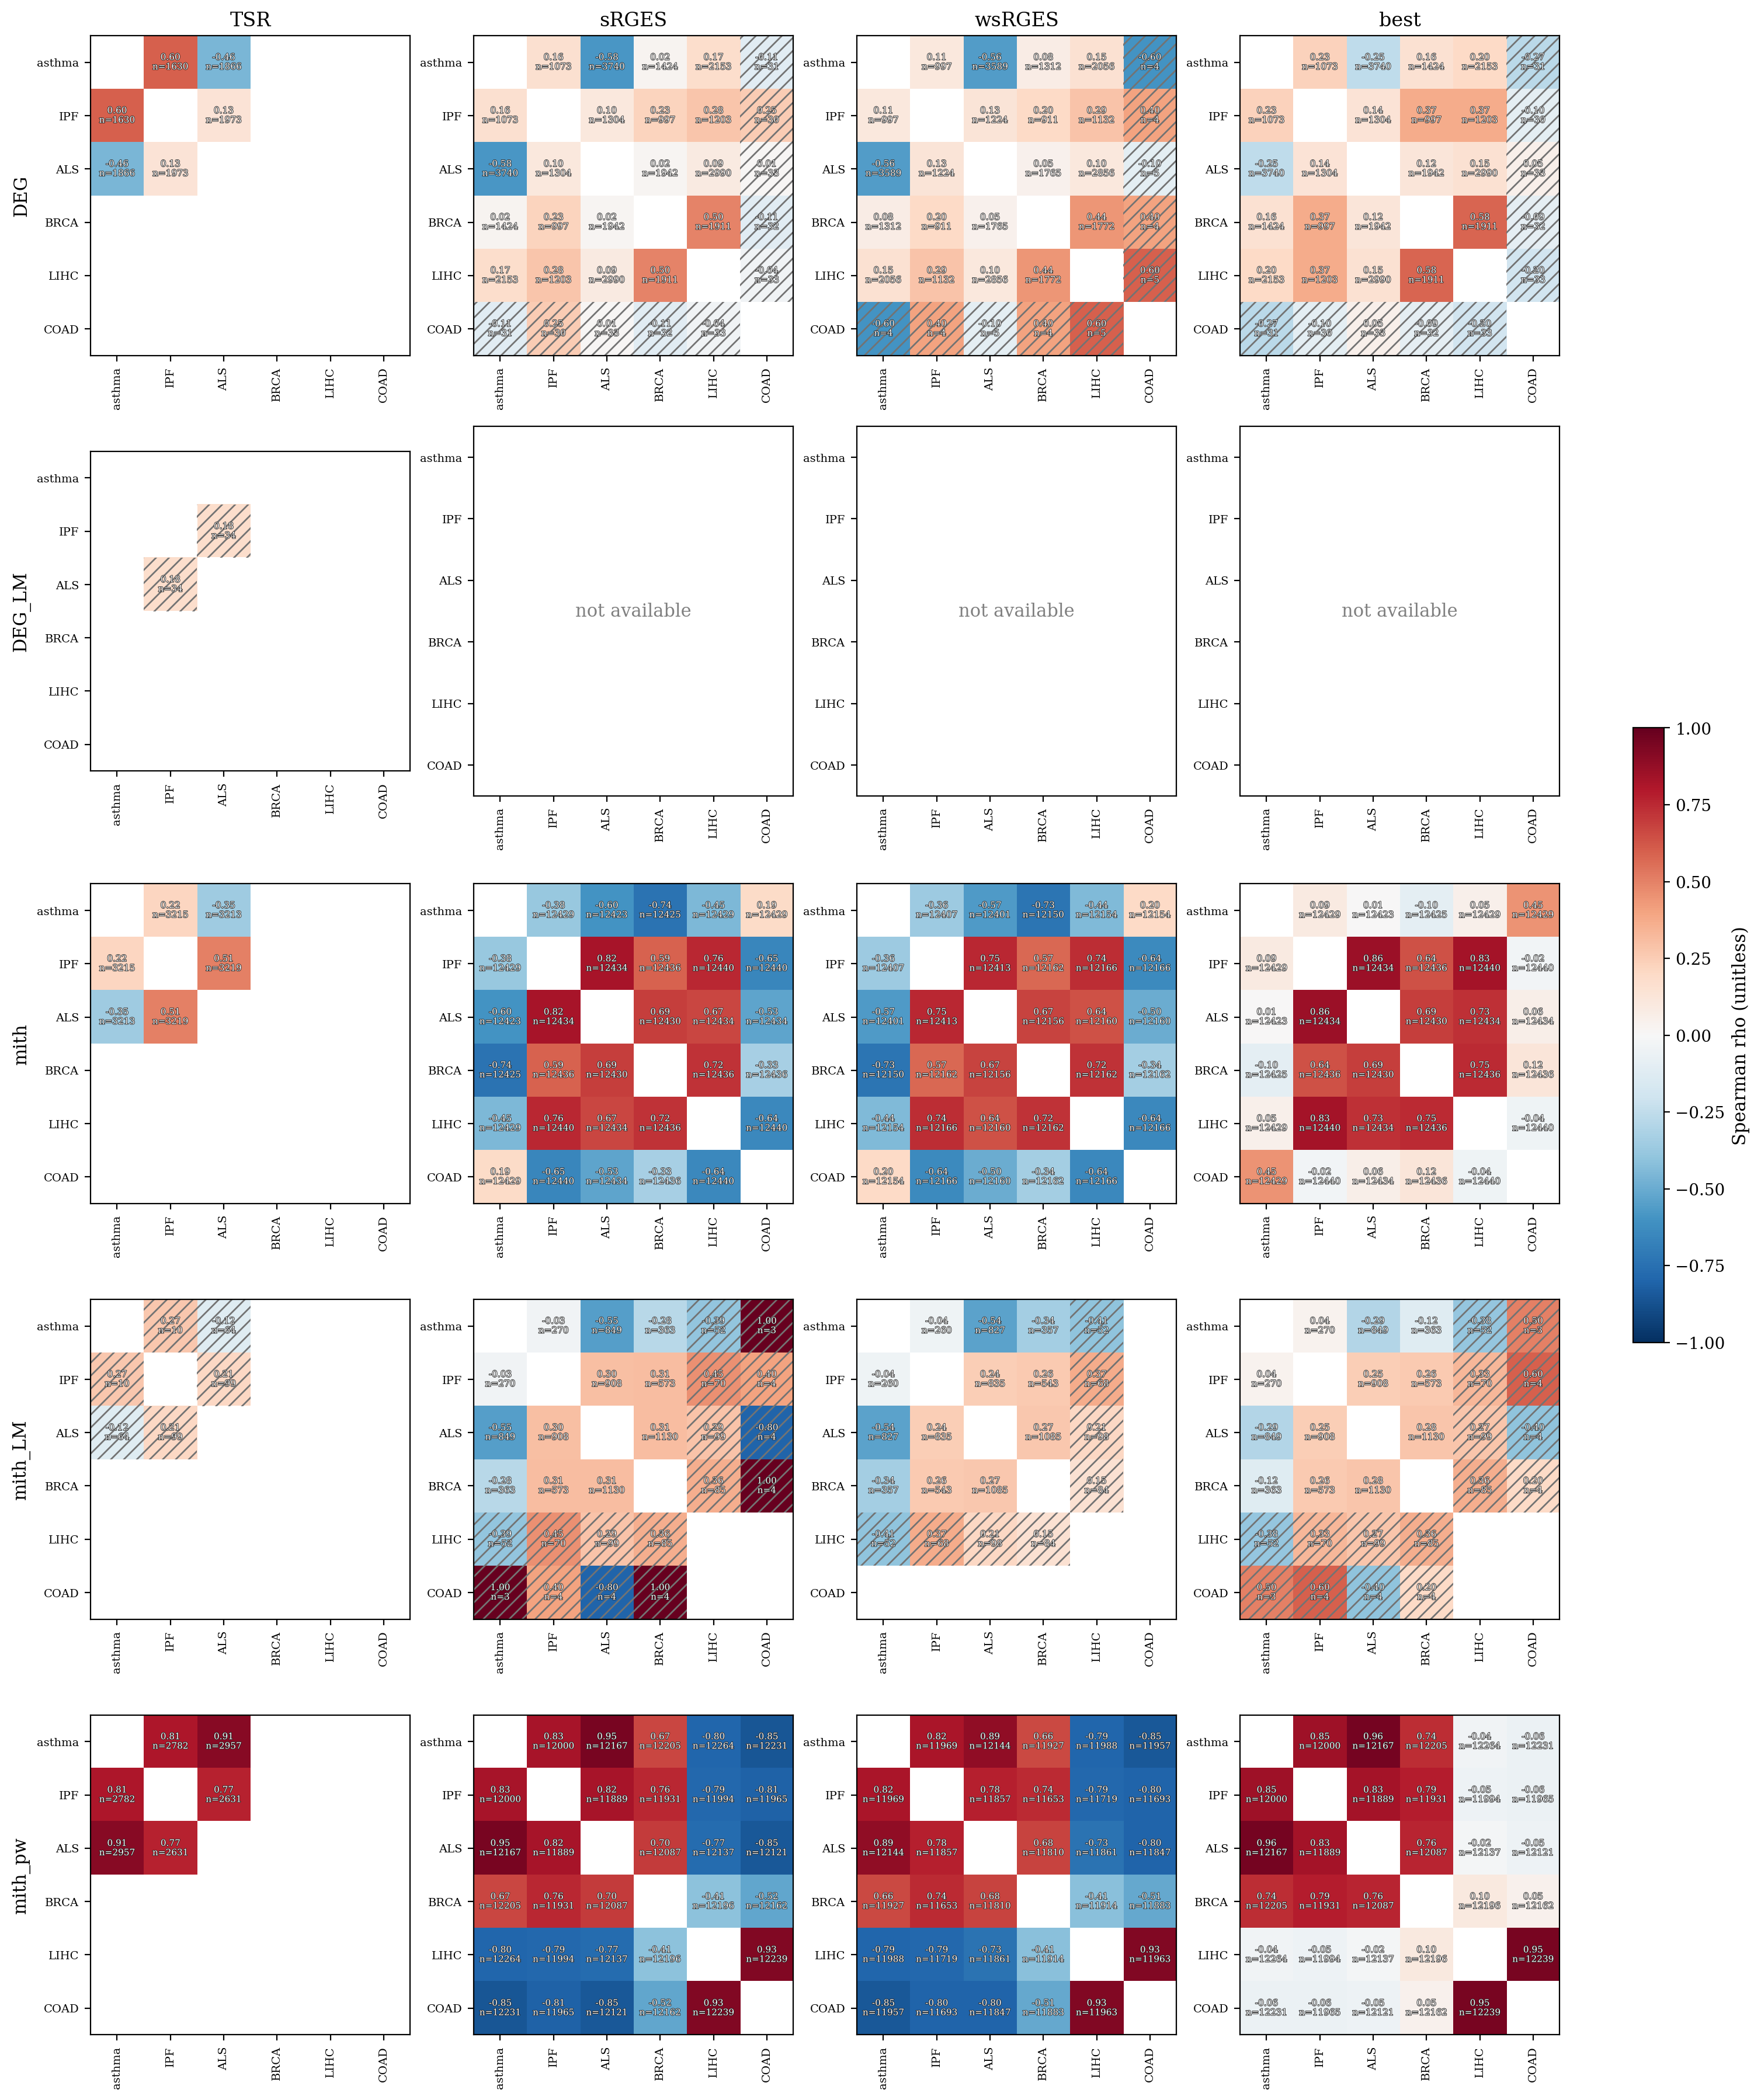

![Figure 1](../../../imgs/case_studies/cross_disease/cross_disease_supp_spearman_grid_pvalue_filtered_bh05.png)

**Figure 1.** Spearman rho of the CS on shared drugs for every model: rows = representation (configuration), columns = collapse (score type); each panel is a disease x disease matrix. Shared diverging scale centred at 0 (red positive, blue negative); values annotated; p-value-filtered rankings (BH <= 0.05). Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than 100 shared drugs.

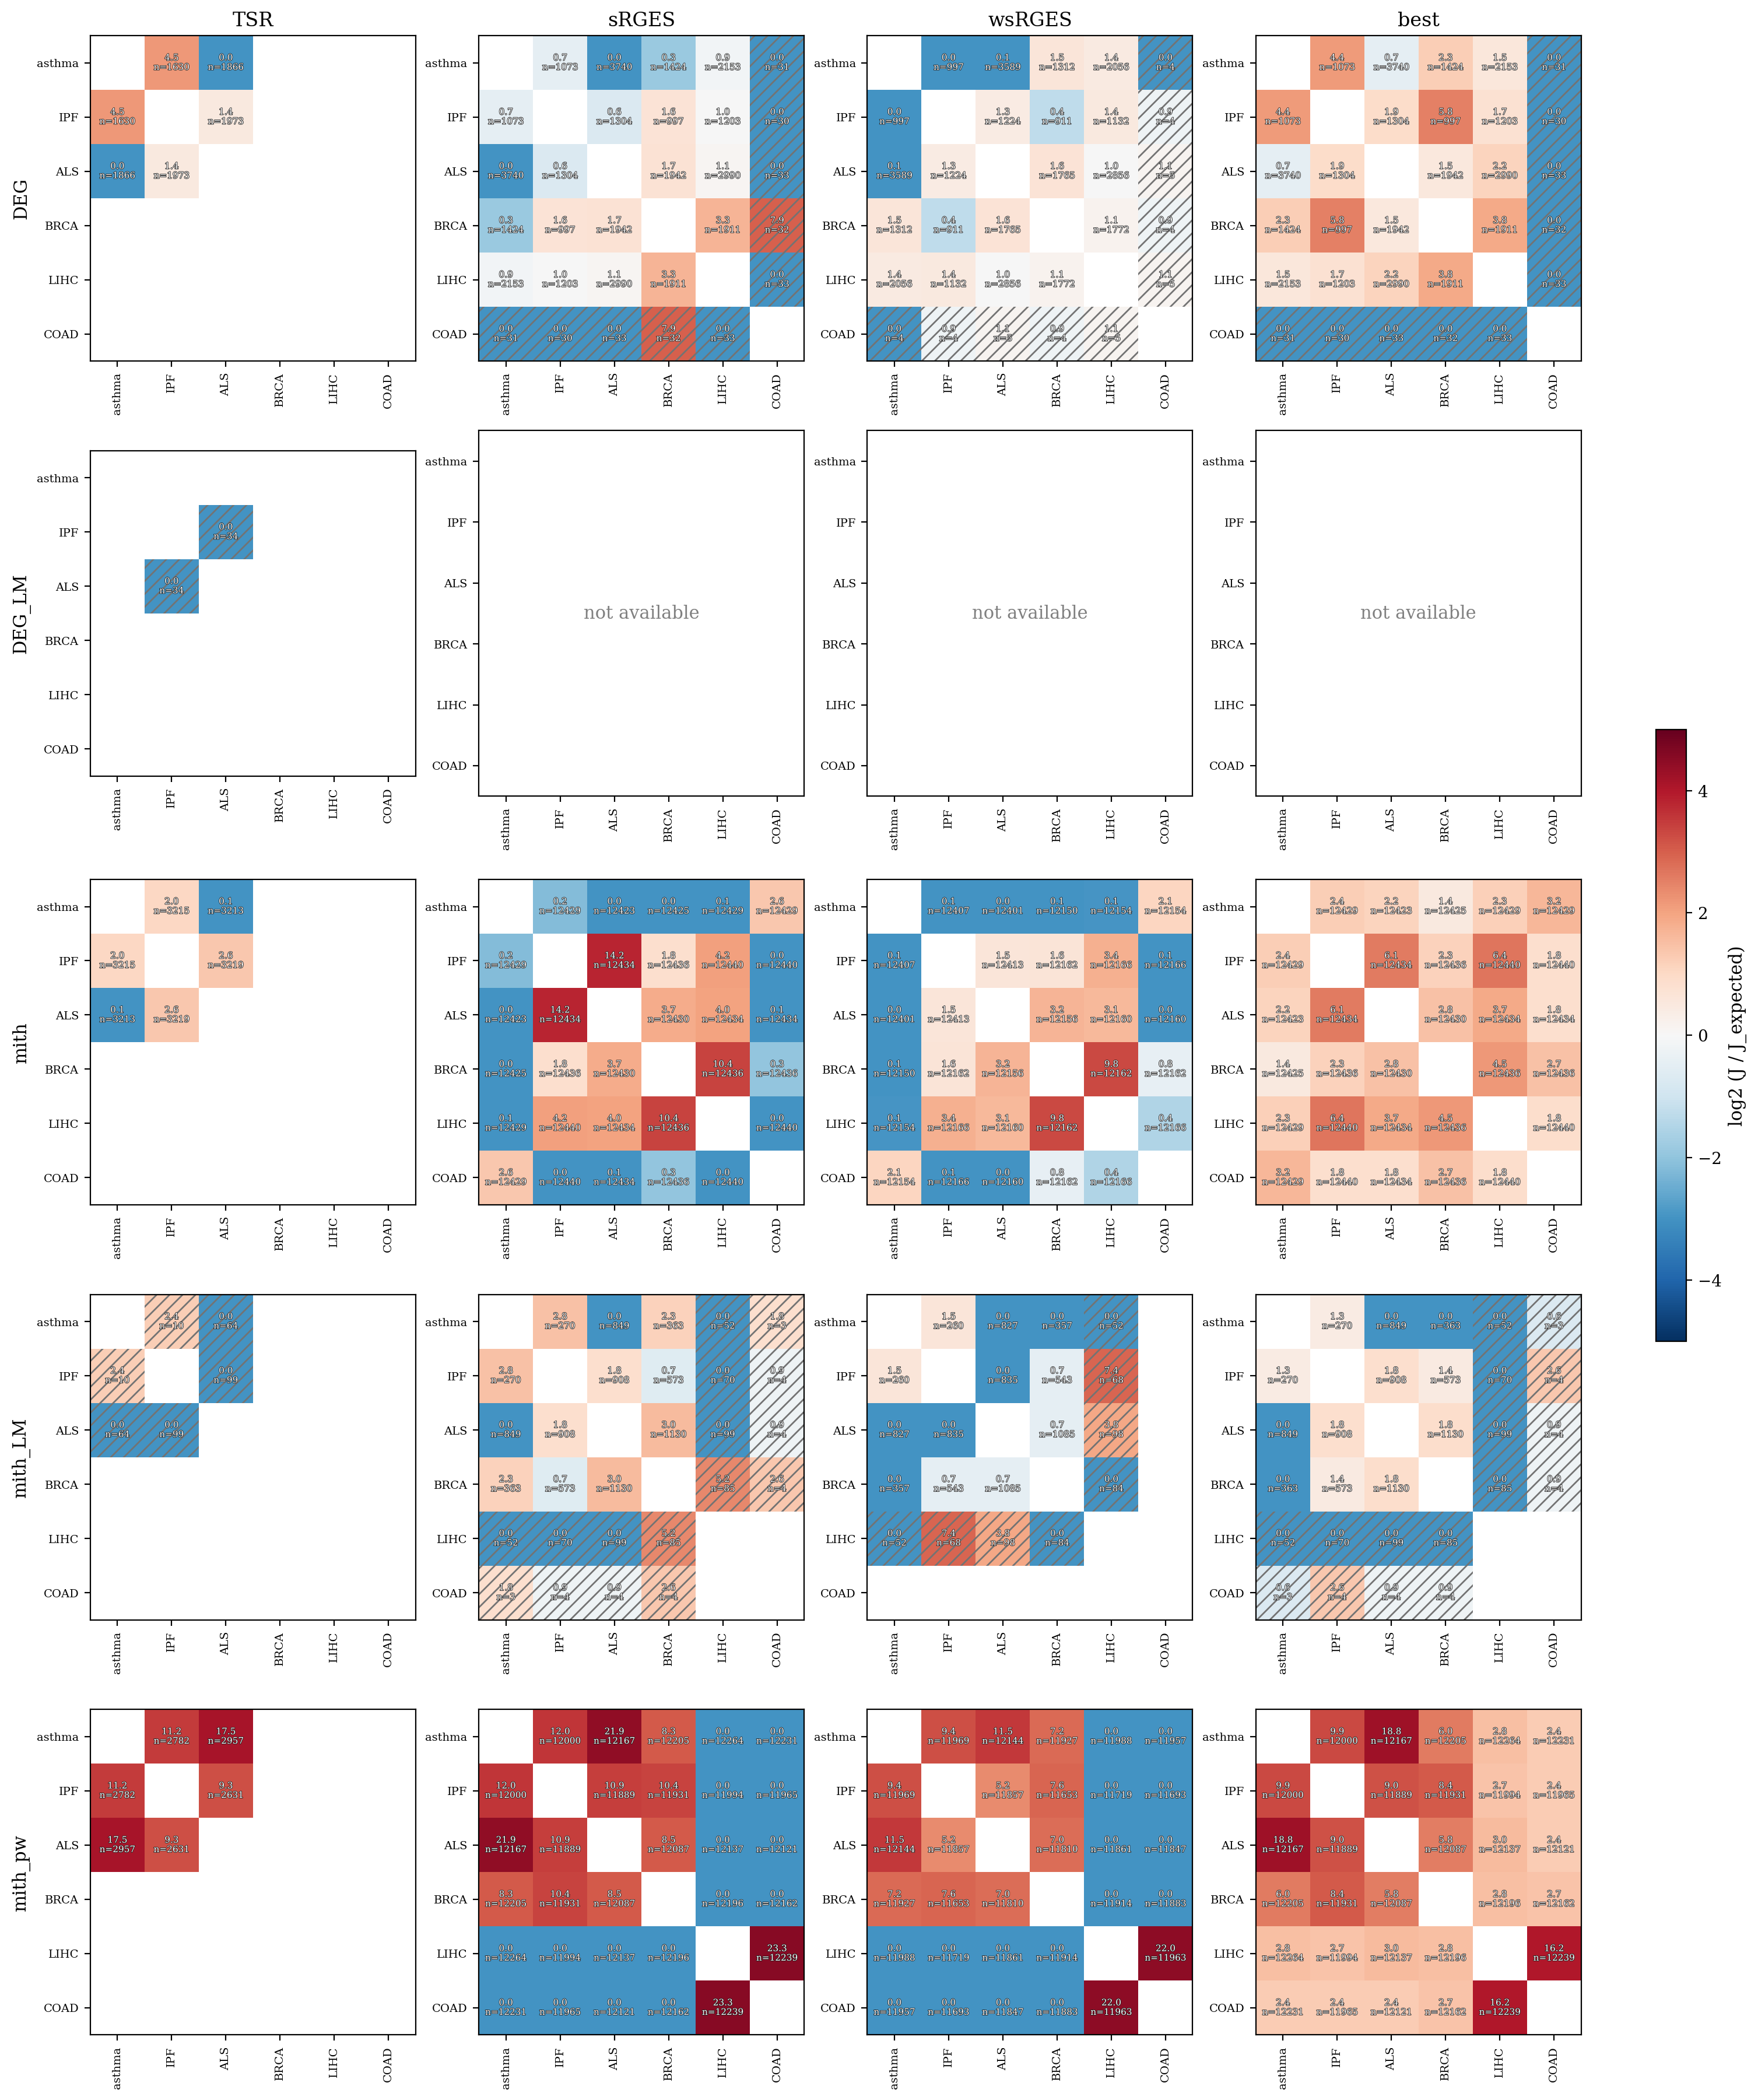

![Figure 2](../../../imgs/case_studies/cross_disease/cross_disease_supp_jaccard_grid_pvalue_filtered_bh05.png)

**Figure 2.** Jaccard index of the top 5% sets divided by its hypergeometric null (J / J_expected, annotated) for every model; colour = log2 of that ratio, diverging scale centred at 0 (= overlap expected by chance); rows = representation, columns = collapse; p-value-filtered rankings (BH <= 0.05). Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than 100 shared drugs.

In [8]:
# supplementary figure: representation (rows) x collapse (columns), disease x disease heatmaps
CFG_ROWS = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']; COL_COLS = ['TSR', 'sRGES', 'wsRGES', 'best']
def grid_fig(df, valcol, vmin, vmax, cmap, fmt, label, fname, caption):
    fig, axs = plt.subplots(len(CFG_ROWS), len(COL_COLS), figsize=(15, 18), constrained_layout=True)
    for i, c in enumerate(CFG_ROWS):
        for j, st in enumerate(COL_COLS):
            ax = axs[i, j]; ax.grid(False)
            d = df[(df['config'] == c) & (df['score_type'] == st)]
            ax.set_xticks(range(len(ds_all))); ax.set_yticks(range(len(ds_all)))
            ax.set_xticklabels(ds_all, rotation=90, fontsize=7); ax.set_yticklabels(ds_all, fontsize=7)
            if d.empty:
                ax.text(0.5, 0.5, 'not available', transform=ax.transAxes, ha='center', va='center', color='0.5'); ax.set_xlim(-.5, len(ds_all) - .5); ax.set_ylim(len(ds_all) - .5, -.5)
            else:
                Q = to_square(d, valcol).values
                im = ax.imshow(Q, vmin=vmin, vmax=vmax, cmap=cmap)
                Nn = to_square(d, 'n_shared').values
                for a in range(len(ds_all)):
                    for b in range(len(ds_all)):
                        if a != b and not np.isnan(Q[a, b]):
                            ax.text(b, a, f'{fmt(d_val(Q[a, b]))}\nn={int(Nn[a, b])}', ha='center', va='center', fontsize=5.5, color='white', path_effects=[pe.withStroke(linewidth=0.6, foreground='0.1')])
                            if Nn[a, b] < N_MARK: ax.add_patch(plt.Rectangle((b - .5, a - .5), 1, 1, fill=False, hatch='///', edgecolor='0.45', lw=0))
            if i == 0: ax.set_title(st)
            if j == 0: ax.set_ylabel(c, fontsize=11)
    fig.colorbar(im, ax=axs, shrink=0.3, label=label, location='right')
    show_fig(fig, fname, caption)

d_val = lambda v: v
grid_fig(S1, 'spearman', -1, 1, 'RdBu_r', lambda v: f'{v:.2f}', 'Spearman rho (unitless)', 'supp_spearman_grid',
         'Spearman rho of the CS on shared drugs for every model: rows = representation (configuration), columns = collapse (score type); each panel is a disease x disease matrix. Shared diverging scale centred at 0 (red positive, blue negative); values annotated; p-value-filtered rankings (BH <= 0.05). Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than ' + str(N_MARK) + ' shared drugs.')
J1['log2ratio'] = np.log2(J1['ratio'].clip(lower=2 ** -3))
lim = float(np.ceil(J1['log2ratio'].abs().max()))
d_val = lambda v: v
Jg = J1.assign(valtxt=J1['ratio'])
# annotate J / J_expected, colour = log2(J / J_expected) (centred at 0 = chance)
def grid_fig_j():
    fig, axs = plt.subplots(len(CFG_ROWS), len(COL_COLS), figsize=(15, 18), constrained_layout=True)
    for i, c in enumerate(CFG_ROWS):
        for j, st in enumerate(COL_COLS):
            ax = axs[i, j]; ax.grid(False)
            d = J1[(J1['config'] == c) & (J1['score_type'] == st)]
            ax.set_xticks(range(len(ds_all))); ax.set_yticks(range(len(ds_all)))
            ax.set_xticklabels(ds_all, rotation=90, fontsize=7); ax.set_yticklabels(ds_all, fontsize=7)
            if d.empty:
                ax.text(0.5, 0.5, 'not available', transform=ax.transAxes, ha='center', va='center', color='0.5'); ax.set_xlim(-.5, len(ds_all) - .5); ax.set_ylim(len(ds_all) - .5, -.5)
            else:
                Q = to_square(d, 'log2ratio').values; Rr = to_square(d, 'ratio').values; Jj = to_square(d, 'jaccard').values; Nn = to_square(d, 'n_shared').values
                im = ax.imshow(Q, vmin=-lim, vmax=lim, cmap='RdBu_r')
                for a in range(len(ds_all)):
                    for b in range(len(ds_all)):
                        if a != b and not np.isnan(Rr[a, b]):
                            ax.text(b, a, f'{Rr[a, b]:.1f}\nn={int(Nn[a, b])}', ha='center', va='center', fontsize=5.5, color='white', path_effects=[pe.withStroke(linewidth=0.6, foreground='0.1')])
                            if Nn[a, b] < N_MARK: ax.add_patch(plt.Rectangle((b - .5, a - .5), 1, 1, fill=False, hatch='///', edgecolor='0.45', lw=0))
            if i == 0: ax.set_title(st)
            if j == 0: ax.set_ylabel(c, fontsize=11)
    fig.colorbar(im, ax=axs, shrink=0.3, label='log2 (J / J_expected)', location='right')
    show_fig(fig, 'supp_jaccard_grid', f'Jaccard index of the top {JAC_K.replace("pct", "%")} sets divided by its hypergeometric null (J / J_expected, annotated) for every model; colour = log2 of that ratio, diverging scale centred at 0 (= overlap expected by chance); rows = representation, columns = collapse; p-value-filtered rankings (BH <= 0.05). Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than ' + str(N_MARK) + ' shared drugs.')
grid_fig_j()

### 2.2 Dot plot: one dot per model

For each disease pair, one dot per per-instance model: Spearman rho (left) and J / J_expected on a log scale (right; a ratio of 0 is off the axis). Colour = model family (DEG family: `DEG`; MITHrIL family: `mith`, `mith_LM`, `mith_pw`); diamonds = `mith_pw`; open squares = TSR models (shown for the non-cancer pairs, not averaged in); the black tick is the Fisher-z mean of rho (left) and the median ratio (right).

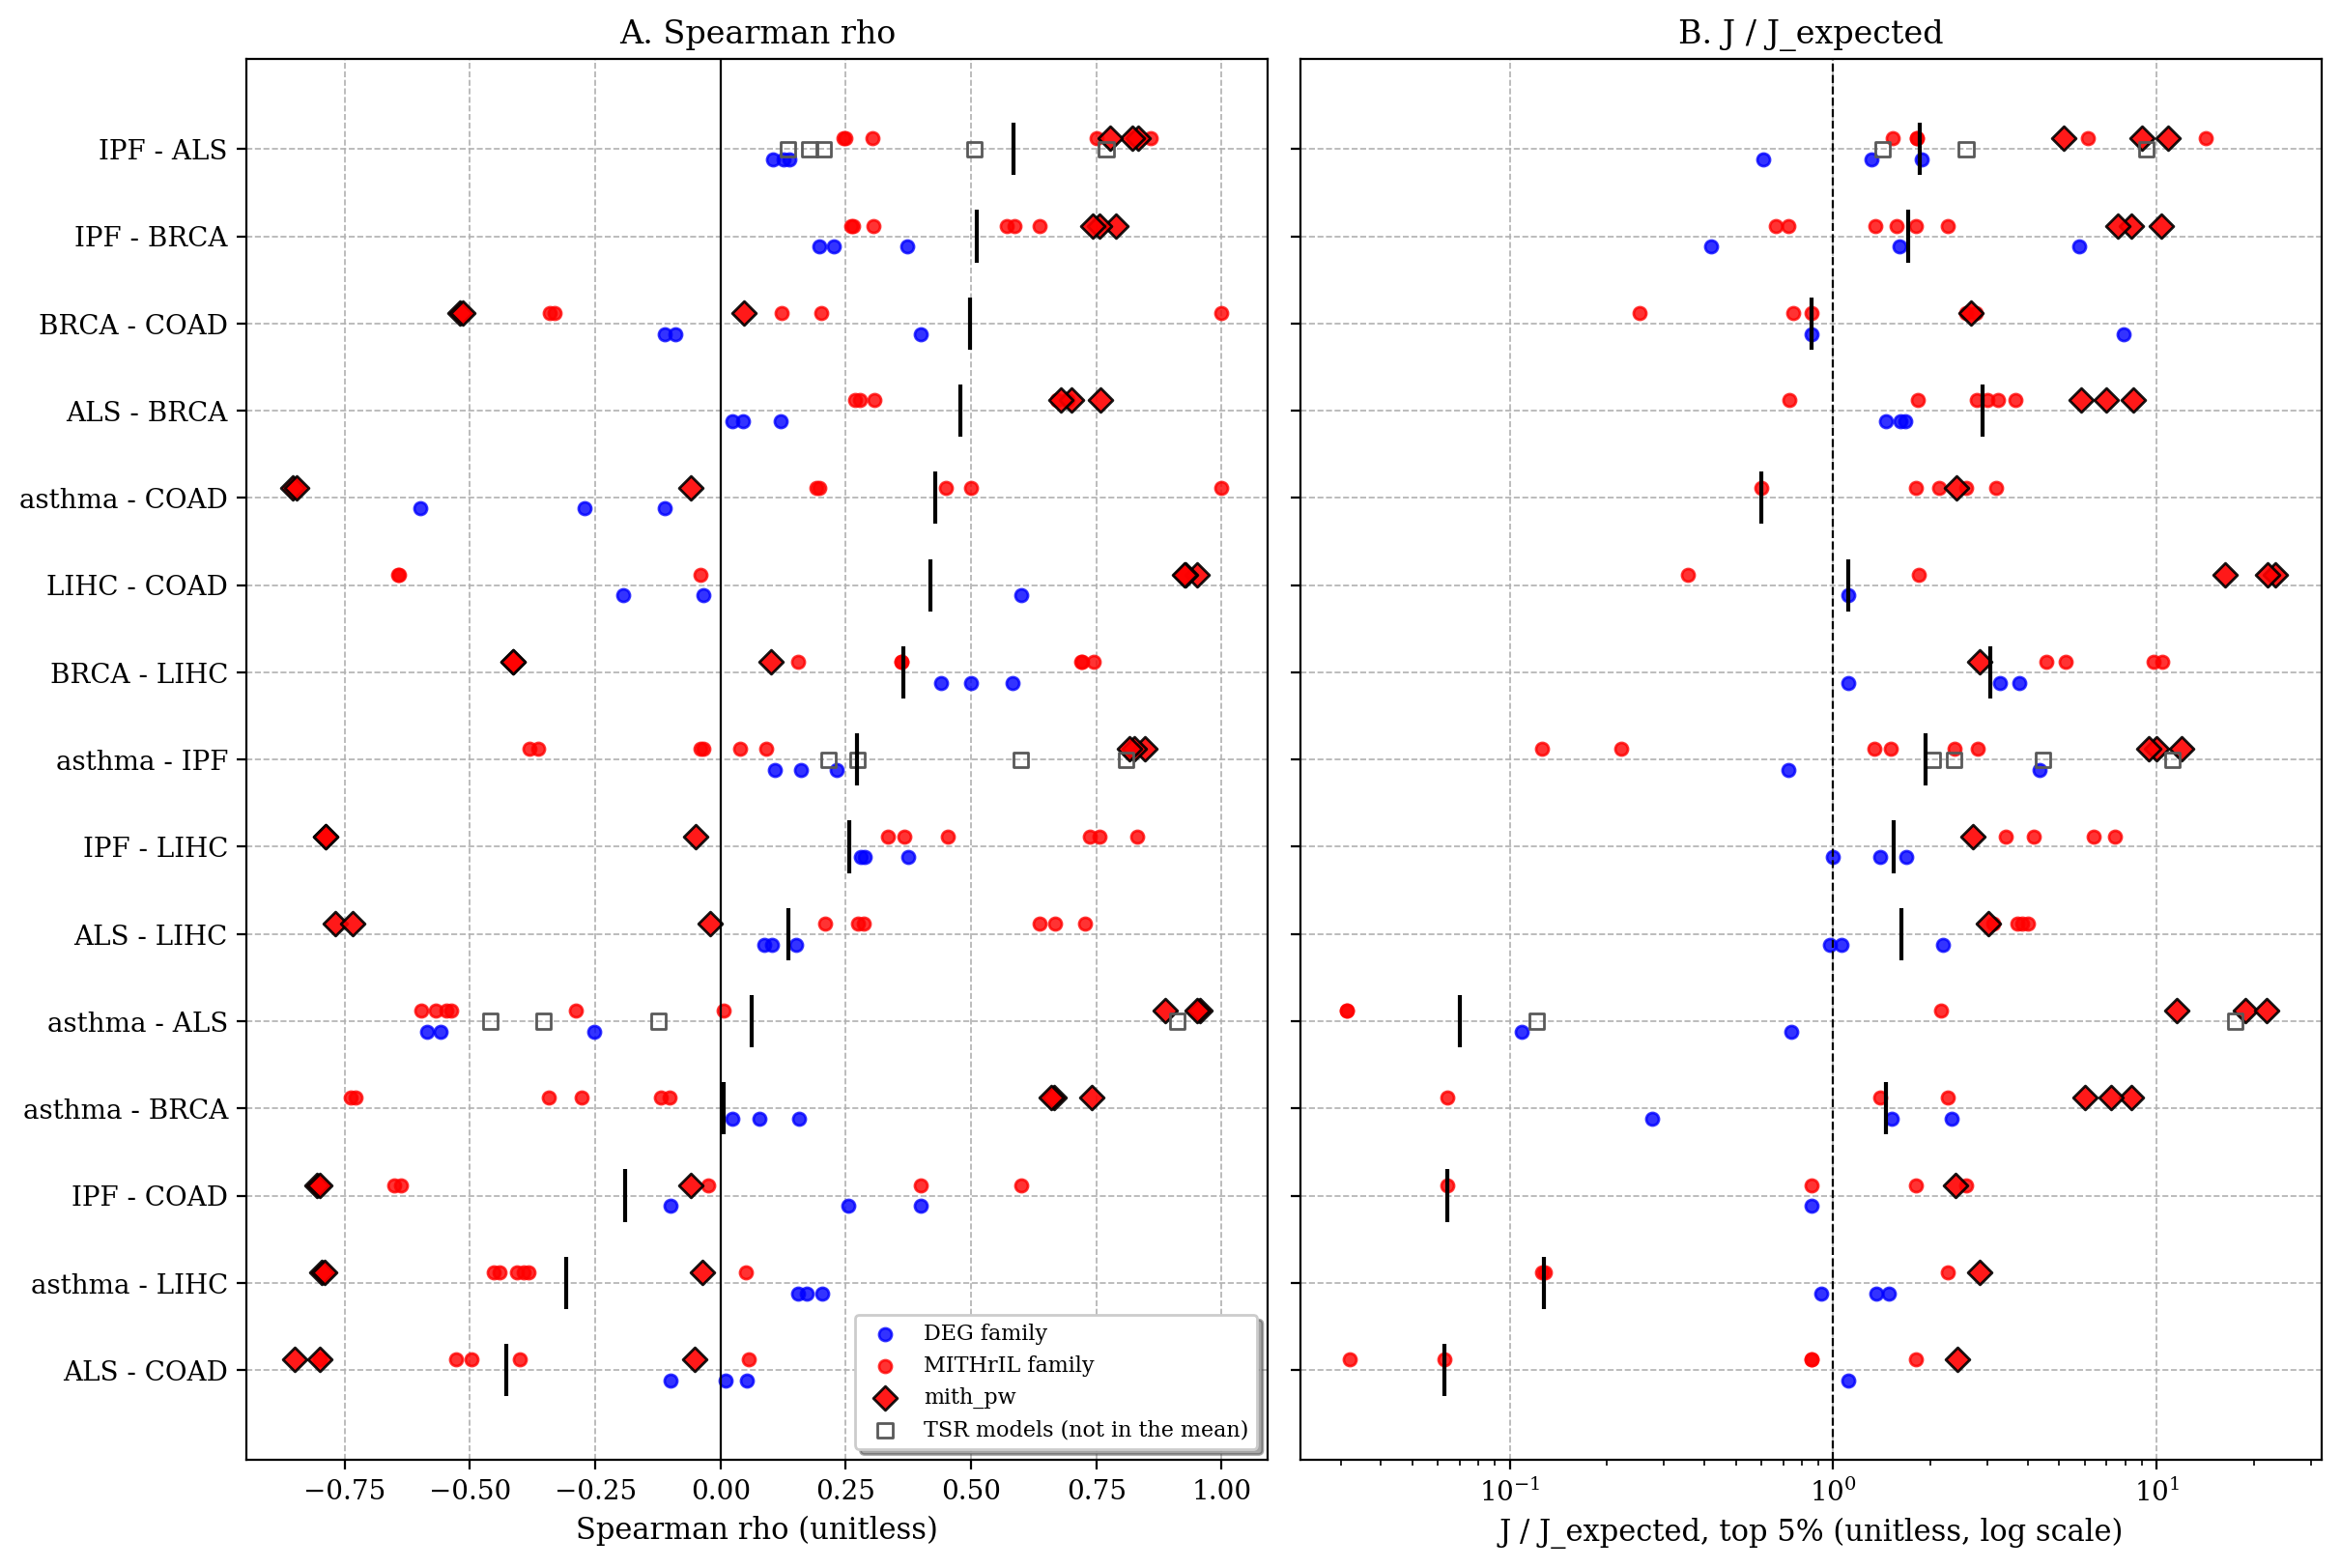

![Figure 3](../../../imgs/case_studies/cross_disease/cross_disease_dotplot_pairs_pvalue_filtered_bh05.png)

**Figure 3.** Agreement of drug rankings per disease pair, one dot per per-instance model (12 models). Blue = DEG (the only DEG-family per-instance configuration), red = MITHrIL family, diamonds = mith_pw, open squares = TSR models (non-cancer pairs only; not in the black tick), black tick = across per-instance-model summary (Fisher-z mean for rho, median for J / J_expected); pairs sorted by mean rho. B: dashed line = overlap expected by chance. P-value-filtered rankings (BH <= 0.05).

In [9]:
pair_lab = {p: f'{p[0]} - {p[1]}' for p in pairs}
order_pairs = sorted(pairs, key=lambda p: CP.set_index(['disease_a', 'disease_b']).loc[p, 'rho_fisher_mean'])
fig, axs = plt.subplots(1, 2, figsize=(12, 8), constrained_layout=True, sharey=True)
for ax, (df, col, xl) in zip(axs, [(S1p, 'spearman', 'Spearman rho (unitless)'), (J1p, 'ratio', f'J / J_expected, top {JAC_K.replace("pct", "%")} (unitless, log scale)')]):
    for yi, p in enumerate(order_pairs):
        d = df[(df['disease_a'] == p[0]) & (df['disease_b'] == p[1])]
        for fam, c in FAM_COL.items():
            v = d[(d['family_name'] == fam) & (d['config'] != 'mith_pw')]; w = d[d['config'] == 'mith_pw']
            off = -0.12 if fam == 'DEG family' else 0.12
            ax.scatter(v[col], np.full(len(v), yi) + off, s=22, color=c, alpha=0.8, label=fam if yi == 0 else None)
            if fam == 'MITHrIL family': ax.scatter(w[col], np.full(len(w), yi) + off, s=40, color=c, marker='D', edgecolor='k', alpha=0.9, label='mith_pw' if yi == 0 else None)
        dt = (S1t if col == 'spearman' else J1t); dt = dt[(dt['disease_a'] == p[0]) & (dt['disease_b'] == p[1])]
        ax.scatter(dt[col], np.full(len(dt), yi), s=30, facecolor='none', edgecolor='0.35', marker='s', label='TSR models (not in the mean)' if (yi == 0 and col == 'spearman') else None)
        m = CP.set_index(['disease_a', 'disease_b']).loc[p, 'rho_fisher_mean' if col == 'spearman' else 'ratio_median']
        ax.vlines(m, yi - 0.3, yi + 0.3, color='k')
    ax.set_yticks(range(len(order_pairs))); ax.set_yticklabels([pair_lab[p] for p in order_pairs]); ax.set_xlabel(xl)
    if col == 'spearman': ax.axvline(0, color='k', lw=0.8)
    else: ax.set_xscale('log'); ax.axvline(1, color='k', lw=0.8, ls='--')
axs[0].legend(fontsize=8, loc='lower right'); axs[0].set_title('A. Spearman rho'); axs[1].set_title('B. J / J_expected')
show_fig(fig, 'dotplot_pairs', 'Agreement of drug rankings per disease pair, one dot per per-instance model (12 models). Blue = DEG (the only DEG-family per-instance configuration), red = MITHrIL family, diamonds = mith_pw, open squares = TSR models (non-cancer pairs only; not in the black tick), black tick = across per-instance-model summary (Fisher-z mean for rho, median for J / J_expected); pairs sorted by mean rho. B: dashed line = overlap expected by chance. P-value-filtered rankings (BH <= 0.05).')

### 2.3 Model families

DEG family vs MITHrIL family (`mith`, `mith_LM`, `mith_pw`), and `mith_pw` on its own, on the per-instance models only. The per-instance runs contain no `DEG_LM` model, so the DEG family is `DEG` alone (3 models: sRGES, wsRGES, best) against 9 MITHrIL models (3 per configuration). Per family: Fisher-z mean rho and median J / J_expected over its models. The family difference
(MITHrIL minus DEG) carries a 95% bootstrap interval per disease pair: `N_BOOT` resamples (seed 0) of the drugs with replacement, the same resample used for every model of a pair; each model's rho (Pearson correlation of the ranks of the shared drugs,
with multiplicity weights) and J / J_expected (top 5% of the distinct resampled drugs) is recomputed, then summarised by family. Intervals are the 2.5 and 97.5 percentiles. The resampling is over drugs only: the models are fixed, so the intervals describe the stability of the difference under drug resampling, not variation across models.

In [10]:
from scipy.stats import rankdata
rng = np.random.default_rng(SEED)
key_index = {k: i for i, k in enumerate(sorted(set(R['drug_key'])))}
nU = len(key_index)
FAMS = {'DEG family': ['DEG'], 'MITHrIL family': ['mith', 'mith_LM', 'mith_pw'], 'mith_pw': ['mith_pw']}
model_cfg = sl.set_index('model')['config'].to_dict()
piv = {}
for slc, g in R.groupby('model', observed=True):
    p = g.pivot(index='drug_key', columns='disease', values='score')
    piv[slc] = p
fam_of = sl.set_index('model')['family'].to_dict()
models_by_pair = {p: [s for s, pv in piv.items() if fam_of.get(s) == 'per-instance' and p[0] in pv.columns and p[1] in pv.columns and (pv[p[0]].notna() & pv[p[1]].notna()).sum() >= MIN_SHARED] for p in pairs}

def boot_pair(p):
    mods = []
    for s in models_by_pair[p]:
        pv = piv[s]; m = pv[p[0]].notna() & pv[p[1]].notna()
        x, y = pv.loc[m, p[0]], pv.loc[m, p[1]]
        mods.append(dict(model=s, cfg=model_cfg[s], pos=np.array([key_index[k] for k in x.index]), rx=rankdata(x.values), ry=rankdata(y.values)))
    B = N_BOOT
    rho = np.full((B, len(mods)), np.nan); ratio = np.full((B, len(mods)), np.nan)
    for b in range(B):
        counts = np.bincount(rng.integers(0, nU, nU), minlength=nU)
        for mi, m in enumerate(mods):
            w = counts[m['pos']].astype(float); n = w.sum()
            mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n
            cov = (w * (m['rx'] - mx) * (m['ry'] - my)).sum()
            den = np.sqrt((w * (m['rx'] - mx) ** 2).sum() * (w * (m['ry'] - my) ** 2).sum())
            rho[b, mi] = cov / den
            inc = w > 0; nn = int(inc.sum()); k = max(2, int(round(TOP_FRAC * nn)))
            if k < nn:
                a = m['rx'][inc]; c = m['ry'][inc]
                ov = int(((a <= np.partition(a, k - 1)[k - 1]) & (c <= np.partition(c, k - 1)[k - 1])).sum())
                ratio[b, mi] = (ov / (2 * k - ov)) / jaccard_null(nn, k)
    return mods, rho, ratio

fam_rows, diff_rows = [], []
for p in pairs:
    mods, rho, ratio = boot_pair(p)
    cfgs = np.array([m['cfg'] for m in mods])
    est = {}
    for fam, cl in FAMS.items():
        idx = [i for i, c in enumerate(cfgs) if c in cl]
        if not idx: continue
        zb = np.tanh(np.arctanh(np.clip(rho[:, idx], -0.999999, 0.999999)).mean(axis=1)); rb = np.nanmedian(ratio[:, idx], axis=1)
        s1 = S1p[(S1p['disease_a'] == p[0]) & (S1p['disease_b'] == p[1]) & (S1p['config'].isin(cl))]; j1 = J1p[(J1p['disease_a'] == p[0]) & (J1p['disease_b'] == p[1]) & (J1p['config'].isin(cl))]
        est[fam] = (fisher_mean(s1['spearman'].values), j1['ratio'].median(), zb, rb)
        fam_rows.append({'disease_a': p[0], 'disease_b': p[1], 'family': fam, 'n_models': len(idx), 'rho_fisher_mean': est[fam][0], 'ratio_median': est[fam][1]})
    if 'DEG family' in est and 'MITHrIL family' in est:
        e1, e2 = est['MITHrIL family'], est['DEG family']
        dz = np.arctanh(e1[2].clip(-0.999999, 0.999999)) - np.arctanh(e2[2].clip(-0.999999, 0.999999))
        diff_rows.append({'disease_a': p[0], 'disease_b': p[1], 'rho_diff_z': np.arctanh(e1[0]) - np.arctanh(e2[0]), 'rho_diff_z_lo': np.percentile(dz, 2.5), 'rho_diff_z_hi': np.percentile(dz, 97.5),
                          'ratio_diff': e1[1] - e2[1], 'ratio_diff_lo': np.nanpercentile(e1[3] - e2[3], 2.5), 'ratio_diff_hi': np.nanpercentile(e1[3] - e2[3], 97.5),
                          'rho_diff': e1[0] - e2[0], 'rho_diff_lo': np.percentile(e1[2] - e2[2], 2.5), 'rho_diff_hi': np.percentile(e1[2] - e2[2], 97.5)})
FR = pd.DataFrame(fam_rows); DR = pd.DataFrame(diff_rows)
save(FR, 'family_collapse'); save(DR, 'family_difference_bootstrap')
for fam in FAMS:
    f = FR[FR['family'] == fam]
    if f.empty: continue
    nm = int(f['n_models'].iloc[0]); nshp = f"shared drugs per pair {NSH_PI}"
    show_table(to_square(f, 'rho_fisher_mean'), f'{fam} ({", ".join(FAMS[fam])}; {nm} per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; {nshp}.', fmt='{:.2f}', index=True)
    show_table(to_square(f, 'ratio_median'), f'{fam} ({nm} per-instance models): median J / J_expected (top {JAC_K.replace("pct", "%")}; unitless) per disease pair; {nshp}.', fmt='{:.1f}', index=True)
DRt = DR.assign(pair=DR['disease_a'] + ' - ' + DR['disease_b'], pair_class=[pair_class(a, b) for a, b in zip(DR['disease_a'], DR['disease_b'])])
t = DRt[['pair', 'pair_class', 'rho_diff', 'rho_diff_lo', 'rho_diff_hi', 'ratio_diff', 'ratio_diff_lo', 'ratio_diff_hi']]
show_table(t, f'Difference MITHrIL family minus DEG family per disease pair: in Fisher-z-mean rho (unitless; difference of the family rhos) and in median J / J_expected (unitless), each with a 95% bootstrap interval (lo, hi) over {N_BOOT} resamples of the shared drugs (seed {SEED}); 3 DEG models vs 9 MITHrIL models, per-instance only. The resampling is over drugs only, so an interval excluding 0 means that the difference is stable under drug resampling; it does not test variation across models or configurations (the models of a family are correlated and differ in composition).', fmt='{:.2f}')
sq = lambda c: to_square(DR, c)
show_table(sq('rho_diff'), 'Difference MITHrIL family minus DEG family in Fisher-z-mean Spearman rho (unitless), per disease pair.', fmt='{:.2f}', index=True)

/tmp/ipykernel_97609/110187111.py:29: RuntimeWarning: invalid value encountered in scalar divide
  rho[b, mi] = cov / den
/tmp/ipykernel_97609/110187111.py:26: RuntimeWarning: invalid value encountered in scalar divide
  mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n


/tmp/ipykernel_97609/110187111.py:29: RuntimeWarning: invalid value encountered in scalar divide
  rho[b, mi] = cov / den
/tmp/ipykernel_97609/110187111.py:26: RuntimeWarning: invalid value encountered in scalar divide
  mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n


/tmp/ipykernel_97609/110187111.py:26: RuntimeWarning: invalid value encountered in scalar divide
  mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n
/tmp/ipykernel_97609/110187111.py:29: RuntimeWarning: invalid value encountered in scalar divide
  rho[b, mi] = cov / den


/tmp/ipykernel_97609/110187111.py:29: RuntimeWarning: invalid value encountered in scalar divide
  rho[b, mi] = cov / den
/tmp/ipykernel_97609/110187111.py:26: RuntimeWarning: invalid value encountered in scalar divide
  mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n


/tmp/ipykernel_97609/110187111.py:29: RuntimeWarning: invalid value encountered in scalar divide
  rho[b, mi] = cov / den
/tmp/ipykernel_97609/110187111.py:26: RuntimeWarning: invalid value encountered in scalar divide
  mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n


**Table 16.** DEG family (DEG; 3 per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.17 | -0.48 | 0.09 | 0.18 | -0.35 |
| IPF | 0.17 |  | 0.12 | 0.27 | 0.31 | 0.19 |
| ALS | -0.48 | 0.12 |  | 0.06 | 0.11 | -0.01 |
| BRCA | 0.09 | 0.27 | 0.06 |  | 0.51 | 0.07 |
| LIHC | 0.18 | 0.31 | 0.11 | 0.51 |  | 0.15 |
| COAD | -0.35 | 0.19 | -0.01 | 0.07 | 0.15 |  |

... (3 outputs left out)

**Table 20.** mith_pw (mith_pw; 3 per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.83 | 0.94 | 0.69 | -0.62 | -0.69 |
| IPF | 0.83 |  | 0.81 | 0.76 | -0.62 | -0.64 |
| ALS | 0.94 | 0.81 |  | 0.71 | -0.58 | -0.67 |
| BRCA | 0.69 | 0.76 | 0.71 |  | -0.25 | -0.35 |
| LIHC | -0.62 | -0.62 | -0.58 | -0.25 |  | 0.94 |
| COAD | -0.69 | -0.64 | -0.67 | -0.35 | 0.94 |  |

**Table 21.** mith_pw (3 per-instance models): median J / J_expected (top 5%; unitless) per disease pair; shared drugs per pair 3-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 9.9 | 18.8 | 7.2 | 0.0 | 0.0 |
| IPF | 9.9 |  | 9.0 | 8.4 | 0.0 | 0.0 |
| ALS | 18.8 | 9.0 |  | 7.0 | 0.0 | 0.0 |
| BRCA | 7.2 | 8.4 | 7.0 |  | 0.0 | 0.0 |
| LIHC | 0.0 | 0.0 | 0.0 | 0.0 |  | 22.0 |
| COAD | 0.0 | 0.0 | 0.0 | 0.0 | 22.0 |  |

**Table 22.** Difference MITHrIL family minus DEG family per disease pair: in Fisher-z-mean rho (unitless; difference of the family rhos) and in median J / J_expected (unitless), each with a 95% bootstrap interval (lo, hi) over 1000 resamples of the shared drugs (seed 0); 3 DEG models vs 9 MITHrIL models, per-instance only. The resampling is over drugs only, so an interval excluding 0 means that the difference is stable under drug resampling; it does not test variation across models or configurations (the models of a family are correlated and differ in composition).

| pair | pair_class | rho_diff | rho_diff_lo | rho_diff_hi | ratio_diff | ratio_diff_lo | ratio_diff_hi |
|---|---|---|---|---|---|---|---|
| asthma - IPF | non-cancer | 0.14 | 0.08 | 0.19 | 1.64 | -0.42 | 2.55 |
| asthma - ALS | non-cancer | 0.73 | 0.70 | 0.76 | -0.08 | -0.17 | 0.56 |
| asthma - BRCA | cancer vs non-cancer | -0.11 | -0.16 | -0.05 | -0.12 | -1.90 | 0.96 |
| asthma - LIHC | cancer vs non-cancer | -0.63 | -0.71 | -0.55 | -1.36 | -1.77 | -0.60 |
| asthma - COAD | cancer vs non-cancer | 0.99 |  |  | 1.96 | -0.52 | 2.53 |
| IPF - ALS | non-cancer | 0.57 | 0.53 | 0.61 | 3.86 | 2.91 | 4.87 |
| IPF - BRCA | cancer vs non-cancer | 0.31 | 0.26 | 0.36 | 0.20 | -0.55 | 1.70 |
| IPF - LIHC | cancer vs non-cancer | -0.08 | -0.17 | 0.01 | 1.31 | -2.23 | 1.91 |
| IPF - COAD | cancer vs non-cancer | -0.52 |  |  | 0.46 | -1.46 | 0.93 |
| ALS - BRCA | cancer vs non-cancer | 0.53 | 0.49 | 0.56 | 1.61 | 0.82 | 2.53 |
| ALS - LIHC | cancer vs non-cancer | 0.03 | -0.03 | 0.10 | 1.95 | -1.58 | 2.29 |
| ALS - COAD | cancer vs non-cancer | -0.54 |  |  | 0.46 | -2.54 | 0.48 |
| BRCA - LIHC | cancer-cancer | -0.20 | -0.26 | -0.13 | -0.43 | -3.82 | 1.43 |
| BRCA - COAD | cancer-cancer | 0.54 |  |  | -0.05 | -6.53 | 0.66 |
| LIHC - COAD | cancer-cancer | 0.38 |  |  | 9.04 | 6.26 | 9.55 |

**Table 23.** Difference MITHrIL family minus DEG family in Fisher-z-mean Spearman rho (unitless), per disease pair.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.14 | 0.73 | -0.11 | -0.63 | 0.99 |
| IPF | 0.14 |  | 0.57 | 0.31 | -0.08 | -0.52 |
| ALS | 0.73 | 0.57 |  | 0.53 | 0.03 | -0.54 |
| BRCA | -0.11 | 0.31 | 0.53 |  | -0.20 | 0.54 |
| LIHC | -0.63 | -0.08 | 0.03 | -0.20 |  | 0.38 |
| COAD | 0.99 | -0.52 | -0.54 | 0.54 | 0.38 |  |

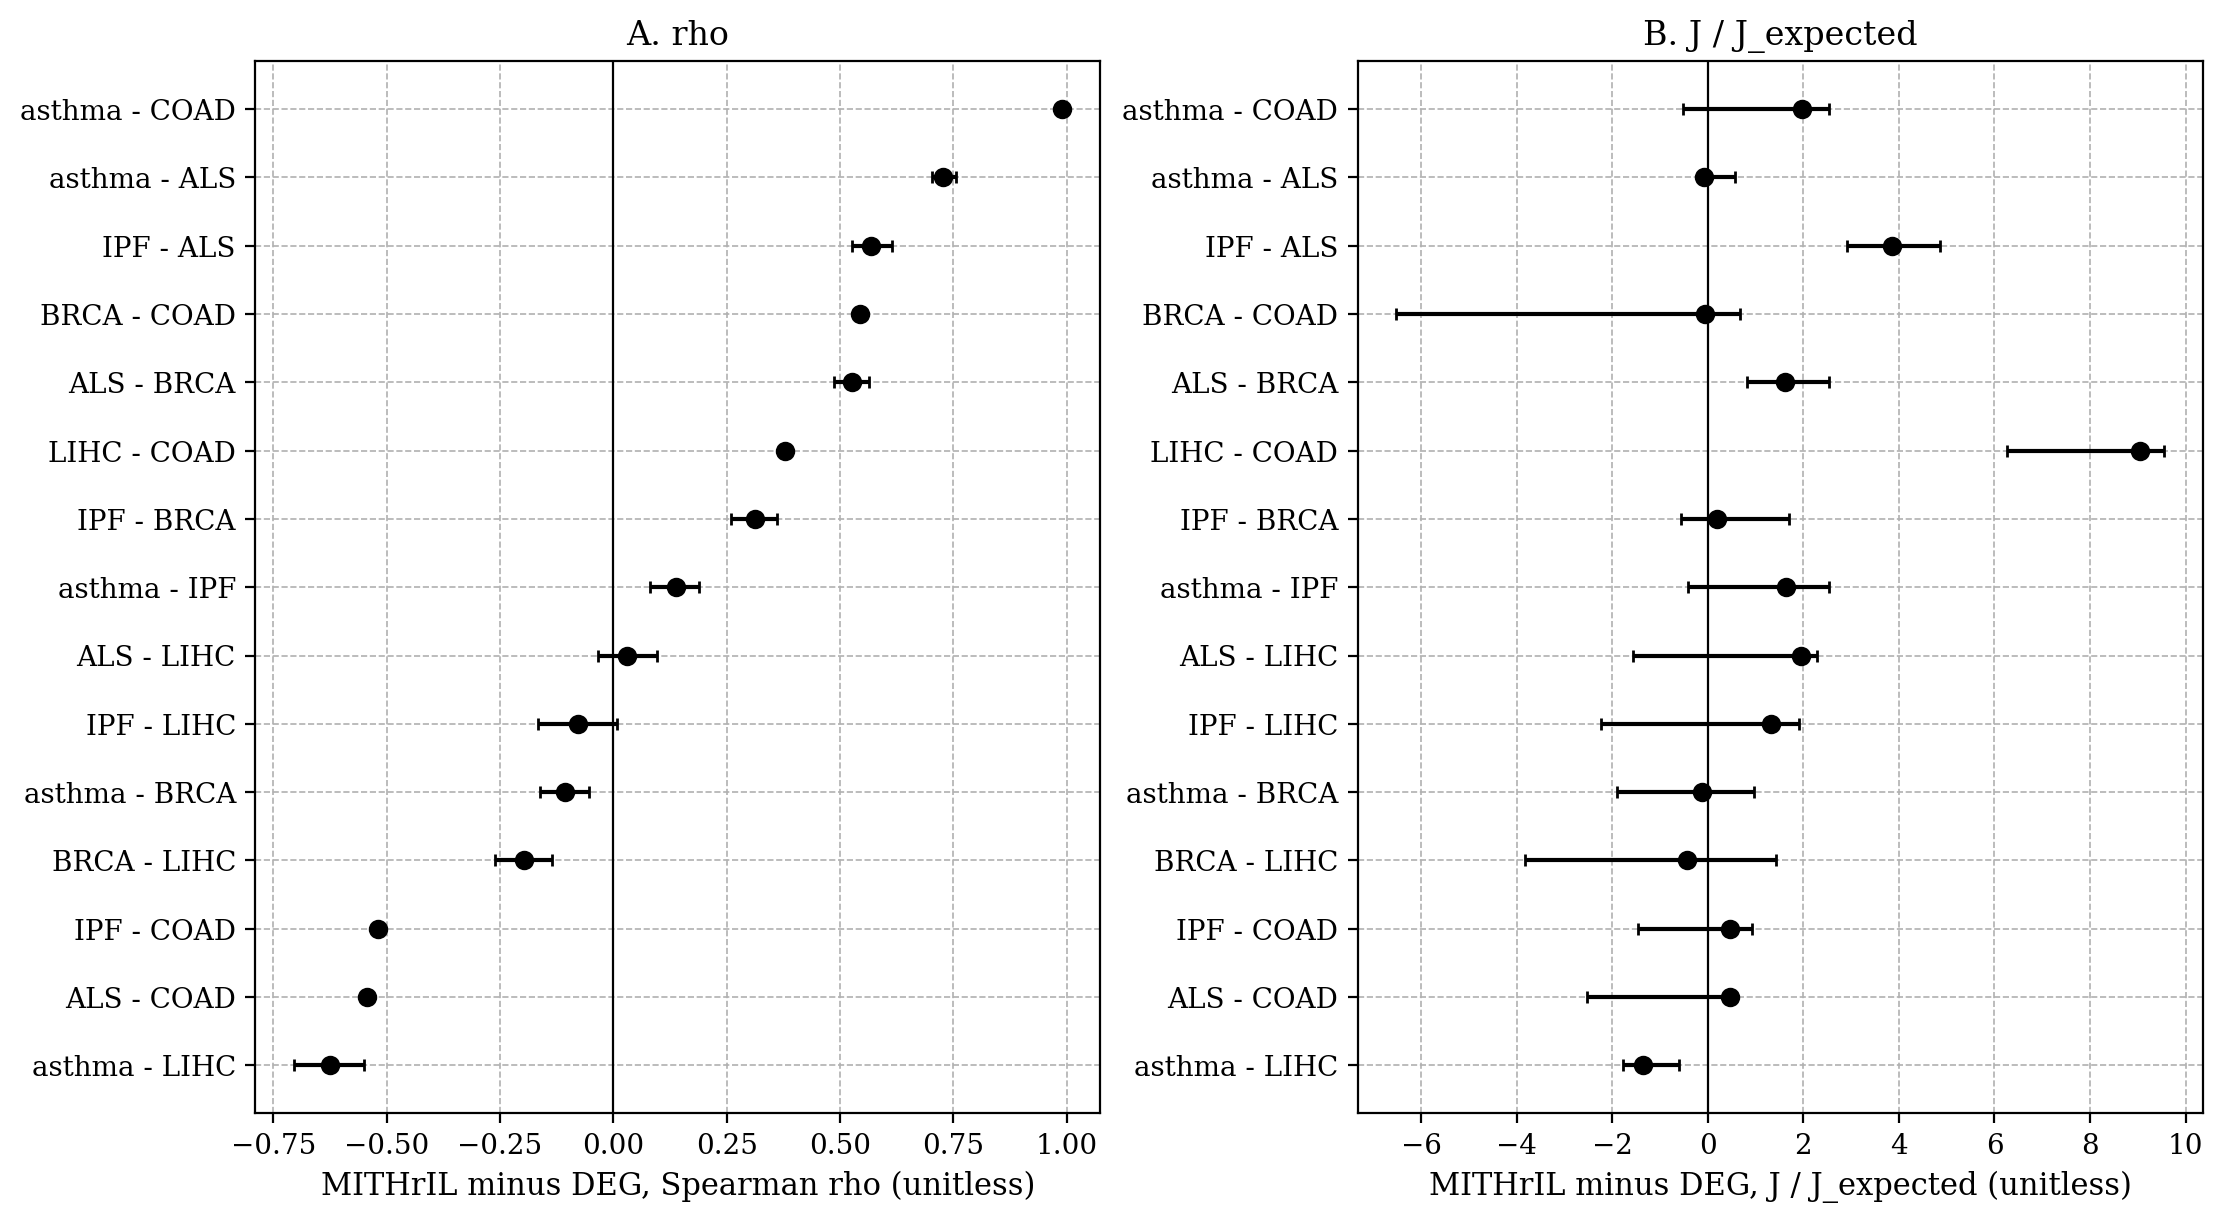

![Figure 4](../../../imgs/case_studies/cross_disease/cross_disease_family_difference_pvalue_filtered_bh05.png)

**Figure 4.** Difference between the MITHrIL family and the DEG family per disease pair, with 95% bootstrap intervals over 1000 resamples of the shared drugs. P-value-filtered rankings (BH <= 0.05).

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 6), constrained_layout=True)
Dp = DR.assign(pair=DR['disease_a'] + ' - ' + DR['disease_b']).sort_values('rho_diff')
for ax, (c, lo, hi, ttl, xl) in zip(axs, [('rho_diff', 'rho_diff_lo', 'rho_diff_hi', 'A. rho', 'MITHrIL minus DEG, Spearman rho (unitless)'),
                                         ('ratio_diff', 'ratio_diff_lo', 'ratio_diff_hi', f'B. J / J_expected', 'MITHrIL minus DEG, J / J_expected (unitless)')]):
    y = np.arange(len(Dp))
    ax.errorbar(Dp[c], y, xerr=[Dp[c] - Dp[lo], Dp[hi] - Dp[c]], fmt='o', color='k', capsize=2)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(y); ax.set_yticklabels(Dp['pair']); ax.set_xlabel(xl); ax.set_title(ttl)
show_fig(fig, 'family_difference', f'Difference between the MITHrIL family and the DEG family per disease pair, with 95% bootstrap intervals over {N_BOOT} resamples of the shared drugs. P-value-filtered rankings (BH <= 0.05).')

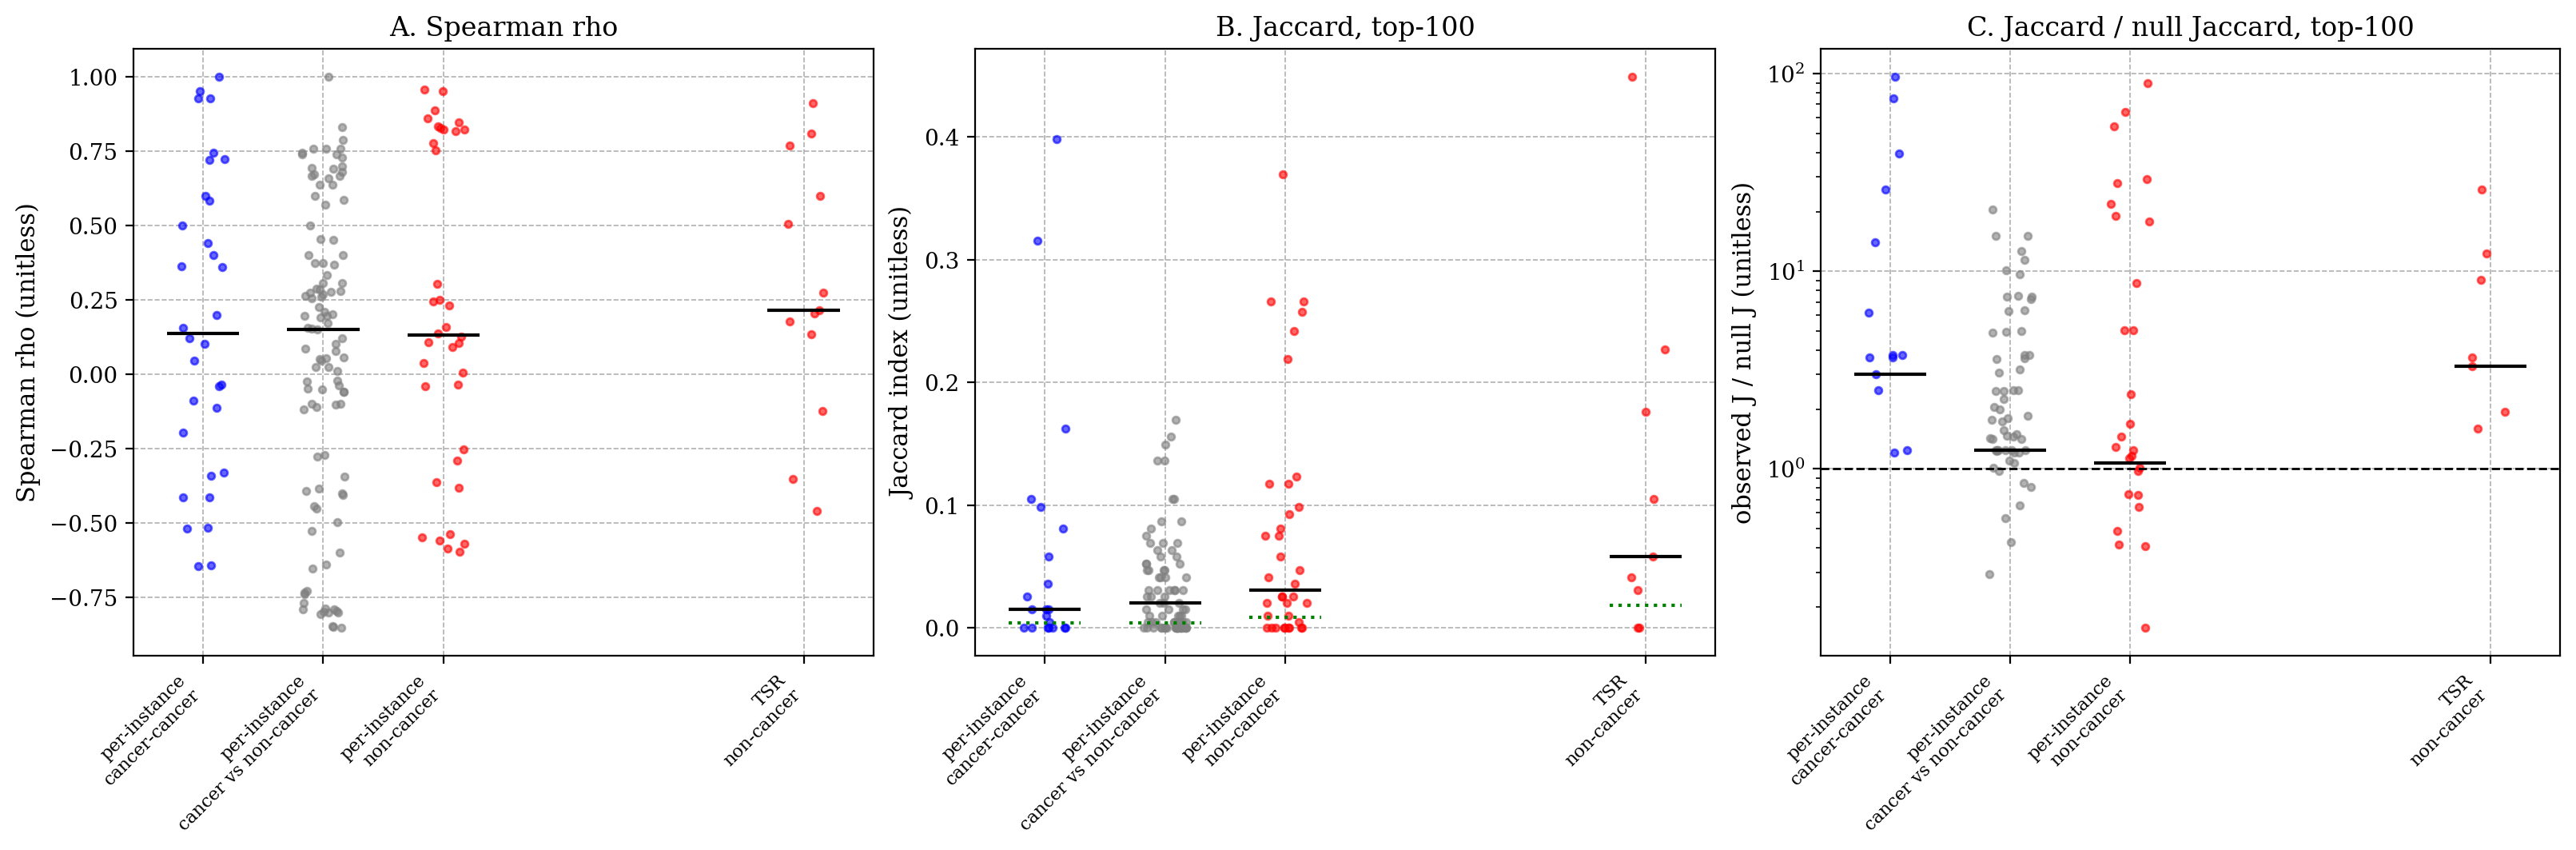

![Figure 5](../../../imgs/case_studies/cross_disease/cross_disease_pairs_by_class_pvalue_filtered_bh05.png)

**Figure 5.** Each point is one (model, disease pair); black bar = median; in B the green dotted bar is the median hypergeometric null Jaccard of the class, in C the dashed line marks observed = null. P-value-filtered rankings (BH <= 0.05). Colour = pair class.

In [12]:
cls_order = ['cancer-cancer', 'cancer vs non-cancer', 'non-cancer']
cls_col = {'cancer-cancer': '#0000FF', 'cancer vs non-cancer': '#808080', 'non-cancer': '#FF0000'}
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
rng = np.random.default_rng(SEED)
for ax, (df, col, ttl, yl) in zip(axs, [(S, 'spearman', 'A. Spearman rho', 'Spearman rho (unitless)'),
                                        (J[J['k_label'] == '100'], 'jaccard', 'B. Jaccard, top-100', 'Jaccard index (unitless)'),
                                        (J[J['k_label'] == '100'], 'ratio_to_null', 'C. Jaccard / null Jaccard, top-100', 'observed J / null J (unitless)')]):
    d = df[df['variant'] == 'all']
    xt, xl = [], []
    for i, (fam, c) in enumerate([(f, c) for f in ['per-instance', 'TSR'] for c in cls_order]):
        v = d[(d['family'] == fam) & (d['pair_class'] == c)]
        if v.empty: continue
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v[col], s=10, color=cls_col[c], alpha=0.6)
        ax.hlines(v[col].median(), i - 0.3, i + 0.3, color='k')
        xt.append(i); xl.append(f'{fam}\n{c}')
    if col == 'ratio_to_null': ax.axhline(1, color='k', ls='--', lw=1)
    if col == 'jaccard':
        nn = d.groupby(['family', 'pair_class'])['jaccard_null'].median()
        for i, (fam, c) in enumerate([(f, c) for f in ['per-instance', 'TSR'] for c in cls_order]):
            if (fam, c) in nn.index: ax.hlines(nn[(fam, c)], i - 0.3, i + 0.3, color='g', ls=':')
    if col == 'ratio_to_null': ax.set_yscale('log')
    ax.set_xticks(xt); ax.set_xticklabels(xl, rotation=45, ha='right', fontsize=8); ax.set_title(ttl); ax.set_ylabel(yl)
show_fig(fig, 'pairs_by_class', 'Each point is one (model, disease pair); black bar = median; in B the green dotted bar is the median hypergeometric null Jaccard of the class, in C the dashed line marks observed = null. P-value-filtered rankings (BH <= 0.05). Colour = pair class.')

In [13]:
# per model: Spearman per pair
order_cfg = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']
d = S[(S['variant'] == 'all') & (S['family'] == 'per-instance')]
t = d.groupby(['config', 'score_type', 'pair_class'])['spearman'].median().unstack('pair_class').reindex(columns=cls_order).reset_index()
tt = S[(S['variant'] == 'all') & (S['family'] == 'TSR')].groupby(['config', 'score_type', 'pair_class'])['spearman'].median().unstack('pair_class').reindex(columns=cls_order).reset_index()
t = pd.concat([t, tt], ignore_index=True)
t['o'] = t['config'].map({c: i for i, c in enumerate(order_cfg)}); t = t.sort_values(['score_type', 'o']).drop(columns='o')
show_table(t, 'Median Spearman rho (unitless) of the disease pairs of each pair class, per method (configuration and score type); p-value-filtered rankings (BH <= 0.05); empty = class not available for that method (TSR: three non-cancer diseases only).', fmt='{:.2f}')
save(t, 'spearman_by_method_and_class')

**Table 24.** Median Spearman rho (unitless) of the disease pairs of each pair class, per method (configuration and score type); p-value-filtered rankings (BH <= 0.05); empty = class not available for that method (TSR: three non-cancer diseases only).

| config | score_type | cancer-cancer | cancer vs non-cancer | non-cancer |
|---|---|---|---|---|
| DEG | TSR |  |  | 0.13 |
| DEG_LM | TSR |  |  | 0.18 |
| mith | TSR |  |  | 0.22 |
| mith_LM | TSR |  |  | 0.21 |
| mith_pw | TSR |  |  | 0.81 |
| DEG | best | -0.09 | 0.15 | 0.14 |
| mith | best | 0.12 | 0.45 | 0.09 |
| mith_LM | best | 0.28 | 0.27 | 0.04 |
| mith_pw | best | 0.10 | -0.04 | 0.85 |
| DEG | sRGES | -0.04 | 0.09 | 0.10 |
| mith | sRGES | -0.33 | 0.19 | -0.38 |
| mith_LM | sRGES | 0.68 | 0.31 | -0.03 |
| mith_pw | sRGES | -0.41 | -0.79 | 0.83 |
| DEG | wsRGES | 0.44 | 0.10 | 0.11 |
| mith | wsRGES | -0.34 | 0.20 | -0.36 |
| mith_LM | wsRGES | 0.15 | 0.23 | -0.04 |
| mith_pw | wsRGES | -0.41 | -0.79 | 0.82 |

## 3. Instance-count bias and corticosteroids

`best` (and, less strongly, `sRGES`) of a drug profiled in many instances is more extreme by construction, so the same highly profiled drugs can lead every
disease. The comparison is repeated on shared drugs with n_instances >= `MIN_INSTANCES` in both diseases (`ge3inst`) and without corticosteroids (`no_cortico`).

In [14]:
v = S[S['family'] == 'per-instance'].groupby(['variant', 'pair_class']).agg(n_comparisons=('spearman', 'size'), median_n_shared=('n_shared', 'median'), spearman_median=('spearman', 'median'),
                                                                          spearman_min=('spearman', 'min'), spearman_max=('spearman', 'max')).reset_index()
show_table(v, 'Per-instance models: Spearman rho (unitless) by drug subset (variant) and pair class; median number of shared drugs (count of compounds) and median / min / max rho over (model, pair) combinations.', fmt='{:.2f}')
v2 = J[(J['family'] == 'per-instance') & (J['k_label'] == '100')].groupby(['variant', 'pair_class']).agg(jaccard_median=('jaccard', 'median'), null_median=('jaccard_null', 'median'), ratio_median=('ratio_to_null', 'median')).reset_index()
show_table(v2, 'Per-instance models: Jaccard index of the top-100 sets (unitless) by drug subset and pair class: median observed, median hypergeometric null, median observed / null.', fmt='{:.3f}')
vb = S[(S['family'] == 'per-instance')].groupby(['score_type', 'variant'])['spearman'].median().unstack('variant')
show_table(vb.reset_index(), 'Per-instance models: median Spearman rho (unitless) over all disease pairs and configurations, per score type and drug subset.', fmt='{:.2f}')
v3 = S[S['family'] == 'TSR'].groupby(['variant', 'pair_class']).agg(n_comparisons=('spearman', 'size'), spearman_median=('spearman', 'median'), spearman_min=('spearman', 'min'), spearman_max=('spearman', 'max')).reset_index()
show_table(v3, 'TSR models: Spearman rho (unitless) with and without corticosteroids (n_instances is not defined for TSR).', fmt='{:.2f}')
save(v, 'summary_variants_spearman'); save(v2, 'summary_variants_jaccard_k100')

**Table 25.** Per-instance models: Spearman rho (unitless) by drug subset (variant) and pair class; median number of shared drugs (count of compounds) and median / min / max rho over (model, pair) combinations.

| variant | pair_class | n_comparisons | median_n_shared | spearman_median | spearman_min | spearman_max |
|---|---|---|---|---|---|---|
| all | cancer vs non-cancer | 105 | 11693 | 0.15 | -0.85 | 1 |
| all | cancer-cancer | 32 | 11938.50 | 0.14 | -0.64 | 1 |
| all | non-cancer | 36 | 7798.50 | 0.13 | -0.60 | 0.96 |
| ge3inst | cancer vs non-cancer | 93 | 4813 | 0.12 | -0.84 | 1 |
| ge3inst | cancer-cancer | 28 | 4966 | 0.08 | -0.90 | 0.92 |
| ge3inst | non-cancer | 36 | 2694 | 0.22 | -0.65 | 0.95 |
| ge3inst_no_cortico | cancer vs non-cancer | 93 | 4784 | 0.12 | -0.83 | 1 |
| ge3inst_no_cortico | cancer-cancer | 28 | 4937 | 0.08 | -0.90 | 0.92 |
| ge3inst_no_cortico | non-cancer | 36 | 2674.50 | 0.22 | -0.65 | 0.95 |
| no_cortico | cancer vs non-cancer | 105 | 11660 | 0.15 | -0.85 | 1 |
| no_cortico | cancer-cancer | 32 | 11905.50 | 0.14 | -0.64 | 1 |
| no_cortico | non-cancer | 36 | 7772 | 0.13 | -0.60 | 0.96 |

**Table 26.** Per-instance models: Jaccard index of the top-100 sets (unitless) by drug subset and pair class: median observed, median hypergeometric null, median observed / null.

| variant | pair_class | jaccard_median | null_median | ratio_median |
|---|---|---|---|---|
| all | cancer vs non-cancer | 0.020 | 0.004 | 1.239 |
| all | cancer-cancer | 0.015 | 0.004 | 3.004 |
| all | non-cancer | 0.031 | 0.009 | 1.073 |
| ge3inst | cancer vs non-cancer | 0.047 | 0.010 | 1.244 |
| ge3inst | cancer-cancer | 0.020 | 0.010 | 1.423 |
| ge3inst | non-cancer | 0.220 | 0.010 | 1.446 |
| ge3inst_no_cortico | cancer vs non-cancer | 0.047 | 0.010 | 1.266 |
| ge3inst_no_cortico | cancer-cancer | 0.020 | 0.010 | 1.468 |
| ge3inst_no_cortico | non-cancer | 0.220 | 0.010 | 1.446 |
| no_cortico | cancer vs non-cancer | 0.020 | 0.004 | 1.236 |
| no_cortico | cancer-cancer | 0.015 | 0.004 | 2.968 |
| no_cortico | non-cancer | 0.031 | 0.009 | 1.073 |

**Table 27.** Per-instance models: median Spearman rho (unitless) over all disease pairs and configurations, per score type and drug subset.

| score_type | all | ge3inst | ge3inst_no_cortico | no_cortico |
|---|---|---|---|---|
| best | 0.15 | 0.12 | 0.13 | 0.15 |
| sRGES | 0.10 | 0.15 | 0.15 | 0.11 |
| wsRGES | 0.13 | 0.12 | 0.12 | 0.12 |

**Table 28.** TSR models: Spearman rho (unitless) with and without corticosteroids (n_instances is not defined for TSR).

| variant | pair_class | n_comparisons | spearman_median | spearman_min | spearman_max |
|---|---|---|---|---|---|
| all | non-cancer | 13 | 0.22 | -0.46 | 0.91 |
| no_cortico | non-cancer | 13 | 0.22 | -0.46 | 0.91 |

## 4. Per-drug behaviour across diseases

For each family, every drug scored in all diseases of the family has a percentile in each disease (within the model). The mean and the SD of these percentiles
across diseases are computed per model; a drug with mean <= `MEAN_MAX` and SD <= `SD_MAX` is *flagged* in that model. A drug flagged in at least `FLAG_FRAC` of the models of its family is listed as a **flagged drug**: it is ranked among the strongest reversers in every disease under several methods. For independent uniform percentiles the expected mean is 50 and the expected SD about 28.9 percentile points;
the number of drugs flagged after permuting each disease's percentiles across drugs (`N_PERM` = 1000 permutations) gives a null count. This null tests only the independence of the diseases' rankings; it does not test a drug-specific property, because the observed rank correlations between diseases (section 2) already make low mean and low SD more frequent than under independence. Models are correlated, so the fraction of flagging models is descriptive.


In [15]:
def drug_stats(family):
    sub = R[R['family'] == family]
    full = [d for d in DISEASES if sub[sub['disease'] == d].shape[0] > 0]
    recs, perm = [], []
    rng = np.random.default_rng(SEED)
    for slc, g in sub.groupby('model', observed=True):
        P = g.pivot(index='drug_key', columns='disease', values='pct')
        ds = [d for d in full if d in P.columns]
        if len(ds) != len(full): continue
        P = P[ds].dropna()
        if len(P) < 20: continue
        N = g.pivot(index='drug_key', columns='disease', values='n_instances')[ds].reindex(P.index)
        r = pd.DataFrame({'model': slc, 'drug_key': P.index, 'mean_pct': P.mean(axis=1).values, 'sd_pct': P.std(axis=1, ddof=1).values,
                          'min_n_inst': N.min(axis=1).values})
        for d in ds: r['pct_' + d] = P[d].values
        recs.append(r)
        flagged = ((r['mean_pct'] <= MEAN_MAX) & (r['sd_pct'] <= SD_MAX)).sum()
        pc = []
        arr = P.values
        for _ in range(N_PERM):
            Q = np.column_stack([rng.permutation(arr[:, j]) for j in range(arr.shape[1])])
            pc.append(((Q.mean(axis=1) <= MEAN_MAX) & (Q.std(axis=1, ddof=1) <= SD_MAX)).sum())
        perm.append({'family': family, 'model': slc, 'n_drugs': len(P), 'flagged_observed': int(flagged),
                     'flagged_null_mean': float(np.mean(pc)), 'flagged_null_max': int(np.max(pc))})
    return (pd.concat(recs, ignore_index=True) if recs else pd.DataFrame(columns=['model', 'drug_key', 'mean_pct', 'sd_pct', 'min_n_inst'])), pd.DataFrame(perm), full

DS, PM, DF = {}, [], {}
for fam in ['per-instance', 'TSR']:
    DS[fam], pm, DF[fam] = drug_stats(fam); PM.append(pm)
PM = pd.concat(PM, ignore_index=True)
show_table(PM, f'Flagged drugs per model: drugs scored in all diseases of the family (count of compounds), drugs with mean percentile <= {MEAN_MAX:g} and SD <= {SD_MAX:g} (percentile points), and the same count after permuting each disease\'s percentiles across drugs (mean and maximum over {N_PERM} permutations).', fmt='{:.1f}')
save(PM, 'promiscuity_vs_permutation')

**Table 29.** Flagged drugs per model: drugs scored in all diseases of the family (count of compounds), drugs with mean percentile <= 10 and SD <= 10 (percentile points), and the same count after permuting each disease's percentiles across drugs (mean and maximum over 1000 permutations).

| family | model | n_drugs | flagged_observed | flagged_null_mean | flagged_null_max |
|---|---|---|---|---|---|
| per-instance | DEG_best | 29 | 1 | 0.4 | 4 |
| per-instance | DEG_sRGES | 29 | 0 | 0.0 | 0 |
| per-instance | mith_best | 12419 | 153 | 0.7 | 5 |
| per-instance | mith_pw_best | 11613 | 349 | 0.9 | 5 |
| per-instance | mith_pw_sRGES | 11613 | 0 | 0.6 | 4 |
| per-instance | mith_pw_wsRGES | 11335 | 0 | 0.6 | 4 |
| per-instance | mith_sRGES | 12419 | 0 | 0.7 | 5 |
| per-instance | mith_wsRGES | 12144 | 0 | 0.7 | 6 |
| TSR | DEG_TSR | 1371 | 6 | 6.2 | 15 |
| TSR | mith_TSR | 3213 | 14 | 12.7 | 26 |
| TSR | mith_pw_TSR | 2615 | 222 | 14.3 | 26 |

In [16]:
def agg_drug(family):
    d = DS[family]
    d = d.assign(flag=(d['mean_pct'] <= MEAN_MAX) & (d['sd_pct'] <= SD_MAX))
    pcols = [c for c in d.columns if c.startswith('pct_')]
    a = d.groupby('drug_key').agg(n_models=('model', 'size'), mean_pct=('mean_pct', 'median'), sd_pct=('sd_pct', 'median'),
                                  frac_models_flagged=('flag', 'mean'), min_n_inst=('min_n_inst', 'median'),
                                  **{c: (c, 'median') for c in pcols}).reset_index()
    a['family'] = family
    a['flagged'] = a['frac_models_flagged'] >= FLAG_FRAC
    a['rank_by_mean_pct'] = a['mean_pct'].rank(method='min')
    return a.sort_values(['frac_models_flagged', 'mean_pct'], ascending=[False, True])
AG = {f: agg_drug(f) for f in DS}
ALL = pd.concat(AG.values(), ignore_index=True)
save(ALL, 'drug_percentile_across_diseases')
for fam, a in AG.items():
    f = a[a['flagged']]
    ncol = [c for c in a.columns if c.startswith('pct_')]
    top = f.head(25)[['drug_key', 'n_models', 'mean_pct', 'sd_pct', 'frac_models_flagged', 'min_n_inst'] + ncol]
    show_table(top, f'{fam}: the {len(top)} flagged drugs with the highest fraction of flagging models (of {len(f)} drugs flagged in at least {FLAG_FRAC:.0%} of the models, {len(a)} drugs compared over {len(DF[fam])} diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).', fmt='{:.1f}')
    if fam == 'TSR':
        display(Markdown('For TSR the number of flagged drugs per model is at or below the permutation null (Table of flagged drugs per model), except where the table shows otherwise; the TSR list is shown for completeness and carries no further reading.'))
    if fam == 'per-instance':
        g3 = f[f['min_n_inst'] >= MIN_INSTANCES]
        display(Markdown(f'Of the {len(f)} per-instance flagged drugs, {len(g3)} have a median smallest n_instances >= {MIN_INSTANCES}.'))

**Table 30.** per-instance: the 25 flagged drugs with the highest fraction of flagging models (of 94 drugs flagged in at least 25% of the models, 12436 drugs compared over 6 diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).

| drug_key | n_models | mean_pct | sd_pct | frac_models_flagged | min_n_inst | pct_asthma | pct_IPF | pct_ALS | pct_BRCA | pct_LIHC | pct_COAD |
|---|---|---|---|---|---|---|---|---|---|---|---|
| vorinostat | 6 | 29.3 | 10.9 | 0.3 | 813 | 41.3 | 22.8 | 38.3 | 9.8 | 31.0 | 24.2 |
| idarubicin | 6 | 34.2 | 15.5 | 0.3 | 78.5 | 24.8 | 28.7 | 20.4 | 16.7 | 30.6 | 55.5 |
| bi2536 | 6 | 36.2 | 25.9 | 0.3 | 97 | 24.2 | 9.1 | 19.4 | 11.3 | 26.5 | 64.7 |
| teniposide | 6 | 37.7 | 18.3 | 0.3 | 82.5 | 20.6 | 26.6 | 20.4 | 22.8 | 32.5 | 62.4 |
| pyrviniumpamoate | 6 | 39.7 | 25.2 | 0.3 | 57.5 | 23.0 | 13.1 | 15.4 | 34.2 | 31.4 | 74.2 |
| gemcitabine | 6 | 39.8 | 8.7 | 0.3 | 76 | 35.0 | 38.4 | 30.1 | 27.4 | 34.6 | 50.5 |
| tubastatina | 6 | 40.7 | 8.8 | 0.3 | 33.5 | 48.8 | 47.3 | 47.2 | 28.6 | 31.5 | 30.9 |
| etoposide | 6 | 41.0 | 10.4 | 0.3 | 31 | 32.9 | 33.0 | 27.8 | 30.9 | 33.5 | 54.3 |
| ly294002 | 6 | 41.0 | 9.7 | 0.3 | 163.5 | 41.8 | 33.1 | 29.4 | 30.7 | 37.3 | 51.5 |
| sch58261 | 6 | 41.0 | 4.5 | 0.3 | 9.5 | 34.7 | 34.3 | 41.3 | 39.6 | 41.1 | 37.1 |
| saracatinib | 6 | 41.3 | 5.1 | 0.3 | 51 | 34.8 | 36.7 | 39.9 | 35.2 | 40.2 | 43.0 |
| chembl1222381 | 6 | 41.4 | 7.2 | 0.3 | 44 | 36.3 | 36.0 | 27.2 | 30.7 | 34.6 | 42.3 |
| tanespimycin | 6 | 41.7 | 8.7 | 0.3 | 123 | 32.5 | 44.9 | 30.9 | 36.8 | 47.1 | 33.5 |
| simvastatin | 6 | 42.2 | 4.5 | 0.3 | 31 | 45.0 | 42.2 | 42.1 | 43.1 | 41.0 | 39.4 |
| mg132 | 6 | 42.4 | 6.5 | 0.3 | 38 | 41.8 | 42.4 | 45.1 | 21.3 | 32.0 | 44.0 |
| rotenone | 6 | 42.4 | 17.7 | 0.3 | 38 | 32.0 | 26.3 | 18.9 | 28.2 | 37.0 | 67.9 |
| triamcinolone | 6 | 42.7 | 15.0 | 0.3 | 29 | 23.9 | 29.7 | 38.7 | 65.0 | 48.6 | 34.0 |
| nsc632839 | 6 | 42.8 | 24.6 | 0.3 | 88.5 | 24.3 | 18.3 | 26.2 | 28.2 | 28.5 | 68.9 |
| l690488 | 6 | 43.1 | 7.6 | 0.3 | 34.5 | 50.3 | 32.5 | 34.2 | 41.2 | 38.6 | 41.7 |
| brdk78062244 | 6 | 43.1 | 6.9 | 0.3 | 25 | 43.2 | 38.0 | 31.7 | 35.2 | 31.6 | 51.4 |
| withaferina | 6 | 43.7 | 8.6 | 0.3 | 134.5 | 37.3 | 34.6 | 27.3 | 38.2 | 32.3 | 51.9 |
| sa1456751 | 6 | 44.1 | 7.8 | 0.3 | 8 | 37.6 | 37.4 | 34.3 | 30.4 | 40.3 | 48.2 |
| wortmannin | 6 | 44.1 | 4.0 | 0.3 | 516 | 46.1 | 21.3 | 19.8 | 39.9 | 42.7 | 47.7 |
| curcumin | 6 | 44.2 | 6.1 | 0.3 | 102 | 39.4 | 46.9 | 36.2 | 41.8 | 45.3 | 36.7 |
| cd437 | 6 | 44.3 | 16.0 | 0.3 | 62 | 30.3 | 27.8 | 29.7 | 32.9 | 32.6 | 66.5 |

Of the 94 per-instance flagged drugs, 94 have a median smallest n_instances >= 3.

**Table 31.** TSR: the 25 flagged drugs with the highest fraction of flagging models (of 241 drugs flagged in at least 25% of the models, 3218 drugs compared over 3 diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).

| drug_key | n_models | mean_pct | sd_pct | frac_models_flagged | min_n_inst | pct_asthma | pct_IPF | pct_ALS |
|---|---|---|---|---|---|---|---|---|
| brdk07530279 | 1 | 7.7 | 5.5 | 1 |  | 12.0 | 9.6 | 1.5 |
| brdk69496360 | 3 | 9.1 | 8.6 | 0.7 |  | 3.9 | 5.7 | 18.9 |
| qlxii47 | 2 | 8.7 | 12.4 | 0.5 |  | 3.6 | 0.7 | 21.7 |
| vesamicol | 2 | 10.3 | 7.6 | 0.5 |  | 9.3 | 4.7 | 17.0 |
| oxfendazole | 2 | 11.5 | 11.3 | 0.5 |  | 9.8 | 19.7 | 5.0 |
| ym90709 | 2 | 11.6 | 9.5 | 0.5 |  | 17.7 | 14.6 | 2.4 |
| vicriviroc | 2 | 12.0 | 8.0 | 0.5 |  | 18.3 | 8.9 | 8.6 |
| brdk36287933 | 2 | 12.2 | 10.8 | 0.5 |  | 23.8 | 5.9 | 7.0 |
| thiorphan | 2 | 12.3 | 6.0 | 0.5 |  | 13.6 | 8.8 | 14.5 |
| oxetane | 2 | 12.5 | 12.2 | 0.5 |  | 12.1 | 4.3 | 21.0 |
| verrucarina | 2 | 12.6 | 17.9 | 0.5 |  | 1.1 | 3.4 | 33.2 |
| cgp12177 | 2 | 12.6 | 7.9 | 0.5 |  | 9.4 | 21.6 | 6.9 |
| qlx138 | 2 | 13.2 | 17.3 | 0.5 |  | 6.9 | 1.7 | 31.1 |
| brda09719808 | 2 | 13.4 | 17.7 | 0.5 |  | 30.2 | 6.0 | 4.0 |
| cymarin | 2 | 14.1 | 14.5 | 0.5 |  | 10.5 | 6.9 | 25.0 |
| brdk25774147 | 2 | 14.4 | 7.3 | 0.5 |  | 17.7 | 18.6 | 6.9 |
| htmt | 2 | 14.4 | 14.5 | 0.5 |  | 5.7 | 8.3 | 29.3 |
| brdk17628612 | 2 | 14.9 | 10.5 | 0.5 |  | 22.4 | 3.0 | 19.4 |
| fpl55712 | 2 | 15.2 | 9.1 | 0.5 |  | 19.3 | 12.4 | 14.0 |
| ouabain | 2 | 15.3 | 16.0 | 0.5 |  | 10.5 | 5.7 | 29.6 |
| bntx | 2 | 15.9 | 10.9 | 0.5 |  | 14.6 | 6.2 | 26.9 |
| cetirizine | 2 | 16.3 | 12.4 | 0.5 |  | 28.6 | 13.7 | 6.5 |
| ran14b | 2 | 16.7 | 10.6 | 0.5 |  | 15.4 | 8.0 | 26.7 |
| brdk58279162 | 2 | 17.1 | 7.2 | 0.5 |  | 16.5 | 13.6 | 21.1 |
| hexamethyleneamiloride | 2 | 17.2 | 19.3 | 0.5 |  | 34.3 | 8.3 | 9.0 |

For TSR the number of flagged drugs per model is at or below the permutation null (Table of flagged drugs per model), except where the table shows otherwise; the TSR list is shown for completeness and carries no further reading.

In [17]:
FAM = {'protein-synthesis inhibitors': ['homoharringtonine', 'cephaeline', 'emetine'],
       'cardiac glycosides': ['bufalin', 'proscillaridin', 'digoxin', 'strophanthidin', 'cymarin']}
rows = []
for fam, a in AG.items():
    a = a.set_index('drug_key'); pc = [c for c in a.columns if c.startswith('pct_')]
    for cls, names in FAM.items():
        for nm in names:
            k = key([nm])[0]
            if k in a.index:
                r = a.loc[k]
                rows.append({'family': fam, 'class': cls, 'drug': nm, 'n_models': int(r['n_models']), 'mean_pct': r['mean_pct'], 'sd_pct': r['sd_pct'],
                             'rank_of_mean_pct': int(r['rank_by_mean_pct']), 'n_drugs': len(a), 'frac_models_flagged': r['frac_models_flagged'],
                             'flagged': bool(r['flagged']), **{c: r[c] for c in pc}})
            else:
                rows.append({'family': fam, 'class': cls, 'drug': nm, 'n_models': 0})
FD = pd.DataFrame(rows)
save(FD, 'drug_classes_check')
show_table(FD.round(2), 'Protein-synthesis inhibitors and cardiac glycosides across diseases: median over models of the mean and SD of percentile across diseases (percentile points), rank of the mean percentile among the n_drugs compared (1 = lowest), fraction of models where the drug is flagged, and median percentile per disease (0-100). n_models = 0: drug not scored in every disease of the family.', fmt='{:.1f}')

**Table 32.** Protein-synthesis inhibitors and cardiac glycosides across diseases: median over models of the mean and SD of percentile across diseases (percentile points), rank of the mean percentile among the n_drugs compared (1 = lowest), fraction of models where the drug is flagged, and median percentile per disease (0-100). n_models = 0: drug not scored in every disease of the family.

| family | class | drug | n_models | mean_pct | sd_pct | rank_of_mean_pct | n_drugs | frac_models_flagged | flagged | pct_asthma | pct_IPF | pct_ALS | pct_BRCA | pct_LIHC | pct_COAD |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| per-instance | protein-synthesis inhibitors | homoharringtonine | 6 | 39.6 | 19 | 2167 | 12436 | 0.0 | False | 30.4 | 8.8 | 19.5 | 41.5 | 38.8 | 83.3 |
| per-instance | protein-synthesis inhibitors | cephaeline | 6 | 43.2 | 18.8 | 3488 | 12436 | 0.0 | False | 32.2 | 16.3 | 27.8 | 45.3 | 50.6 | 73.2 |
| per-instance | protein-synthesis inhibitors | emetine | 6 | 44.5 | 12.5 | 3999 | 12436 | 0.0 | False | 23.2 | 11.7 | 32.4 | 55.8 | 52.6 | 72.4 |
| per-instance | cardiac glycosides | bufalin | 6 | 38.4 | 34.2 | 1746 | 12436 | 0.0 | False | 33.7 | 8.5 | 15.1 | 36.2 | 51.7 | 89 |
| per-instance | cardiac glycosides | proscillaridin | 6 | 41.1 | 28.4 | 2723 | 12436 | 0.0 | False | 30.7 | 12.4 | 23.1 | 41.4 | 32.3 | 85.8 |
| per-instance | cardiac glycosides | digoxin | 6 | 40.4 | 30.0 | 2468 | 12436 | 0.0 | False | 30.3 | 10.9 | 18.1 | 33.8 | 33.4 | 88.5 |
| per-instance | cardiac glycosides | strophanthidin | 6 | 39.7 | 25.9 | 2197 | 12436 | 0.0 | False | 31.4 | 12.1 | 18.6 | 34.1 | 33.9 | 83.2 |
| per-instance | cardiac glycosides | cymarin | 6 | 40.4 | 30.5 | 2452 | 12436 | 0.0 | False | 32.4 | 16.2 | 17.7 | 34.1 | 52.1 | 88.5 |
| TSR | protein-synthesis inhibitors | homoharringtonine | 3 | 26.6 | 45.9 | 316 | 3218 | 0.3 | True | 0.1 | 0.1 | 79.6 |  |  |  |
| TSR | protein-synthesis inhibitors | cephaeline | 3 | 23.7 | 40.6 | 214 | 3218 | 0.3 | True | 0.4 | 0.5 | 70.6 |  |  |  |
| TSR | protein-synthesis inhibitors | emetine | 3 | 24.8 | 42.2 | 254 | 3218 | 0.3 | True | 0.4 | 0.6 | 73.6 |  |  |  |
| TSR | cardiac glycosides | bufalin | 3 | 17.1 | 24.4 | 60 | 3218 | 0.0 | False | 7.2 | 4.7 | 45.1 |  |  |  |
| TSR | cardiac glycosides | proscillaridin | 3 | 26.1 | 34.0 | 300 | 3218 | 0.0 | False | 13.4 | 3.6 | 64.5 |  |  |  |
| TSR | cardiac glycosides | digoxin | 3 | 28.6 | 35.5 | 411 | 3218 | 0.0 | False | 16.7 | 11.1 | 68.5 |  |  |  |
| TSR | cardiac glycosides | strophanthidin | 3 | 25.2 | 34.9 | 272 | 3218 | 0.3 | True | 9.9 | 6.4 | 65.1 |  |  |  |
| TSR | cardiac glycosides | cymarin | 2 | 14.1 | 14.5 | 30 | 3218 | 0.5 | True | 10.5 | 6.9 | 25.0 |  |  |  |

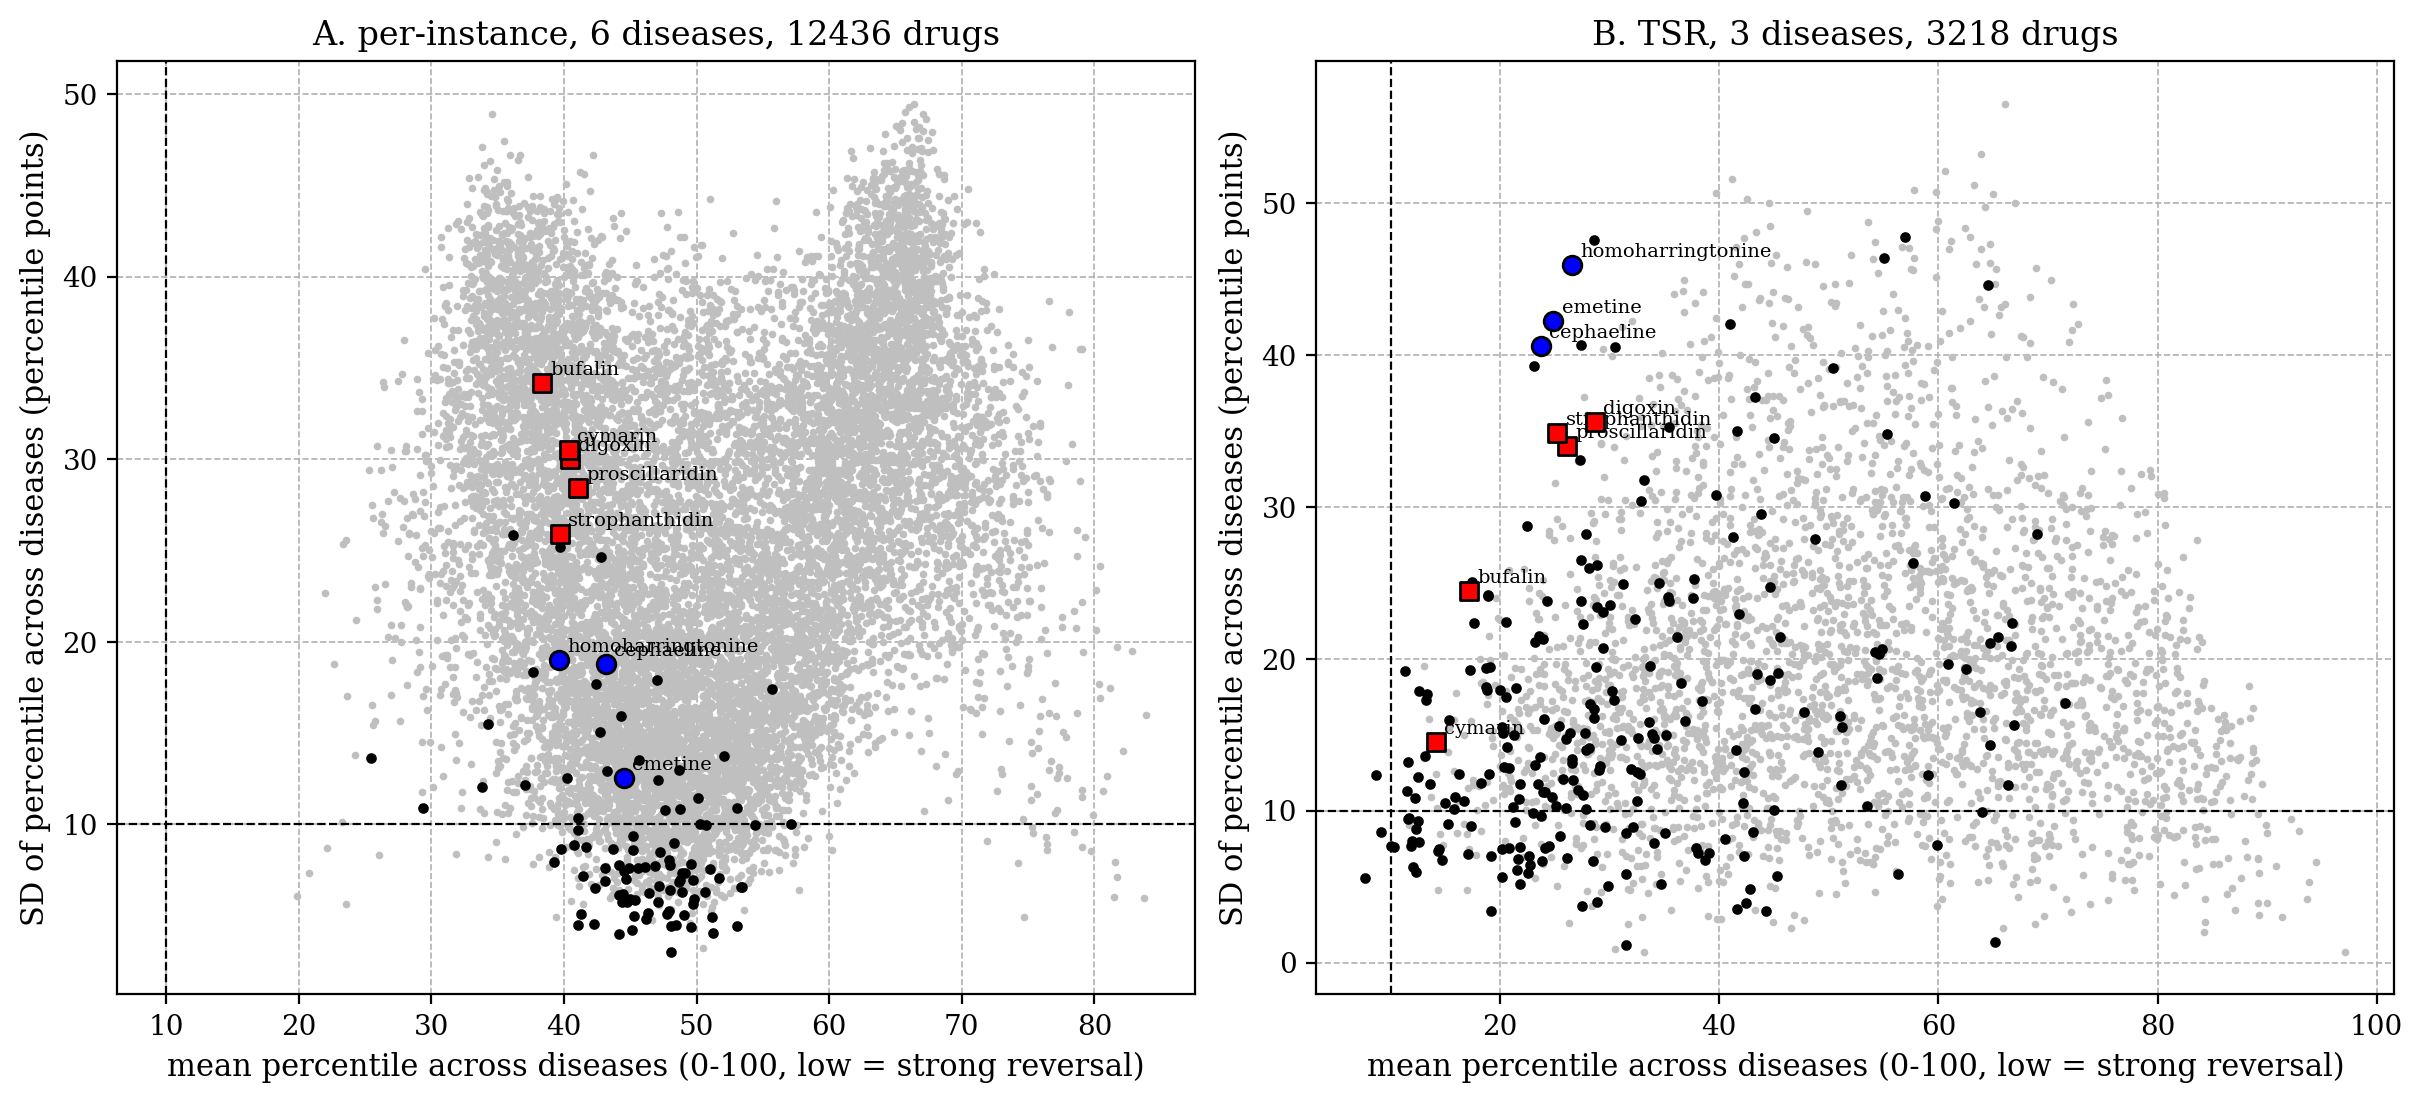

![Figure 6](../../../imgs/case_studies/cross_disease/cross_disease_drug_percentile_mean_sd_pvalue_filtered_bh05.png)

**Figure 6.** Each point is a drug: median over models of the mean (x) and SD (y) of its percentile across diseases. Black = flagged drug (mean and SD below the dashed thresholds); blue circles = protein-synthesis inhibitors, red squares = cardiac glycosides.

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)
hl = {k: ('#0000FF', 'o') for k in key(FAM['protein-synthesis inhibitors'])}
hl.update({k: ('#FF0000', 's') for k in key(FAM['cardiac glycosides'])})
for ax, fam in zip(axs, ['per-instance', 'TSR']):
    a = AG[fam]
    ax.scatter(a['mean_pct'], a['sd_pct'], s=3, color='0.75', rasterized=True)
    f = a[a['flagged']]
    ax.scatter(f['mean_pct'], f['sd_pct'], s=8, color='k')
    for k, (c, m) in hl.items():
        r = a[a['drug_key'] == k]
        if len(r):
            ax.scatter(r['mean_pct'], r['sd_pct'], s=45, color=c, marker=m, edgecolor='k', zorder=5)
            ax.annotate(k, (r['mean_pct'].iloc[0], r['sd_pct'].iloc[0]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axvline(MEAN_MAX, color='k', ls='--', lw=0.8); ax.axhline(SD_MAX, color='k', ls='--', lw=0.8)
    ax.set_xlabel('mean percentile across diseases (0-100, low = strong reversal)'); ax.set_ylabel('SD of percentile across diseases (percentile points)')
    ax.set_title(f'{"AB"[["per-instance", "TSR"].index(fam)]}. {fam}, {len(DF[fam])} diseases, {len(a)} drugs')
show_fig(fig, 'drug_percentile_mean_sd', 'Each point is a drug: median over models of the mean (x) and SD (y) of its percentile across diseases. Black = flagged drug (mean and SD below the dashed thresholds); blue circles = protein-synthesis inhibitors, red squares = cardiac glycosides.')

## 5. Significant sets, and comparison with the unfiltered rankings

**Significant sets.** For each model and each pair of diseases, the set of a disease is the set of all drugs kept by the filter that have a CS < 0 (predicted reversal), with no top-k cut. Both sets are restricted to the drugs scored in the unfiltered rankings of both diseases (the shared universe U, N = abs(U)).
The Jaccard index J of the two sets (sizes a and b, overlap x, J = x / (a + b - x)) is compared with three nulls:
- **stratified null (primary)**: drugs are grouped into strata of n_instances (the smaller of the two diseases' unfiltered n_instances: 1, 2, 3-5, 6-10, > 10); within each stratum the two sets are drawn independently at random with their observed stratum counts (equivalent to permuting set membership within strata); the overlap in a stratum is hypergeometric, 1000 draws (seed 0), null = mean J of the draws, p = fraction of draws with J >= observed. The filter keeps drugs with many instances in both diseases, so a null that ignores n_instances overstates the expected difference from chance. Not available for TSR (no n_instances);
- **all-shared null**: hypergeometric(N, a, b), assuming that all N drugs are exchangeable;
- **kept-in-both null**: hypergeometric on the drugs kept (any sign of CS) in both diseases, sets restricted to them; this universe is itself selected by the filter, so it gives a lower bound on J / null.

In [19]:
def load_rankings(rn):
    parts = []
    for dis, slug in CASES.items():
        p = conf.OOUT_DIR / 'case_studies' / slug / f'{slug}_{rn}.tsv'
        if p.exists(): d = pd.read_csv(p, sep='\t', usecols=USE, low_memory=False)
        elif rn == 'drug_rankings': d = build_case(slug)
        else: continue
        parts.append(d.assign(disease=dis))
    if rn == 'drug_rankings' and TCGA_TABLE_UNF is not None and Path(TCGA_TABLE_UNF).exists():
        parts.append(tcga_rankings(TCGA_TABLE_UNF))
    X = pd.concat(parts, ignore_index=True)
    X = X[X['collapse'].isin(COLL)].copy()
    X['score_type'] = X['collapse'].map(COLL)
    X['family'] = np.where(X['score_type'] == 'TSR', 'TSR', 'per-instance')
    X = X.rename(columns={'ranking': 'model'})
    X['pct'] = X.groupby(['disease', 'model'])['score'].rank(pct=True) * 100
    return X

def compute_pairs(X, min_n=None, only_keys=None):
    # only_keys: dict (model, a, b) -> set of drug_keys to restrict to (used for the unfiltered rho on the kept drugs)
    min_n = MIN_SHARED if min_n is None else min_n
    rows = []
    for (family, slc), g in X.groupby(['family', 'model']):
        sc = g.pivot(index='drug_key', columns='disease', values='score')
        ds = [d for d in DISEASES if d in sc.columns and sc[d].notna().any()]
        for a, b in combinations(ds, 2):
            m = sc[a].notna() & sc[b].notna()
            if only_keys is not None:
                ks = only_keys.get((slc, a, b))
                if ks is None: continue
                m &= sc.index.isin(ks)
            n = int(m.sum())
            if n < min_n: continue
            x, y = sc.loc[m, a], sc.loc[m, b]
            rx, ry = x.rank(method='first'), y.rank(method='first')
            rec = dict(family=family, model=slc, disease_a=a, disease_b=b, n_shared=n, spearman=spearmanr(x, y).statistic)
            for lab, k in [('5pct', max(2, int(round(TOP_FRAC * n)))), ('100', 100)]:
                if k >= n: continue
                ov = len(set(rx.index[rx <= k]) & set(ry.index[ry <= k]))
                rec['J' + lab] = ov / (2 * k - ov); rec['ratio' + lab] = rec['J' + lab] / jaccard_null(n, k)
            rows.append(rec)
    return pd.DataFrame(rows)

RU = load_rankings('drug_rankings')
RU = RU[RU['disease'].isin(dis_present)]
PU, PF = compute_pairs(RU), compute_pairs(R)
low = PF[PF['n_shared'] < N_MARK][['family', 'model', 'disease_a', 'disease_b', 'n_shared', 'spearman']]
if len(low): show_table(low, f'Cells with fewer than {N_MARK} shared drugs (count of compounds) after the filter: included in every median, Fisher-z mean and bootstrap of this report; listed because their rho and J rest on few drugs (hatched in the grid figures).', fmt='{:.2f}')
exp = set(RU.groupby(['model', 'disease']).size().index)
got = set(R.groupby(['model', 'disease'], observed=True).size().index)
empty = pd.DataFrame(sorted(exp - got), columns=['model', 'disease'])
if len(empty): show_table(empty, 'Models that exist in the unfiltered rankings and have no drug left after the filter, per disease (empty rankings).')
else: display(Markdown('No model of the unfiltered rankings is empty after the filter.'))
un = RU.groupby(['family', 'model', 'disease']).size().rename('n_unfiltered').reset_index()
fi = R.groupby(['family', 'model', 'disease'], observed=True).size().rename('n_filtered').reset_index()
sh = un.merge(fi, on=['family', 'model', 'disease'], how='left').fillna({'n_filtered': 0})
sh['kept'] = sh['n_filtered'] / sh['n_unfiltered']
shp = sh.pivot_table(index=['family', 'model'], columns='disease', values=['n_unfiltered', 'n_filtered']).reset_index()
shp.columns = [' '.join(c).strip() for c in shp.columns.to_flat_index()]
save(sh, 'universe_shrinkage')
show_table(shp, 'Number of drugs per model and disease before (n_unfiltered) and after (n_filtered) the filter (count of compounds); 0 = empty ranking.', fmt='{:.0f}')
kept_cfg = sh.assign(config=sh['model'].str.replace(r'_(sRGES|wsRGES|best|TSR)$', '', regex=True)).groupby(['family', 'config'])['kept'].median().reset_index()
kept_cfg['filter_acts'] = kept_cfg['kept'] < 0.9
show_table(kept_cfg, 'Median fraction of the unfiltered universe kept by the filter, per family and configuration (over models and diseases; unitless); filter_acts = median fraction < 0.9. The configurations with filter_acts = False are essentially unfiltered and dominate the all-model averages without being filtered.', fmt='{:.2f}')
ACT = set(kept_cfg.loc[kept_cfg['filter_acts'], 'config'])

**Table 33.** Cells with fewer than 100 shared drugs (count of compounds) after the filter: included in every median, Fisher-z mean and bootstrap of this report; listed because their rho and J rest on few drugs (hatched in the grid figures).

| family | model | disease_a | disease_b | n_shared | spearman |
|---|---|---|---|---|---|
| TSR | DEG_LM_TSR | IPF | ALS | 34 | 0.18 |
| TSR | mith_LM_TSR | asthma | IPF | 10 | 0.27 |
| TSR | mith_LM_TSR | asthma | ALS | 64 | -0.12 |
| TSR | mith_LM_TSR | IPF | ALS | 99 | 0.21 |
| per-instance | DEG_best | asthma | COAD | 31 | -0.27 |
| per-instance | DEG_best | IPF | COAD | 30 | -0.10 |
| per-instance | DEG_best | ALS | COAD | 33 | 0.05 |
| per-instance | DEG_best | BRCA | COAD | 32 | -0.09 |
| per-instance | DEG_best | LIHC | COAD | 33 | -0.20 |
| per-instance | DEG_sRGES | asthma | COAD | 31 | -0.11 |
| per-instance | DEG_sRGES | IPF | COAD | 30 | 0.25 |
| per-instance | DEG_sRGES | ALS | COAD | 33 | 0.01 |
| per-instance | DEG_sRGES | BRCA | COAD | 32 | -0.11 |
| per-instance | DEG_sRGES | LIHC | COAD | 33 | -0.04 |
| per-instance | DEG_wsRGES | asthma | COAD | 4 | -0.60 |
| per-instance | DEG_wsRGES | IPF | COAD | 4 | 0.40 |
| per-instance | DEG_wsRGES | ALS | COAD | 5 | -0.10 |
| per-instance | DEG_wsRGES | BRCA | COAD | 4 | 0.40 |
| per-instance | DEG_wsRGES | LIHC | COAD | 5 | 0.60 |
| per-instance | mith_LM_best | asthma | LIHC | 52 | -0.38 |
| per-instance | mith_LM_best | asthma | COAD | 3 | 0.50 |
| per-instance | mith_LM_best | IPF | LIHC | 70 | 0.33 |
| per-instance | mith_LM_best | IPF | COAD | 4 | 0.60 |
| per-instance | mith_LM_best | ALS | LIHC | 99 | 0.27 |
| per-instance | mith_LM_best | ALS | COAD | 4 | -0.40 |
| per-instance | mith_LM_best | BRCA | LIHC | 85 | 0.36 |
| per-instance | mith_LM_best | BRCA | COAD | 4 | 0.20 |
| per-instance | mith_LM_sRGES | asthma | LIHC | 52 | -0.39 |
| per-instance | mith_LM_sRGES | asthma | COAD | 3 | 1 |
| per-instance | mith_LM_sRGES | IPF | LIHC | 70 | 0.45 |
| per-instance | mith_LM_sRGES | IPF | COAD | 4 | 0.40 |
| per-instance | mith_LM_sRGES | ALS | LIHC | 99 | 0.29 |
| per-instance | mith_LM_sRGES | ALS | COAD | 4 | -0.80 |
| per-instance | mith_LM_sRGES | BRCA | LIHC | 85 | 0.36 |
| per-instance | mith_LM_sRGES | BRCA | COAD | 4 | 1 |
| per-instance | mith_LM_wsRGES | asthma | LIHC | 52 | -0.41 |
| per-instance | mith_LM_wsRGES | IPF | LIHC | 68 | 0.37 |
| per-instance | mith_LM_wsRGES | ALS | LIHC | 98 | 0.21 |
| per-instance | mith_LM_wsRGES | BRCA | LIHC | 84 | 0.15 |

**Table 34.** Models that exist in the unfiltered rankings and have no drug left after the filter, per disease (empty rankings).

| model | disease |
|---|---|
| DEG_LM_TSR | asthma |
| mith_LM_wsRGES | COAD |

**Table 35.** Number of drugs per model and disease before (n_unfiltered) and after (n_filtered) the filter (count of compounds); 0 = empty ranking.

| family | model | n_filtered ALS | n_filtered BRCA | n_filtered COAD | n_filtered IPF | n_filtered LIHC | n_filtered asthma | n_unfiltered ALS | n_unfiltered BRCA | n_unfiltered COAD | n_unfiltered IPF | n_unfiltered LIHC | n_unfiltered asthma |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| TSR | DEG_LM_TSR | 601 |  |  | 203 |  | 0 | 3221 |  |  | 3221 |  | 3221 |
| TSR | DEG_TSR | 2762 |  |  | 2318 |  | 2195 | 3221 |  |  | 3221 |  | 3221 |
| TSR | mith_LM_TSR | 862 |  |  | 220 |  | 131 | 3221 |  |  | 3221 |  | 3221 |
| TSR | mith_TSR | 3219 |  |  | 3221 |  | 3215 | 3221 |  |  | 3221 |  | 3221 |
| TSR | mith_pw_TSR | 2980 |  |  | 2823 |  | 3163 | 3221 |  |  | 3221 |  | 3221 |
| per-instance | DEG_best | 6893 | 2466 | 33 | 1529 | 3825 | 4879 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | DEG_sRGES | 6893 | 2466 | 33 | 1529 | 3825 | 4879 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | DEG_wsRGES | 6731 | 2256 | 5 | 1456 | 3707 | 4763 | 12419 | 12166 | 12166 | 12419 | 12166 | 12419 |
| per-instance | mith_LM_best | 5464 | 1440 | 4 | 1065 | 100 | 1126 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_LM_sRGES | 5464 | 1440 | 4 | 1065 | 100 | 1126 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_LM_wsRGES | 5255 | 1414 | 0 | 1004 | 99 | 1115 | 12419 | 12166 | 12166 | 12419 | 12166 | 12419 |
| per-instance | mith_best | 12434 | 12436 | 12440 | 12440 | 12440 | 12429 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_pw_best | 12221 | 12288 | 12306 | 12065 | 12345 | 12350 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_pw_sRGES | 12221 | 12288 | 12306 | 12065 | 12345 | 12350 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_pw_wsRGES | 12198 | 12009 | 12032 | 12034 | 12068 | 12329 | 12419 | 12166 | 12166 | 12419 | 12166 | 12419 |
| per-instance | mith_sRGES | 12434 | 12436 | 12440 | 12440 | 12440 | 12429 | 12440 | 12440 | 12440 | 12440 | 12440 | 12440 |
| per-instance | mith_wsRGES | 12413 | 12162 | 12166 | 12419 | 12166 | 12407 | 12419 | 12166 | 12166 | 12419 | 12166 | 12419 |

**Table 36.** Median fraction of the unfiltered universe kept by the filter, per family and configuration (over models and diseases; unitless); filter_acts = median fraction < 0.9. The configurations with filter_acts = False are essentially unfiltered and dominate the all-model averages without being filtered.

| family | config | kept | filter_acts |
|---|---|---|---|
| TSR | DEG | 0.72 | True |
| TSR | DEG_LM | 0.06 | True |
| TSR | mith | 1.00 | False |
| TSR | mith_LM | 0.07 | True |
| TSR | mith_pw | 0.93 | False |
| per-instance | DEG | 0.25 | True |
| per-instance | mith | 1.00 | False |
| per-instance | mith_LM | 0.09 | True |
| per-instance | mith_pw | 0.99 | False |

In [20]:
STRATA = [0, 1, 2, 5, 10, np.inf]; STRATA_LAB = ['1', '2', '3-5', '6-10', '>10']
rng_s = np.random.default_rng(SEED)
def sig_jaccard(Xf, Xu, n_draw=1000):
    rows = []
    for (family, slc), gu in Xu.groupby(['family', 'model']):
        gf = Xf[Xf['model'] == slc]
        ds = [d for d in DISEASES if d in set(gu['disease'])]
        ni = gu.pivot(index='drug_key', columns='disease', values='n_instances')
        for a, b in combinations(ds, 2):
            U = set(gu.loc[gu['disease'] == a, 'drug_key']) & set(gu.loc[gu['disease'] == b, 'drug_key'])
            ka, kb = set(gf.loc[gf['disease'] == a, 'drug_key']) & U, set(gf.loc[gf['disease'] == b, 'drug_key']) & U
            sa = set(gf.loc[(gf['disease'] == a) & (gf['score'] < 0), 'drug_key']) & U
            sb = set(gf.loc[(gf['disease'] == b) & (gf['score'] < 0), 'drug_key']) & U
            N, na, nb = len(U), len(sa), len(sb); x = len(sa & sb)
            rec = dict(family=family, model=slc, disease_a=a, disease_b=b, N=N, size_set_1=na, size_set_2=nb, overlap=x)
            if na and nb:
                rec['jaccard'] = x / (na + nb - x)
                xs = np.arange(max(0, na + nb - N), min(na, nb) + 1); pm = hypergeom.pmf(xs, N, na, nb)
                rec['null_all'] = float((pm * xs / (na + nb - xs)).sum()); rec['p_all'] = float(hypergeom.sf(x - 1, N, na, nb))
                Uk = ka & kb; Nk = len(Uk); ska, skb = sa & Uk, sb & Uk; na2, nb2 = len(ska), len(skb); x2 = len(ska & skb)
                if na2 and nb2 and Nk > 0:
                    xs = np.arange(max(0, na2 + nb2 - Nk), min(na2, nb2) + 1); pm = hypergeom.pmf(xs, Nk, na2, nb2)
                    rec['N_kept_both'] = Nk; rec['jaccard_kept_both'] = x2 / (na2 + nb2 - x2)
                    rec['null_kept_both'] = float((pm * xs / (na2 + nb2 - xs)).sum())
                if family == 'per-instance':
                    nmin = ni.loc[sorted(U), [a, b]].min(axis=1)
                    st = pd.cut(nmin, STRATA, labels=STRATA_LAB).astype(str)
                    xd = np.zeros(n_draw); nad = 0; nbd = 0
                    for s_, idx in pd.Series(st.values, index=nmin.index).groupby(st.values):
                        ks = set(idx.index); n_s = len(ks); a_s = len(sa & ks); b_s = len(sb & ks)
                        nad += a_s; nbd += b_s
                        xd += rng_s.hypergeometric(a_s, n_s - a_s, b_s, size=n_draw)
                    Jd = xd / (nad + nbd - xd)
                    rec['null_strat'] = float(Jd.mean()); rec['p_strat'] = float((Jd >= rec['jaccard'] - 1e-12).mean())
                    rec['ratio_strat'] = rec['jaccard'] / rec['null_strat']
                rec['ratio_all'] = rec['jaccard'] / rec['null_all']
                if 'null_kept_both' in rec: rec['ratio_kept_both'] = rec['jaccard_kept_both'] / rec['null_kept_both']
            rows.append(rec)
    return pd.DataFrame(rows)

SJ = sig_jaccard(R, RU)
SJ = SJ[(SJ['N'] >= 0)]
save(SJ, 'significant_set_jaccard')
sj = SJ.dropna(subset=['jaccard'])
aggs = dict(n_models=('jaccard', 'size'), size_set_1_median=('size_set_1', 'median'), size_set_2_median=('size_set_2', 'median'), N_median=('N', 'median'), jaccard_median=('jaccard', 'median'),
            ratio_strat_median=('ratio_strat', 'median'), frac_p_strat_lt_0_05=('p_strat', lambda s: (s < 0.05).mean() if s.notna().any() else np.nan),
            ratio_all_median=('ratio_all', 'median'), ratio_kept_both_median=('ratio_kept_both', 'median'))
t = sj.groupby(['family', 'disease_a', 'disease_b']).agg(**aggs).reset_index()
show_table(t, 'Jaccard index J of the significant sets (all kept drugs with CS < 0) per family and disease pair, over the models where both sets are non-empty: number of models, median size of the set of the first and of the second disease of the pair and universe size N (count of compounds), median J, and median J / null under the stratified null (primary; fraction of models with p < 0.05), the all-shared null and the kept-in-both null (unitless; 1 = chance; stratified null empty for TSR). Filter: BH <= 0.05.', fmt='{:.3f}')
ps = sj[sj['family'] == 'per-instance'].groupby(['model']).agg(J_median=('jaccard', 'median'), ratio_strat_median=('ratio_strat', 'median'), ratio_all_median=('ratio_all', 'median'),
                                                               ratio_kept_both_median=('ratio_kept_both', 'median'), size_set_1_median=('size_set_1', 'median')).reset_index()
show_table(ps, 'Per-instance models: median over the disease pairs of the significant-set Jaccard index J and of J / null (stratified, all-shared, kept-in-both; unitless) and of the size of the set of the first disease of each pair (count of compounds). Filter: BH <= 0.05.', fmt='{:.3f}')

**Table 37.** Jaccard index J of the significant sets (all kept drugs with CS < 0) per family and disease pair, over the models where both sets are non-empty: number of models, median size of the set of the first and of the second disease of the pair and universe size N (count of compounds), median J, and median J / null under the stratified null (primary; fraction of models with p < 0.05), the all-shared null and the kept-in-both null (unitless; 1 = chance; stratified null empty for TSR). Filter: BH <= 0.05.

| family | disease_a | disease_b | n_models | size_set_1_median | size_set_2_median | N_median | jaccard_median | ratio_strat_median | frac_p_strat_lt_0_05 | ratio_all_median | ratio_kept_both_median |
|---|---|---|---|---|---|---|---|---|---|---|---|
| TSR | IPF | ALS | 5 | 1219 | 2051 | 3221 | 0.469 |  |  | 1.234 | 1.055 |
| TSR | asthma | ALS | 4 | 1076.500 | 2098 | 3221 | 0.213 |  |  | 0.738 | 0.768 |
| TSR | asthma | IPF | 4 | 1076.500 | 1539.500 | 3221 | 0.370 |  |  | 1.661 | 1.254 |
| per-instance | ALS | BRCA | 12 | 5881 | 4953 | 12440 | 0.468 | 1.276 | 0.750 | 1.664 | 1.299 |
| per-instance | ALS | COAD | 11 | 7265 | 5775 | 12440 | 0.134 | 0.801 | 0.091 | 0.953 | 0.857 |
| per-instance | ALS | LIHC | 12 | 5881 | 4567 | 12440 | 0.255 | 1.133 | 0.667 | 1.721 | 1.091 |
| per-instance | BRCA | COAD | 11 | 7806 | 5775 | 12440 | 0.233 | 0.894 | 0.182 | 0.983 | 0.983 |
| per-instance | BRCA | LIHC | 12 | 4953 | 4567 | 12440 | 0.490 | 1.663 | 0.750 | 3.222 | 1.207 |
| per-instance | IPF | ALS | 12 | 4072.500 | 5958 | 12440 | 0.456 | 1.337 | 0.917 | 1.898 | 1.323 |
| per-instance | IPF | BRCA | 12 | 4006 | 4953 | 12440 | 0.512 | 1.548 | 1 | 3.290 | 1.231 |
| per-instance | IPF | COAD | 11 | 6694 | 5775 | 12440 | 0.107 | 0.828 | 0.364 | 0.921 | 0.921 |
| per-instance | IPF | LIHC | 12 | 4006 | 4567 | 12440 | 0.311 | 1.464 | 0.750 | 3.037 | 1.213 |
| per-instance | LIHC | COAD | 11 | 6448 | 5775 | 12440 | 0.190 | 1.362 | 0.636 | 2.399 | 1.058 |
| per-instance | asthma | ALS | 12 | 3680 | 5958 | 12440 | 0.122 | 0.696 | 0.250 | 0.999 | 0.571 |
| per-instance | asthma | BRCA | 12 | 3647 | 4953 | 12440 | 0.185 | 0.941 | 0.417 | 1.669 | 0.952 |
| per-instance | asthma | COAD | 11 | 4383 | 5775 | 12440 | 0.127 | 1.092 | 0.455 | 1.248 | 0.986 |
| per-instance | asthma | IPF | 12 | 3680 | 4072.500 | 12440 | 0.188 | 1.211 | 0.500 | 2.203 | 1.028 |
| per-instance | asthma | LIHC | 12 | 3647 | 4567 | 12440 | 0.191 | 0.956 | 0.250 | 1.364 | 0.531 |

**Table 38.** Per-instance models: median over the disease pairs of the significant-set Jaccard index J and of J / null (stratified, all-shared, kept-in-both; unitless) and of the size of the set of the first disease of each pair (count of compounds). Filter: BH <= 0.05.

| model | J_median | ratio_strat_median | ratio_all_median | ratio_kept_both_median | size_set_1_median |
|---|---|---|---|---|---|
| DEG_best | 0.215 | 1.240 | 2.777 | 1.030 | 2911 |
| DEG_sRGES | 0.189 | 1.362 | 2.575 | 1.060 | 2657 |
| DEG_wsRGES | 0.181 | 1.092 | 2.376 | 1.060 | 2560 |
| mith_LM_best | 0.046 | 1.364 | 5.458 | 1 | 923 |
| mith_LM_sRGES | 0.033 | 1.307 | 3.290 | 1 | 909 |
| mith_LM_wsRGES | 0.049 | 1.276 | 3.297 | 1.131 | 841 |
| mith_best | 0.591 | 0.894 | 0.983 | 0.983 | 9237 |
| mith_pw_best | 0.575 | 0.889 | 1.001 | 0.994 | 9072 |
| mith_pw_sRGES | 0.307 | 0.740 | 0.747 | 0.747 | 7471 |
| mith_pw_wsRGES | 0.303 | 0.734 | 0.742 | 0.741 | 7227 |
| mith_sRGES | 0.339 | 0.782 | 0.789 | 0.789 | 7364 |
| mith_wsRGES | 0.333 | 0.774 | 0.781 | 0.781 | 7237 |

**Table 39.** Unfiltered vs filtered rankings on the same diseases and models (BH <= 0.05 filter), per family and disease pair, median over the models present in both (all cells; those with fewer than 100 shared drugs included): number of shared drugs (count of compounds); Spearman rho (unitless) of the unfiltered scores on all shared drugs (rho_unf), of the unfiltered scores restricted to the drugs kept by the filter (rho_unf_on_kept), and of the filtered scores (rho_filt); d_subset = rho_unf_on_kept - rho_unf is the change due to restricting rho to the kept drugs (range restriction: kept drugs are the highly profiled, significant tail), d_score = rho_filt - rho_unf_on_kept is the change due to recomputing the scores from the surviving instances; top-5% J / J_expected (unitless) unfiltered and filtered.

| family | disease_a | disease_b | n_models | n_shared_unf | n_shared_filt | rho_unf | rho_unf_on_kept | rho_filt | d_subset | d_score | ratio5_unf | ratio5_filt |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| TSR | IPF | ALS | 5 | 3221 | 1973 | 0.24 | 0.21 | 0.21 | 0.01 | 0.00 | 2.58 | 1.42 |
| TSR | asthma | ALS | 4 | 3221 | 2411.50 | -0.35 | -0.24 | -0.24 | 0.00 | -0.00 | 0.06 | 0.06 |
| TSR | asthma | IPF | 4 | 3221 | 2206 | 0.38 | 0.44 | 0.44 | 0.05 | 0.00 | 3.54 | 3.41 |
| per-instance | ALS | BRCA | 12 | 12440 | 6876 | 0.65 | 0.63 | 0.49 | 0.01 | -0.00 | 3.93 | 2.89 |
| per-instance | ALS | COAD | 11 | 12440 | 11847 | -0.13 | -0.40 | -0.40 | -0.01 | 0.00 | 0.57 | 0.06 |
| per-instance | ALS | LIHC | 12 | 12440 | 7425.50 | 0.40 | 0.21 | 0.18 | 0.00 | -0.00 | 3.26 | 1.62 |
| per-instance | BRCA | COAD | 11 | 12440 | 11883 | 0.12 | 0.12 | -0.09 | -0.01 | -0.00 | 2.75 | 0.86 |
| per-instance | BRCA | LIHC | 12 | 12440 | 6912.50 | 0.68 | 0.72 | 0.40 | 0.00 | -0.00 | 7.91 | 3.06 |
| per-instance | IPF | ALS | 12 | 12440 | 6580.50 | 0.69 | 0.68 | 0.53 | 0.01 | -0.01 | 5.51 | 1.85 |
| per-instance | IPF | BRCA | 12 | 12440 | 6325 | 0.61 | 0.63 | 0.47 | 0.01 | -0.01 | 6.55 | 1.70 |
| per-instance | IPF | COAD | 11 | 12440 | 11693 | -0.02 | -0.02 | -0.06 | -0.01 | 0.00 | 2.46 | 0.06 |
| per-instance | IPF | LIHC | 12 | 12440 | 6461 | 0.57 | 0.61 | 0.35 | 0.00 | -0.01 | 4.47 | 1.54 |
| per-instance | LIHC | COAD | 9 | 12440 | 12166 | 0.53 | 0.26 | -0.04 | 0.00 | -0.00 | 5.71 | 1.11 |
| per-instance | asthma | ALS | 12 | 12440 | 7942 | -0.15 | -0.42 | -0.41 | -0.14 | 0.00 | 1.10 | 0.07 |
| per-instance | asthma | BRCA | 12 | 12440 | 6675.50 | 0.22 | 0.04 | -0.04 | -0.00 | -0.00 | 1.67 | 1.46 |
| per-instance | asthma | COAD | 11 | 12440 | 11957 | 0.20 | -0.19 | -0.06 | -0.01 | 0.00 | 2.50 | 0.60 |
| per-instance | asthma | IPF | 12 | 12440 | 6521 | 0.42 | 0.17 | 0.10 | -0.00 | -0.00 | 3.50 | 1.93 |
| per-instance | asthma | LIHC | 12 | 12440 | 7070.50 | 0.04 | -0.43 | -0.39 | -0.01 | 0.00 | 1.64 | 0.13 |

**Table 40.** Per model and disease pair (all cells; n_shared_filt < 100 = few shared drugs): shared drugs (count of compounds), Spearman rho (unitless) unfiltered on all shared drugs, unfiltered on the kept drugs, and filtered; top-5% J / J_expected (unitless) unfiltered and filtered.

| family | model | disease_a | disease_b | n_shared_unf | n_shared_filt | spearman_unf | spearman_unf_on_kept | spearman_filt | ratio5pct_unf | ratio5pct_filt |
|---|---|---|---|---|---|---|---|---|---|---|
| TSR | DEG_LM_TSR | IPF | ALS | 3221 | 34 | 0.09 | 0.18 | 0.18 | 1.38 | 0.00 |
| TSR | DEG_TSR | asthma | IPF | 3221 | 1630 | 0.53 | 0.60 | 0.60 | 5.05 | 4.46 |
| TSR | DEG_TSR | asthma | ALS | 3221 | 1866 | -0.36 | -0.46 | -0.46 | 0.00 | 0.00 |
| TSR | DEG_TSR | IPF | ALS | 3221 | 1973 | 0.13 | 0.13 | 0.13 | 1.51 | 1.42 |
| TSR | mith_LM_TSR | asthma | IPF | 3221 | 10 | 0.02 | 0.27 | 0.27 | 1.51 | 2.37 |
| TSR | mith_LM_TSR | asthma | ALS | 3221 | 64 | -0.35 | -0.12 | -0.12 | 0.00 | 0.00 |
| TSR | mith_LM_TSR | IPF | ALS | 3221 | 99 | 0.24 | 0.21 | 0.21 | 2.58 | 0.00 |
| TSR | mith_TSR | asthma | IPF | 3221 | 3215 | 0.22 | 0.22 | 0.22 | 2.03 | 2.03 |
| TSR | mith_TSR | asthma | ALS | 3221 | 3213 | -0.35 | -0.35 | -0.35 | 0.12 | 0.12 |
| TSR | mith_TSR | IPF | ALS | 3221 | 3219 | 0.51 | 0.51 | 0.51 | 2.58 | 2.57 |
| TSR | mith_pw_TSR | asthma | IPF | 3221 | 2782 | 0.78 | 0.81 | 0.81 | 11.00 | 11.16 |
| TSR | mith_pw_TSR | asthma | ALS | 3221 | 2957 | 0.91 | 0.91 | 0.91 | 18.56 | 17.51 |
| TSR | mith_pw_TSR | IPF | ALS | 3221 | 2631 | 0.73 | 0.77 | 0.77 | 9.84 | 9.27 |
| per-instance | DEG_best | asthma | IPF | 12440 | 1073 | 0.63 | 0.25 | 0.23 | 4.08 | 4.35 |
| per-instance | DEG_best | asthma | ALS | 12440 | 3740 | 0.08 | -0.23 | -0.25 | 2.04 | 0.74 |
| per-instance | DEG_best | asthma | BRCA | 12440 | 1424 | 0.46 | 0.18 | 0.16 | 2.89 | 2.32 |
| per-instance | DEG_best | asthma | LIHC | 12440 | 2153 | 0.49 | 0.26 | 0.20 | 2.86 | 1.49 |
| per-instance | DEG_best | asthma | COAD | 12440 | 31 | 0.46 | -0.19 | -0.27 | 2.36 | 0.00 |
| per-instance | DEG_best | IPF | ALS | 12440 | 1304 | 0.38 | 0.16 | 0.14 | 3.11 | 1.88 |
| per-instance | DEG_best | IPF | BRCA | 12440 | 997 | 0.67 | 0.39 | 0.37 | 11.48 | 5.75 |
| per-instance | DEG_best | IPF | LIHC | 12440 | 1203 | 0.68 | 0.39 | 0.37 | 10.15 | 1.69 |
| per-instance | DEG_best | IPF | COAD | 12440 | 30 | 0.61 | 0.01 | -0.10 | 7.64 | 0.00 |
| per-instance | DEG_best | ALS | BRCA | 12440 | 1942 | 0.32 | 0.13 | 0.12 | 2.97 | 1.45 |
| per-instance | DEG_best | ALS | LIHC | 12440 | 2990 | 0.35 | 0.17 | 0.15 | 3.41 | 2.18 |
| per-instance | DEG_best | ALS | COAD | 12440 | 33 | 0.27 | -0.01 | 0.05 | 2.36 | 0.00 |
| per-instance | DEG_best | BRCA | LIHC | 12440 | 1911 | 0.78 | 0.59 | 0.58 | 13.05 | 3.75 |
| per-instance | DEG_best | BRCA | COAD | 12440 | 32 | 0.68 | 0.16 | -0.09 | 8.93 | 0.00 |
| per-instance | DEG_best | LIHC | COAD | 12440 | 33 | 0.65 | 0.16 | -0.20 | 6.64 | 0.00 |
| per-instance | DEG_sRGES | asthma | IPF | 12440 | 1073 | 0.46 | 0.54 | 0.16 | 5.34 | 0.72 |
| per-instance | DEG_sRGES | asthma | ALS | 12440 | 3740 | -0.46 | -0.75 | -0.58 | 0.03 | 0.00 |
| per-instance | DEG_sRGES | asthma | BRCA | 12440 | 1424 | 0.22 | 0.25 | 0.02 | 1.40 | 0.28 |
| per-instance | DEG_sRGES | asthma | LIHC | 12440 | 2153 | 0.29 | 0.35 | 0.17 | 1.91 | 0.92 |
| per-instance | DEG_sRGES | asthma | COAD | 12440 | 31 | 0.24 | -0.29 | -0.11 | 2.71 | 0.00 |
| per-instance | DEG_sRGES | IPF | ALS | 12440 | 1304 | -0.02 | 0.15 | 0.10 | 1.29 | 0.61 |
| per-instance | DEG_sRGES | IPF | BRCA | 12440 | 997 | 0.47 | 0.63 | 0.23 | 4.94 | 1.60 |
| per-instance | DEG_sRGES | IPF | LIHC | 12440 | 1203 | 0.53 | 0.62 | 0.28 | 4.78 | 0.99 |
| per-instance | DEG_sRGES | IPF | COAD | 12440 | 30 | 0.45 | 0.41 | 0.25 | 4.51 | 0.00 |
| per-instance | DEG_sRGES | ALS | BRCA | 12440 | 1942 | -0.03 | 0.00 | 0.02 | 1.97 | 1.67 |
| per-instance | DEG_sRGES | ALS | LIHC | 12440 | 2990 | 0.00 | 0.09 | 0.09 | 1.53 | 1.06 |
| per-instance | DEG_sRGES | ALS | COAD | 12440 | 33 | -0.13 | -0.10 | 0.01 | 1.03 | 0.00 |
| per-instance | DEG_sRGES | BRCA | LIHC | 12440 | 1911 | 0.69 | 0.88 | 0.50 | 9.36 | 3.27 |
| per-instance | DEG_sRGES | BRCA | COAD | 12440 | 32 | 0.55 | 0.41 | -0.11 | 7.51 | 7.87 |
| per-instance | DEG_sRGES | LIHC | COAD | 12440 | 33 | 0.53 | 0.26 | -0.04 | 5.71 | 0.00 |
| per-instance | DEG_wsRGES | asthma | IPF | 12419 | 997 | 0.45 | 0.53 | 0.11 | 3.79 | 0.00 |
| per-instance | DEG_wsRGES | asthma | ALS | 12419 | 3589 | -0.44 | -0.75 | -0.56 | 0.00 | 0.11 |
| per-instance | DEG_wsRGES | asthma | BRCA | 12166 | 1312 | 0.23 | 0.25 | 0.08 | 1.95 | 1.51 |
| per-instance | DEG_wsRGES | asthma | LIHC | 12166 | 2056 | 0.30 | 0.35 | 0.15 | 1.64 | 1.36 |
| per-instance | DEG_wsRGES | asthma | COAD | 12166 | 4 | 0.26 | -0.60 | -0.60 | 4.19 | 0.00 |
| per-instance | DEG_wsRGES | IPF | ALS | 12419 | 1224 | -0.01 | 0.16 | 0.13 | 0.38 | 1.32 |
| per-instance | DEG_wsRGES | IPF | BRCA | 12166 | 911 | 0.46 | 0.60 | 0.20 | 3.80 | 0.42 |
| per-instance | DEG_wsRGES | IPF | LIHC | 12166 | 1132 | 0.52 | 0.61 | 0.29 | 3.99 | 1.40 |
| per-instance | DEG_wsRGES | IPF | COAD | 12166 | 4 | 0.44 | 0.40 | 0.40 | 5.74 | 0.86 |
| per-instance | DEG_wsRGES | ALS | BRCA | 12166 | 1765 | -0.03 | 0.01 | 0.05 | 1.39 | 1.61 |
| per-instance | DEG_wsRGES | ALS | LIHC | 12166 | 2856 | 0.00 | 0.09 | 0.10 | 1.09 | 0.97 |
| per-instance | DEG_wsRGES | ALS | COAD | 12166 | 5 | -0.13 | -0.10 | -0.10 | 0.52 | 1.11 |
| per-instance | DEG_wsRGES | BRCA | LIHC | 12166 | 1772 | 0.68 | 0.86 | 0.44 | 8.09 | 1.12 |
| per-instance | DEG_wsRGES | BRCA | COAD | 12166 | 4 | 0.55 | 1 | 0.40 | 6.60 | 0.86 |
| per-instance | DEG_wsRGES | LIHC | COAD | 12166 | 5 | 0.52 | 1.00 | 0.60 | 5.16 | 1.11 |
| per-instance | mith_LM_best | asthma | IPF | 12440 | 270 | 0.39 | 0.07 | 0.04 | 3.22 | 1.34 |
| per-instance | mith_LM_best | asthma | ALS | 12440 | 849 | 0.18 | -0.27 | -0.29 | 2.71 | 0.00 |
| per-instance | mith_LM_best | asthma | BRCA | 12440 | 363 | 0.24 | -0.10 | -0.12 | 2.68 | 0.00 |
| per-instance | mith_LM_best | asthma | LIHC | 12440 | 52 | 0.36 | -0.42 | -0.38 | 2.57 | 0.00 |
| per-instance | mith_LM_best | asthma | COAD | 12440 | 3 | 0.38 | 0.50 | 0.50 | 3.19 | 0.60 |
| per-instance | mith_LM_best | IPF | ALS | 12440 | 908 | 0.63 | 0.30 | 0.25 | 5.59 | 1.81 |
| per-instance | mith_LM_best | IPF | BRCA | 12440 | 573 | 0.71 | 0.30 | 0.26 | 8.84 | 1.35 |
| per-instance | mith_LM_best | IPF | LIHC | 12440 | 70 | 0.69 | 0.45 | 0.33 | 6.98 | 0.00 |
| per-instance | mith_LM_best | IPF | COAD | 12440 | 4 | 0.54 | 0.60 | 0.60 | 6.38 | 2.57 |
| per-instance | mith_LM_best | ALS | BRCA | 12440 | 1130 | 0.64 | 0.30 | 0.28 | 5.63 | 1.82 |
| per-instance | mith_LM_best | ALS | LIHC | 12440 | 99 | 0.63 | 0.25 | 0.27 | 5.06 | 0.00 |
| per-instance | mith_LM_best | ALS | COAD | 12440 | 4 | 0.32 | -0.40 | -0.40 | 3.59 | 0.86 |
| per-instance | mith_LM_best | BRCA | LIHC | 12440 | 85 | 0.71 | 0.38 | 0.36 | 7.73 | 0.00 |
| per-instance | mith_LM_best | BRCA | COAD | 12440 | 4 | 0.56 | 0.40 | 0.20 | 7.42 | 0.86 |
| per-instance | mith_LM_sRGES | asthma | IPF | 12440 | 270 | -0.01 | -0.19 | -0.03 | 1.56 | 2.79 |
| per-instance | mith_LM_sRGES | asthma | ALS | 12440 | 849 | -0.32 | -0.68 | -0.55 | 0.16 | 0.00 |
| per-instance | mith_LM_sRGES | asthma | BRCA | 12440 | 363 | -0.23 | -0.58 | -0.28 | 0.44 | 2.25 |
| per-instance | mith_LM_sRGES | asthma | LIHC | 12440 | 52 | 0.03 | -0.56 | -0.39 | 1.16 | 0.00 |
| per-instance | mith_LM_sRGES | asthma | COAD | 12440 | 3 | 0.04 | -0.50 | 1 | 1.73 | 1.80 |
| per-instance | mith_LM_sRGES | IPF | ALS | 12440 | 908 | 0.43 | 0.60 | 0.30 | 5.42 | 1.81 |
| per-instance | mith_LM_sRGES | IPF | BRCA | 12440 | 573 | 0.58 | 0.70 | 0.31 | 7.07 | 0.66 |
| per-instance | mith_LM_sRGES | IPF | LIHC | 12440 | 70 | 0.57 | 0.61 | 0.45 | 6.51 | 0.00 |
| per-instance | mith_LM_sRGES | IPF | COAD | 12440 | 4 | 0.28 | 0.80 | 0.40 | 2.46 | 0.86 |
| per-instance | mith_LM_sRGES | ALS | BRCA | 12440 | 1130 | 0.51 | 0.59 | 0.31 | 4.86 | 3.00 |
| per-instance | mith_LM_sRGES | ALS | LIHC | 12440 | 99 | 0.49 | 0.55 | 0.29 | 5.67 | 0.00 |
| per-instance | mith_LM_sRGES | ALS | COAD | 12440 | 4 | -0.09 | -0.80 | -0.80 | 0.57 | 0.86 |
| per-instance | mith_LM_sRGES | BRCA | LIHC | 12440 | 85 | 0.61 | 0.79 | 0.36 | 7.29 | 5.22 |
| per-instance | mith_LM_sRGES | BRCA | COAD | 12440 | 4 | 0.33 | 1 | 1 | 3.86 | 2.57 |
| per-instance | mith_LM_wsRGES | asthma | IPF | 12419 | 260 | 0.01 | -0.15 | -0.04 | 2.22 | 1.50 |
| per-instance | mith_LM_wsRGES | asthma | ALS | 12419 | 827 | -0.32 | -0.70 | -0.54 | 0.13 | 0.00 |
| per-instance | mith_LM_wsRGES | asthma | BRCA | 12166 | 357 | -0.21 | -0.57 | -0.34 | 1.19 | 0.00 |
| per-instance | mith_LM_wsRGES | asthma | LIHC | 12166 | 52 | 0.05 | -0.57 | -0.41 | 1.64 | 0.00 |
| per-instance | mith_LM_wsRGES | IPF | ALS | 12419 | 835 | 0.41 | 0.59 | 0.24 | 2.01 | 0.00 |
| per-instance | mith_LM_wsRGES | IPF | BRCA | 12166 | 543 | 0.56 | 0.66 | 0.26 | 6.04 | 0.73 |
| per-instance | mith_LM_wsRGES | IPF | LIHC | 12166 | 68 | 0.56 | 0.61 | 0.37 | 5.78 | 7.44 |
| per-instance | mith_LM_wsRGES | ALS | BRCA | 12166 | 1085 | 0.48 | 0.56 | 0.27 | 4.19 | 0.73 |
| per-instance | mith_LM_wsRGES | ALS | LIHC | 12166 | 98 | 0.46 | 0.55 | 0.21 | 4.43 | 3.84 |
| per-instance | mith_LM_wsRGES | BRCA | LIHC | 12166 | 84 | 0.61 | 0.77 | 0.15 | 8.47 | 0.00 |
| per-instance | mith_best | asthma | IPF | 12440 | 12429 | 0.09 | 0.09 | 0.09 | 2.36 | 2.36 |
| per-instance | mith_best | asthma | ALS | 12440 | 12423 | 0.01 | 0.01 | 0.01 | 2.15 | 2.15 |
| per-instance | mith_best | asthma | BRCA | 12440 | 12425 | -0.10 | -0.10 | -0.10 | 1.40 | 1.40 |
| per-instance | mith_best | asthma | LIHC | 12440 | 12429 | 0.05 | 0.05 | 0.05 | 2.25 | 2.26 |
| per-instance | mith_best | asthma | COAD | 12440 | 12429 | 0.45 | 0.45 | 0.45 | 3.22 | 3.19 |
| per-instance | mith_best | IPF | ALS | 12440 | 12434 | 0.86 | 0.86 | 0.86 | 6.13 | 6.12 |
| per-instance | mith_best | IPF | BRCA | 12440 | 12436 | 0.64 | 0.64 | 0.64 | 2.25 | 2.25 |
| per-instance | mith_best | IPF | LIHC | 12440 | 12440 | 0.83 | 0.83 | 0.83 | 6.38 | 6.38 |
| per-instance | mith_best | IPF | COAD | 12440 | 12440 | -0.02 | -0.02 | -0.02 | 1.80 | 1.80 |
| per-instance | mith_best | ALS | BRCA | 12440 | 12430 | 0.69 | 0.69 | 0.69 | 2.79 | 2.78 |
| per-instance | mith_best | ALS | LIHC | 12440 | 12434 | 0.73 | 0.73 | 0.73 | 3.70 | 3.70 |
| per-instance | mith_best | ALS | COAD | 12440 | 12434 | 0.06 | 0.06 | 0.06 | 1.80 | 1.80 |
| per-instance | mith_best | BRCA | LIHC | 12440 | 12436 | 0.75 | 0.75 | 0.75 | 4.55 | 4.55 |
| per-instance | mith_best | BRCA | COAD | 12440 | 12436 | 0.12 | 0.12 | 0.12 | 2.75 | 2.75 |
| per-instance | mith_best | LIHC | COAD | 12440 | 12440 | -0.04 | -0.04 | -0.04 | 1.84 | 1.84 |
| per-instance | mith_pw_best | asthma | IPF | 12440 | 12000 | 0.86 | 0.85 | 0.85 | 9.85 | 9.95 |
| per-instance | mith_pw_best | asthma | ALS | 12440 | 12167 | 0.96 | 0.96 | 0.96 | 18.88 | 18.76 |
| per-instance | mith_pw_best | asthma | BRCA | 12440 | 12205 | 0.74 | 0.74 | 0.74 | 6.13 | 6.01 |
| per-instance | mith_pw_best | asthma | LIHC | 12440 | 12264 | -0.03 | -0.03 | -0.04 | 2.82 | 2.83 |
| per-instance | mith_pw_best | asthma | COAD | 12440 | 12231 | -0.05 | -0.06 | -0.06 | 2.50 | 2.40 |
| per-instance | mith_pw_best | IPF | ALS | 12440 | 11889 | 0.84 | 0.84 | 0.83 | 9.12 | 9.01 |
| per-instance | mith_pw_best | IPF | BRCA | 12440 | 11931 | 0.79 | 0.79 | 0.79 | 8.19 | 8.36 |
| per-instance | mith_pw_best | IPF | LIHC | 12440 | 11994 | -0.03 | -0.04 | -0.05 | 2.93 | 2.71 |
| per-instance | mith_pw_best | IPF | COAD | 12440 | 11965 | -0.04 | -0.05 | -0.06 | 2.61 | 2.39 |
| per-instance | mith_pw_best | ALS | BRCA | 12440 | 12087 | 0.76 | 0.76 | 0.76 | 5.96 | 5.82 |
| per-instance | mith_pw_best | ALS | LIHC | 12440 | 12137 | -0.01 | -0.02 | -0.02 | 3.08 | 3.01 |
| per-instance | mith_pw_best | ALS | COAD | 12440 | 12121 | -0.04 | -0.05 | -0.05 | 2.50 | 2.43 |
| per-instance | mith_pw_best | BRCA | LIHC | 12440 | 12196 | 0.11 | 0.10 | 0.10 | 2.86 | 2.84 |
| per-instance | mith_pw_best | BRCA | COAD | 12440 | 12162 | 0.06 | 0.05 | 0.05 | 2.71 | 2.67 |
| per-instance | mith_pw_best | LIHC | COAD | 12440 | 12239 | 0.95 | 0.95 | 0.95 | 16.43 | 16.24 |
| per-instance | mith_pw_sRGES | asthma | IPF | 12440 | 12000 | 0.82 | 0.83 | 0.83 | 12.66 | 11.97 |
| per-instance | mith_pw_sRGES | asthma | ALS | 12440 | 12167 | 0.95 | 0.95 | 0.95 | 22.63 | 21.87 |
| per-instance | mith_pw_sRGES | asthma | BRCA | 12440 | 12205 | 0.66 | 0.67 | 0.67 | 8.75 | 8.34 |
| per-instance | mith_pw_sRGES | asthma | LIHC | 12440 | 12264 | -0.79 | -0.80 | -0.80 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | asthma | COAD | 12440 | 12231 | -0.85 | -0.85 | -0.85 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | IPF | ALS | 12440 | 11889 | 0.81 | 0.83 | 0.82 | 11.79 | 10.87 |
| per-instance | mith_pw_sRGES | IPF | BRCA | 12440 | 11931 | 0.74 | 0.76 | 0.76 | 11.11 | 10.36 |
| per-instance | mith_pw_sRGES | IPF | LIHC | 12440 | 11994 | -0.78 | -0.79 | -0.79 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | IPF | COAD | 12440 | 11965 | -0.79 | -0.81 | -0.81 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | ALS | BRCA | 12440 | 12087 | 0.69 | 0.70 | 0.70 | 8.79 | 8.49 |
| per-instance | mith_pw_sRGES | ALS | LIHC | 12440 | 12137 | -0.76 | -0.77 | -0.77 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | ALS | COAD | 12440 | 12121 | -0.84 | -0.85 | -0.85 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | BRCA | LIHC | 12440 | 12196 | -0.41 | -0.41 | -0.41 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | BRCA | COAD | 12440 | 12162 | -0.51 | -0.52 | -0.52 | 0.00 | 0.00 |
| per-instance | mith_pw_sRGES | LIHC | COAD | 12440 | 12239 | 0.93 | 0.93 | 0.93 | 23.66 | 23.30 |
| per-instance | mith_pw_wsRGES | asthma | IPF | 12419 | 11969 | 0.81 | 0.82 | 0.82 | 10.17 | 9.44 |
| per-instance | mith_pw_wsRGES | asthma | ALS | 12419 | 12144 | 0.89 | 0.89 | 0.89 | 11.60 | 11.52 |
| per-instance | mith_pw_wsRGES | asthma | BRCA | 12166 | 11927 | 0.65 | 0.66 | 0.66 | 7.63 | 7.21 |
| per-instance | mith_pw_wsRGES | asthma | LIHC | 12166 | 11988 | -0.79 | -0.79 | -0.79 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | asthma | COAD | 12166 | 11957 | -0.84 | -0.85 | -0.85 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | IPF | ALS | 12419 | 11857 | 0.76 | 0.78 | 0.78 | 5.76 | 5.17 |
| per-instance | mith_pw_wsRGES | IPF | BRCA | 12166 | 11653 | 0.73 | 0.75 | 0.74 | 7.95 | 7.58 |
| per-instance | mith_pw_wsRGES | IPF | LIHC | 12166 | 11719 | -0.78 | -0.79 | -0.79 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | IPF | COAD | 12166 | 11693 | -0.79 | -0.80 | -0.80 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | ALS | BRCA | 12166 | 11810 | 0.67 | 0.68 | 0.68 | 7.40 | 6.97 |
| per-instance | mith_pw_wsRGES | ALS | LIHC | 12166 | 11861 | -0.73 | -0.74 | -0.73 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | ALS | COAD | 12166 | 11847 | -0.79 | -0.80 | -0.80 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | BRCA | LIHC | 12166 | 11914 | -0.41 | -0.41 | -0.41 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | BRCA | COAD | 12166 | 11883 | -0.50 | -0.51 | -0.51 | 0.00 | 0.00 |
| per-instance | mith_pw_wsRGES | LIHC | COAD | 12166 | 11963 | 0.92 | 0.93 | 0.93 | 22.19 | 21.96 |
| per-instance | mith_sRGES | asthma | IPF | 12440 | 12429 | -0.38 | -0.38 | -0.38 | 0.22 | 0.22 |
| per-instance | mith_sRGES | asthma | ALS | 12440 | 12423 | -0.60 | -0.60 | -0.60 | 0.03 | 0.03 |
| per-instance | mith_sRGES | asthma | BRCA | 12440 | 12425 | -0.74 | -0.74 | -0.74 | 0.00 | 0.00 |
| per-instance | mith_sRGES | asthma | LIHC | 12440 | 12429 | -0.45 | -0.45 | -0.45 | 0.13 | 0.13 |
| per-instance | mith_sRGES | asthma | COAD | 12440 | 12429 | 0.19 | 0.19 | 0.19 | 2.61 | 2.58 |
| per-instance | mith_sRGES | IPF | ALS | 12440 | 12434 | 0.82 | 0.82 | 0.82 | 14.19 | 14.18 |
| per-instance | mith_sRGES | IPF | BRCA | 12440 | 12436 | 0.59 | 0.59 | 0.59 | 1.80 | 1.80 |
| per-instance | mith_sRGES | IPF | LIHC | 12440 | 12440 | 0.76 | 0.76 | 0.76 | 4.16 | 4.16 |
| per-instance | mith_sRGES | IPF | COAD | 12440 | 12440 | -0.65 | -0.65 | -0.65 | 0.00 | 0.00 |
| per-instance | mith_sRGES | ALS | BRCA | 12440 | 12430 | 0.69 | 0.69 | 0.69 | 3.67 | 3.66 |
| per-instance | mith_sRGES | ALS | LIHC | 12440 | 12434 | 0.67 | 0.67 | 0.67 | 4.01 | 4.01 |
| per-instance | mith_sRGES | ALS | COAD | 12440 | 12434 | -0.53 | -0.53 | -0.53 | 0.06 | 0.06 |
| per-instance | mith_sRGES | BRCA | LIHC | 12440 | 12436 | 0.72 | 0.72 | 0.72 | 10.40 | 10.39 |
| per-instance | mith_sRGES | BRCA | COAD | 12440 | 12436 | -0.33 | -0.33 | -0.33 | 0.25 | 0.25 |
| per-instance | mith_sRGES | LIHC | COAD | 12440 | 12440 | -0.64 | -0.64 | -0.64 | 0.00 | 0.00 |
| per-instance | mith_wsRGES | asthma | IPF | 12419 | 12407 | -0.36 | -0.36 | -0.36 | 0.13 | 0.13 |
| per-instance | mith_wsRGES | asthma | ALS | 12419 | 12401 | -0.57 | -0.57 | -0.57 | 0.03 | 0.03 |
| per-instance | mith_wsRGES | asthma | BRCA | 12166 | 12150 | -0.73 | -0.73 | -0.73 | 0.03 | 0.06 |
| per-instance | mith_wsRGES | asthma | LIHC | 12166 | 12154 | -0.44 | -0.44 | -0.44 | 0.13 | 0.13 |
| per-instance | mith_wsRGES | asthma | COAD | 12166 | 12154 | 0.20 | 0.20 | 0.20 | 2.13 | 2.13 |
| per-instance | mith_wsRGES | IPF | ALS | 12419 | 12413 | 0.75 | 0.75 | 0.75 | 1.53 | 1.53 |
| per-instance | mith_wsRGES | IPF | BRCA | 12166 | 12162 | 0.57 | 0.57 | 0.57 | 1.57 | 1.57 |
| per-instance | mith_wsRGES | IPF | LIHC | 12166 | 12166 | 0.74 | 0.74 | 0.74 | 3.42 | 3.42 |
| per-instance | mith_wsRGES | IPF | COAD | 12166 | 12166 | -0.64 | -0.64 | -0.64 | 0.06 | 0.06 |
| per-instance | mith_wsRGES | ALS | BRCA | 12166 | 12156 | 0.67 | 0.67 | 0.67 | 3.23 | 3.23 |
| per-instance | mith_wsRGES | ALS | LIHC | 12166 | 12160 | 0.64 | 0.64 | 0.64 | 3.12 | 3.11 |
| per-instance | mith_wsRGES | ALS | COAD | 12166 | 12160 | -0.50 | -0.50 | -0.50 | 0.03 | 0.03 |
| per-instance | mith_wsRGES | BRCA | LIHC | 12166 | 12162 | 0.72 | 0.72 | 0.72 | 9.74 | 9.78 |
| per-instance | mith_wsRGES | BRCA | COAD | 12166 | 12162 | -0.34 | -0.34 | -0.34 | 0.72 | 0.75 |
| per-instance | mith_wsRGES | LIHC | COAD | 12166 | 12166 | -0.64 | -0.64 | -0.64 | 0.36 | 0.36 |

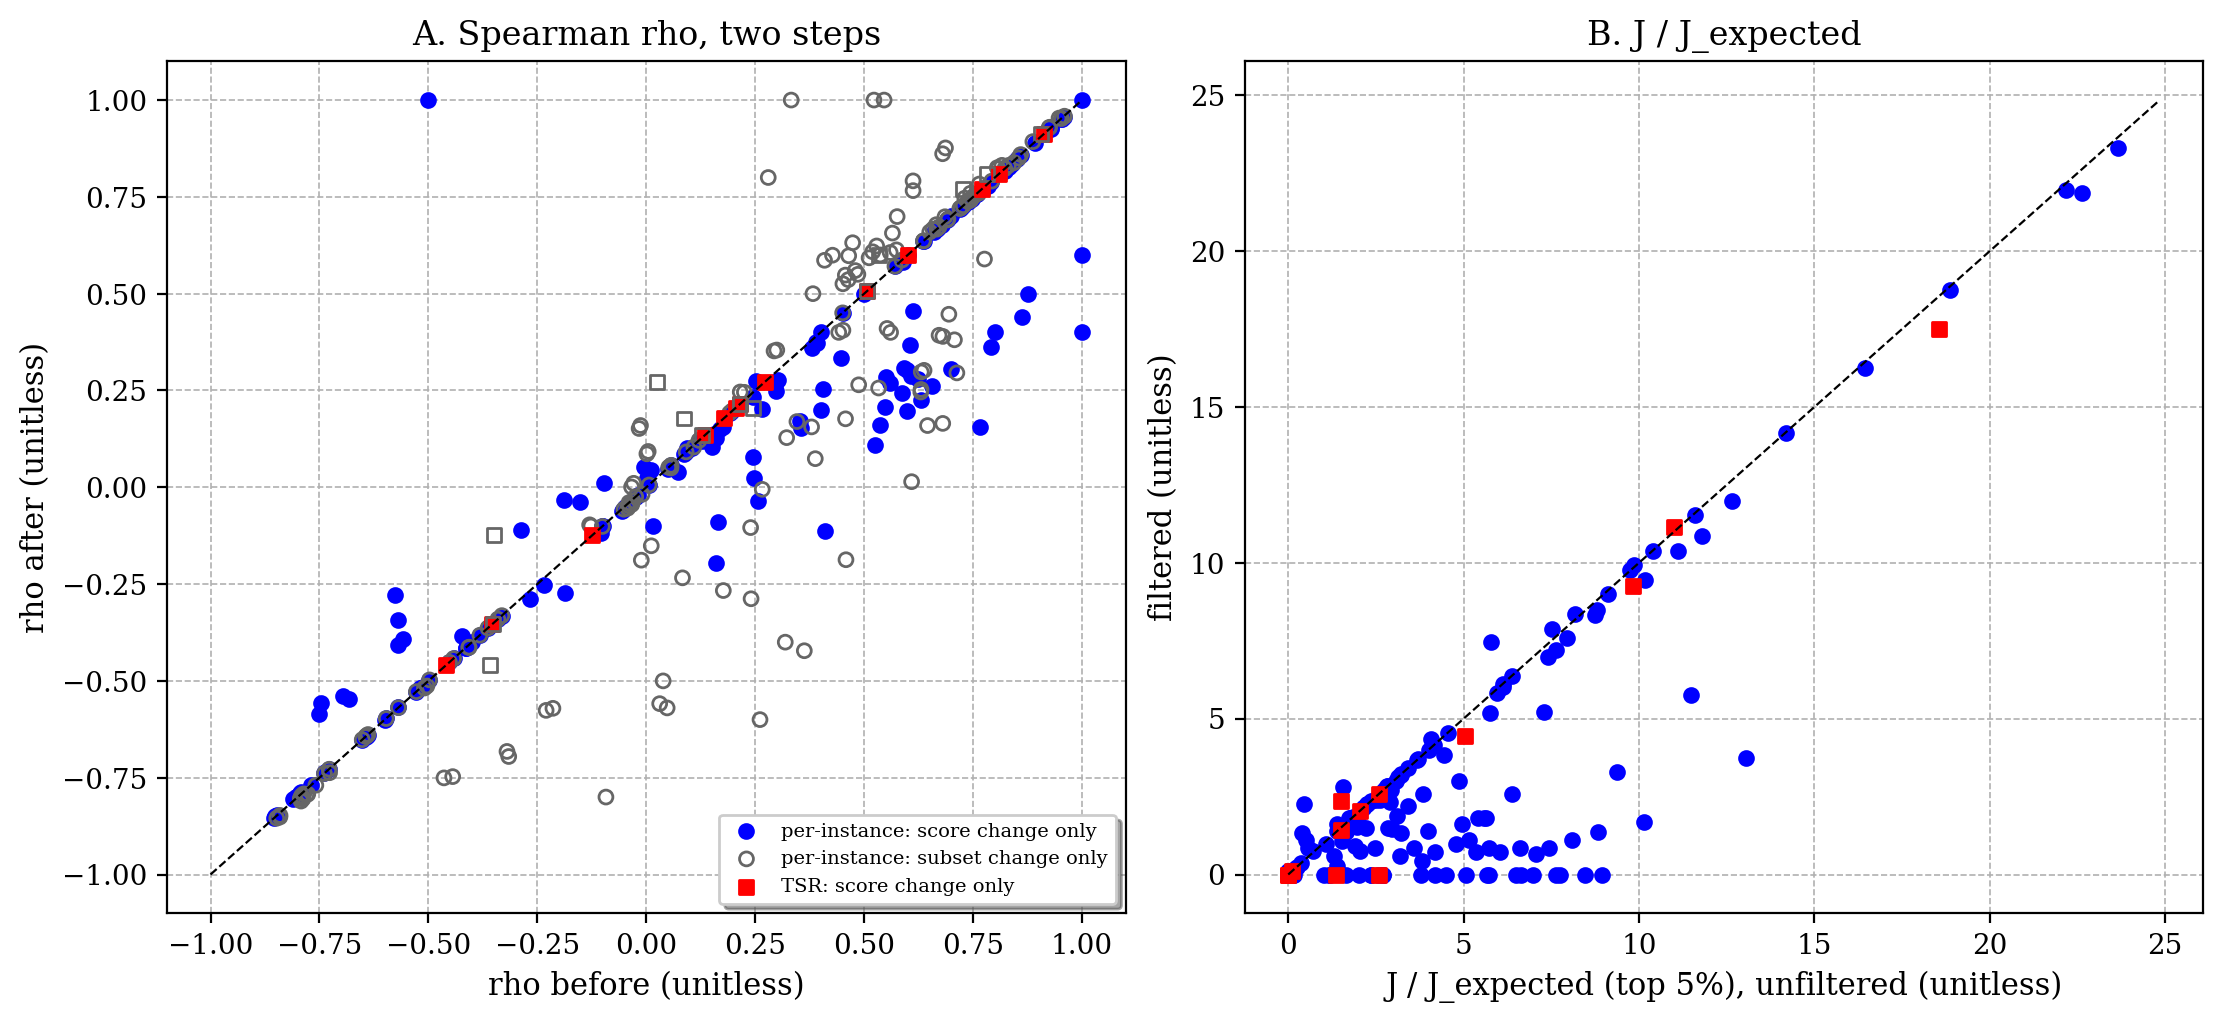

![Figure 7](../../../imgs/case_studies/cross_disease/cross_disease_unfiltered_vs_filtered_pvalue_filtered_bh05.png)

**Figure 7.** Each point is one (model, disease pair) of the six diseases (BH <= 0.05 filter). A: filled = filtered rho against the unfiltered rho on the same kept drugs (effect of the score recomputation), open = unfiltered rho on the kept drugs against the unfiltered rho on all shared drugs (effect of the drug subset); dashed line = no change. B: top-5% J / J_expected, filtered against unfiltered.

In [21]:
# side-by-side: same diseases, same models; unfiltered rho on the same kept drugs separates the subset effect from the score change
keysT = {}
for (family, slc), g in R.groupby(['family', 'model']):
    sc = g.pivot(index='drug_key', columns='disease', values='score')
    for a, b in combinations([d for d in DISEASES if d in sc.columns], 2):
        keysT[(slc, a, b)] = set(sc.index[sc[a].notna() & sc[b].notna()])
PUT = compute_pairs(RU, min_n=MIN_SHARED, only_keys=keysT).rename(columns={'spearman': 'spearman_unf_on_kept', 'ratio5pct': 'ratio5pct_unf_on_kept'})[['model', 'disease_a', 'disease_b', 'spearman_unf_on_kept', 'ratio5pct_unf_on_kept']]
cm = PU.merge(PF, on=['family', 'model', 'disease_a', 'disease_b'], suffixes=('_unf', '_filt')).merge(PUT, on=['model', 'disease_a', 'disease_b'], how='left')
cm['d_subset'] = cm['spearman_unf_on_kept'] - cm['spearman_unf']; cm['d_score'] = cm['spearman_filt'] - cm['spearman_unf_on_kept']
save(cm, 'unfiltered_vs_filtered_by_model_pair')
side = cm.groupby(['family', 'disease_a', 'disease_b']).agg(n_models=('model', 'size'), n_shared_unf=('n_shared_unf', 'median'), n_shared_filt=('n_shared_filt', 'median'),
                                                            rho_unf=('spearman_unf', 'median'), rho_unf_on_kept=('spearman_unf_on_kept', 'median'), rho_filt=('spearman_filt', 'median'),
                                                            d_subset=('d_subset', 'median'), d_score=('d_score', 'median'),
                                                            ratio5_unf=('ratio5pct_unf', 'median'), ratio5_filt=('ratio5pct_filt', 'median')).reset_index()
save(side, 'unfiltered_vs_filtered_summary')
show_table(side, f'Unfiltered vs filtered rankings on the same diseases and models (BH <= 0.05 filter), per family and disease pair, median over the models present in both (all cells; those with fewer than {N_MARK} shared drugs included): number of shared drugs (count of compounds); Spearman rho (unitless) of the unfiltered scores on all shared drugs (rho_unf), of the unfiltered scores restricted to the drugs kept by the filter (rho_unf_on_kept), and of the filtered scores (rho_filt); d_subset = rho_unf_on_kept - rho_unf is the change due to restricting rho to the kept drugs (range restriction: kept drugs are the highly profiled, significant tail), d_score = rho_filt - rho_unf_on_kept is the change due to recomputing the scores from the surviving instances; top-5% J / J_expected (unitless) unfiltered and filtered.', fmt='{:.2f}')
tc = cm[['family', 'model', 'disease_a', 'disease_b', 'n_shared_unf', 'n_shared_filt', 'spearman_unf', 'spearman_unf_on_kept', 'spearman_filt', 'ratio5pct_unf', 'ratio5pct_filt']]
show_table(tc, f'Per model and disease pair (all cells; n_shared_filt < {N_MARK} = few shared drugs): shared drugs (count of compounds), Spearman rho (unitless) unfiltered on all shared drugs, unfiltered on the kept drugs, and filtered; top-5% J / J_expected (unitless) unfiltered and filtered.', fmt='{:.2f}')
fig, axs = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for fam, mk in [('per-instance', 'o'), ('TSR', 's')]:
    d = cm[cm['family'] == fam]
    axs[0].scatter(d['spearman_unf_on_kept'], d['spearman_filt'], marker=mk, s=25, label=f'{fam}: score change only')
    axs[0].scatter(d['spearman_unf'], d['spearman_unf_on_kept'], marker=mk, s=25, facecolor='none', edgecolor='0.4', label=f'{fam}: subset change only' if fam == 'per-instance' else None)
    axs[1].scatter(d['ratio5pct_unf'], d['ratio5pct_filt'], marker=mk, s=25, label=fam)
axs[0].plot([-1, 1], [-1, 1], 'k--', lw=0.8); axs[0].set_xlabel('rho before (unitless)'); axs[0].set_ylabel('rho after (unitless)'); axs[0].set_title('A. Spearman rho, two steps')
lim_ = np.nanmax(cm[['ratio5pct_unf', 'ratio5pct_filt']].values) * 1.05
axs[1].plot([0, lim_], [0, lim_], 'k--', lw=0.8); axs[1].set_xlabel('J / J_expected (top 5%), unfiltered (unitless)'); axs[1].set_ylabel('filtered (unitless)'); axs[1].set_title('B. J / J_expected'); axs[0].legend(fontsize=7)
show_fig(fig, 'unfiltered_vs_filtered', 'Each point is one (model, disease pair) of the six diseases (BH <= 0.05 filter). A: filled = filtered rho against the unfiltered rho on the same kept drugs (effect of the score recomputation), open = unfiltered rho on the kept drugs against the unfiltered rho on all shared drugs (effect of the drug subset); dashed line = no change. B: top-5% J / J_expected, filtered against unfiltered.')

### 5.1 Configurations the filter changes

`mith` and `mith_pw` keep nearly all drugs (table of kept fractions above), so they are essentially unfiltered and dominate all-model averages; the configurations with a median kept fraction below 0.9 are the ones where the filter acts. The summary below uses only those configurations.

In [22]:
sel = cm[cm['model'].str.replace(r'_(sRGES|wsRGES|best|TSR)$', '', regex=True).isin(ACT)].copy()
sel['family_cfg'] = sel['family']
def fz(s): return float(np.tanh(np.arctanh(np.clip(s.values, -0.999999, 0.999999)).mean()))
t = sel.groupby(['family', 'disease_a', 'disease_b']).agg(n_models=('model', 'size'), models=('model', lambda s: ', '.join(sorted(set(s)))),
                                                          rho_unf=('spearman_unf', fz), rho_unf_on_kept=('spearman_unf_on_kept', fz), rho_filt=('spearman_filt', fz),
                                                          ratio5_unf=('ratio5pct_unf', 'median'), ratio5_filt=('ratio5pct_filt', 'median')).reset_index()
save(t.drop(columns='models'), 'filter_acting_configs_summary')
show_table(t.drop(columns='models'), f'Configurations where the filter acts ({", ".join(sorted(ACT))}): per family and disease pair, over the models present (all cells; those with fewer than {N_MARK} shared drugs included): number of models, Fisher-z mean Spearman rho (unitless) unfiltered, unfiltered on the kept drugs and filtered, and median top-5% J / J_expected (unitless) unfiltered and filtered.', fmt='{:.2f}')

**Table 41.** Configurations where the filter acts (DEG, DEG_LM, mith_LM): per family and disease pair, over the models present (all cells; those with fewer than 100 shared drugs included): number of models, Fisher-z mean Spearman rho (unitless) unfiltered, unfiltered on the kept drugs and filtered, and median top-5% J / J_expected (unitless) unfiltered and filtered.

| family | disease_a | disease_b | n_models | rho_unf | rho_unf_on_kept | rho_filt | ratio5_unf | ratio5_filt |
|---|---|---|---|---|---|---|---|---|
| TSR | IPF | ALS | 3 | 0.15 | 0.17 | 0.17 | 1.51 | 0.00 |
| TSR | asthma | ALS | 2 | -0.35 | -0.30 | -0.30 | 0.00 | 0.00 |
| TSR | asthma | IPF | 2 | 0.30 | 0.45 | 0.45 | 3.28 | 3.41 |
| per-instance | ALS | BRCA | 6 | 0.34 | 0.29 | 0.18 | 3.58 | 1.64 |
| per-instance | ALS | COAD | 5 | 0.05 | -0.33 | -0.30 | 1.03 | 0.86 |
| per-instance | ALS | LIHC | 6 | 0.34 | 0.30 | 0.19 | 3.92 | 1.02 |
| per-instance | BRCA | COAD | 5 | 0.54 | 1.00 | 0.91 | 7.42 | 0.86 |
| per-instance | BRCA | LIHC | 6 | 0.68 | 0.75 | 0.41 | 8.28 | 2.19 |
| per-instance | IPF | ALS | 6 | 0.32 | 0.34 | 0.20 | 2.56 | 1.56 |
| per-instance | IPF | BRCA | 6 | 0.59 | 0.56 | 0.27 | 6.55 | 1.04 |
| per-instance | IPF | COAD | 5 | 0.47 | 0.49 | 0.33 | 5.74 | 0.86 |
| per-instance | IPF | LIHC | 6 | 0.60 | 0.55 | 0.35 | 6.14 | 1.20 |
| per-instance | LIHC | COAD | 3 | 0.57 | 0.99 | 0.15 | 5.71 | 0.00 |
| per-instance | asthma | ALS | 6 | -0.23 | -0.60 | -0.47 | 0.14 | 0.00 |
| per-instance | asthma | BRCA | 6 | 0.12 | -0.12 | -0.08 | 1.67 | 0.90 |
| per-instance | asthma | COAD | 5 | 0.28 | -0.23 | 0.87 | 2.71 | 0.00 |
| per-instance | asthma | IPF | 6 | 0.34 | 0.19 | 0.08 | 3.50 | 1.42 |
| per-instance | asthma | LIHC | 6 | 0.26 | -0.12 | -0.12 | 1.77 | 0.46 |

### 5.2 Sensitivity to the offset assignment after filtering

For asthma, IPF, BRCA, LIHC and COAD, a second filtered ranking exists in which the dose/time offsets are kept at their unfiltered values (`*_pvalue_filtered_frozen_offsets.tsv`; for the cancers `tcga_wsRGES_per_drug_corrected_pvalue_filtered_frozen_offsets.tsv`); ALS has none, so its filtered ranking is used in both. The pairwise statistics are recomputed with these tables and compared with the main filtered tables.

In [23]:
fz_ = []
for dis, slug in CASES.items():
    p = conf.OOUT_DIR / 'case_studies' / slug / f'{slug}_drug_rankings_pvalue_filtered_frozen_offsets.tsv'
    if p.exists(): fz_.append(pd.read_csv(p, sep='\t', usecols=USE, low_memory=False).assign(disease=dis))
    else: fz_.append(R[R['disease'].astype(str) == dis][['model', 'config', 'collapse', 'drug_key', 'score', 'n_instances']].rename(columns={'model': 'ranking'}).assign(disease=dis))
if TCGA_TABLE_FROZEN is not None and Path(TCGA_TABLE_FROZEN).exists():
    fz_.append(tcga_rankings(TCGA_TABLE_FROZEN))
Xfz = pd.concat(fz_, ignore_index=True)
Xfz = Xfz[Xfz['collapse'].isin(COLL)].copy(); Xfz['score_type'] = Xfz['collapse'].map(COLL)
Xfz['family'] = np.where(Xfz['score_type'] == 'TSR', 'TSR', 'per-instance'); Xfz = Xfz.rename(columns={'ranking': 'model'})
PZ = compute_pairs(Xfz)
sv = PF.merge(PZ, on=['family', 'model', 'disease_a', 'disease_b'], suffixes=('_main', '_frozen'))
sv['d_rho'] = sv['spearman_frozen'] - sv['spearman_main']; sv['d_ratio5'] = sv['ratio5pct_frozen'] - sv['ratio5pct_main']
save(sv, 'frozen_offsets_sensitivity')
st = sv.groupby(['family', 'model']).agg(n_pairs=('d_rho', 'size'), max_abs_d_rho=('d_rho', lambda s: s.abs().max()), max_abs_d_ratio5=('d_ratio5', lambda s: s.abs().max())).reset_index()
st['changed'] = (st['max_abs_d_rho'] > 1e-9) | (st['max_abs_d_ratio5'] > 1e-9)
show_table(st[st['changed']] if st['changed'].any() else st.head(0), 'Models whose pairwise statistics differ between the filtered ranking and the filtered ranking with frozen offsets: largest absolute change over the disease pairs in Spearman rho (unitless) and in top-5% J / J_expected (unitless). Models not listed are identical.', fmt='{:.4f}')
display(Markdown(f'Over all {len(sv)} (model, pair) combinations, the largest absolute change in Spearman rho is {sv["d_rho"].abs().max():.4f} (median {sv["d_rho"].abs().median():.4f}) and in top-5% J / J_expected is {sv["d_ratio5"].abs().max():.3f} (median {sv["d_ratio5"].abs().median():.3f}); {int(st["changed"].sum())} of {len(st)} models differ at all.'))

**Table 42.** Models whose pairwise statistics differ between the filtered ranking and the filtered ranking with frozen offsets: largest absolute change over the disease pairs in Spearman rho (unitless) and in top-5% J / J_expected (unitless). Models not listed are identical.

| family | model | n_pairs | max_abs_d_rho | max_abs_d_ratio5 | changed |
|---|---|---|---|---|---|
| per-instance | DEG_sRGES | 15 | 0.2628 | 2.5086 | True |
| per-instance | DEG_wsRGES | 15 | 1 | 0.8681 | True |
| per-instance | mith_LM_sRGES | 14 | 1.5000 | 1.7143 | True |
| per-instance | mith_LM_wsRGES | 10 | 0.1121 | 1.5029 | True |
| per-instance | mith_pw_sRGES | 15 | 0.0010 | 0.2759 | True |
| per-instance | mith_pw_wsRGES | 15 | 0.0009 | 0.1504 | True |
| per-instance | mith_sRGES | 15 | 0.0001 | 0.0000 | True |
| per-instance | mith_wsRGES | 15 | 0.0001 | 0.0501 | True |

Over all 186 (model, pair) combinations, the largest absolute change in Spearman rho is 1.5000 (median 0.0000) and in top-5% J / J_expected is 2.509 (median 0.000); 8 of 17 models differ at all.

## 6. Summary of the numbers

In [24]:
lines = []
for fam in ['per-instance', 'TSR']:
    for c in cls_order:
        v = S[(S['family'] == fam) & (S['variant'] == 'all') & (S['pair_class'] == c)]['spearman']
        j = J[(J['family'] == fam) & (J['variant'] == 'all') & (J['pair_class'] == c) & (J['k_label'] == '100')]
        if len(v): lines.append(f'- {fam}, {c}: Spearman rho median {v.median():.2f} (range {v.min():.2f} to {v.max():.2f}, n = {len(v)} model-pairs); top-100 Jaccard median {j["jaccard"].median():.3f} vs null {j["jaccard_null"].median():.4f}.')
pw = S[(S['variant'] == 'all') & (S['config'] == 'mith_pw')]
lines.append(f'- Methods with configuration `mith_pw`: median rho over all model-pairs {pw["spearman"].median():.2f}, against {S[(S["variant"] == "all") & (S["config"] != "mith_pw")]["spearman"].median():.2f} for the other configurations.')
FA = ['DEG', 'mith_LM']   # per-instance configurations where the filter acts (median kept fraction < 0.9)
fa = S[(S['variant'] == 'all') & (S['family'] == 'per-instance') & (S['config'].isin(FA))]
for c in cls_order:
    v = fa[fa['pair_class'] == c]
    if len(v) >= 3: lines.append(f'- Filter-acting configurations only ({", ".join(FA)}; all cells, including those with fewer than {N_MARK} shared drugs), per-instance, {c}: Spearman rho median {v["spearman"].median():.2f} (range {v["spearman"].min():.2f} to {v["spearman"].max():.2f}, n = {len(v)} model-pairs).')
    else: lines.append(f'- Filter-acting configurations only ({", ".join(FA)}; all cells), per-instance, {c}: fewer than 3 cells, listed instead (model, pair, shared drugs, rho): ' + ('; '.join(f'{r.model} {r.disease_a}-{r.disease_b} n={r.n_shared} rho={r.spearman:.2f}' for r in v.itertuples()) or 'none') + '.')
lines.append(f'- The all-model medians above include `mith` and `mith_pw` cells, which the filter leaves essentially unfiltered; the filter-acting-only medians describe the configurations the filter changes.')
nf = PM.groupby('family').apply(lambda d: f'flagged per model median {d["flagged_observed"].median():.0f} (permutation null median {d["flagged_null_mean"].median():.1f})', include_groups=False)
lines += [f'- Drugs flagged per model, {k}: {v}.' for k, v in nf.items()]
display(Markdown('\n'.join(lines)))

- per-instance, cancer-cancer: Spearman rho median 0.14 (range -0.64 to 1.00, n = 32 model-pairs); top-100 Jaccard median 0.015 vs null 0.0041.
- per-instance, cancer vs non-cancer: Spearman rho median 0.15 (range -0.85 to 1.00, n = 105 model-pairs); top-100 Jaccard median 0.020 vs null 0.0042.
- per-instance, non-cancer: Spearman rho median 0.13 (range -0.60 to 0.96, n = 36 model-pairs); top-100 Jaccard median 0.031 vs null 0.0089.
- TSR, non-cancer: Spearman rho median 0.22 (range -0.46 to 0.91, n = 13 model-pairs); top-100 Jaccard median 0.058 vs null 0.0184.
- Methods with configuration `mith_pw`: median rho over all model-pairs 0.38, against 0.15 for the other configurations.
- Filter-acting configurations only (DEG, mith_LM; all cells, including those with fewer than 100 shared drugs), per-instance, cancer-cancer: Spearman rho median 0.36 (range -0.20 to 1.00, n = 14 model-pairs).
- Filter-acting configurations only (DEG, mith_LM; all cells, including those with fewer than 100 shared drugs), per-instance, cancer vs non-cancer: Spearman rho median 0.17 (range -0.80 to 1.00, n = 51 model-pairs).
- Filter-acting configurations only (DEG, mith_LM; all cells, including those with fewer than 100 shared drugs), per-instance, non-cancer: Spearman rho median 0.07 (range -0.58 to 0.30, n = 18 model-pairs).
- The all-model medians above include `mith` and `mith_pw` cells, which the filter leaves essentially unfiltered; the filter-acting-only medians describe the configurations the filter changes.
- Drugs flagged per model, TSR: flagged per model median 14 (permutation null median 12.7).
- Drugs flagged per model, per-instance: flagged per model median 0 (permutation null median 0.6).

## 7. Limits

- A low cross-disease correlation is not by itself an advantage of a method: a method returning noise would also correlate 0 across diseases and would look the most disease-specific.
  The informative second half of the test is a high concordance between two independent datasets of the same disease, which are not available here; the comparison above
  therefore describes how much of each ranking is shared across diseases, not which method is better.
- The TSR and per-instance routes differ in the drug collapse and in the LINCS instance pool (level 3 vs gold-set level 5), so family-level differences mix both effects.
- The three TCGA diseases share the signature pipeline and the same LINCS pool, and their wsRGES weights come from TCGA tumours vs DepMap lines (the other diseases: their own samples); the p-value filter is applied per CS run in the same way to all six diseases. Where the filter keeps few instances of a configuration in a cancer, the models are small or empty there (tables of section 5).
- Pairs differ in the number of shared drugs and, for TSR, in the number of models (an empty ranking removes a model from the pairs of that disease); the DEG family of the per-instance models is `DEG` alone.
- Filtered vs unfiltered comparisons mix two effects: the filter keeps the highly profiled, significant tail of the drugs, so rho of the filtered rankings is computed on a restricted range of CS (range restriction), and the scores of the kept drugs are recomputed from the surviving instances. The unfiltered rho on the same kept drugs separates the two (section 5); the change from restriction alone has either sign.
- No cell is excluded for its number of shared drugs (minimum 3, for a Spearman rho); cells with fewer than `N_MARK` (100) are hatched in the grid figures and listed in section 5, and pairs with COAD or LIHC can rest on few drugs in the `DEG` and `mith_LM` models.
- `mith` and `mith_pw` are essentially unfiltered, so all-model averages mostly describe unfiltered configurations; the configurations where the filter acts are summarised in section 5.1.
- The stratified null of the significant-set Jaccard conditions on n_instances only; other determinants of retention (CS magnitude, cell-line coverage) are not modelled.
- The filter removes drugs by a significance criterion that depends on the number of instances of each drug; shared-drug sets and top-k sets are therefore selected, and the hypergeometric null of the top-k Jaccard uses the number of shared drugs of the filtered rankings.
- Shared drugs differ between pairs and models (range stated in the table captions); the Jaccard null uses the n of each pair.
- Thresholds of the flag (`MEAN_MAX`, `SD_MAX`, `FLAG_FRAC`) are descriptive choices; the permutation null (independent diseases, 1000 permutations) does not test drug-specific behaviour, and the TCGA diseases are not independent.